# From partitions to traces: the curve mesh

This notebook continues [the partition notebook](../partition/partition.ipynb) and explains the rest of the mesh layout: how each partition is filled with a closed **space-filling curve**, and how the curve becomes the mesh's traces. It ports the algorithm (`src/yanartas_pillowbox/sfc.py` and its Rust core, `rust/core/src`) to Python and checks the port against the original's recorded results (`mesh_cases.json`, written by `export_mesh_cases.py`).

> **What the first notebook produces.** A layer's mesh area is split into `N` partitions of equal area. Each partition is a polygon that holds its **port** (a square at the cable junction, two trace lanes wide), its **strip** (a straight lane from the port into the area), and its share of the area beyond. It also carries its **reach**: how far in from the port the strip ends, which is where the partition's curve opens. Partition borders are kept like folds: no curve crosses them. This notebook starts from those partitions.

Generic operations (vector arithmetic, a point grid, polygon tests, the random stream, a textbook matching algorithm, plotting) live in the `support/` modules next to this notebook. The notebook itself holds the algorithm.

In [1]:
from __future__ import annotations  # (as the original modules: annotations not evaluated)

import ast
import itertools
import math
import sys
import time
from collections import deque
from collections.abc import Sequence
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import shapely
from shapely.geometry import LineString, Polygon

from support import closed, poly
from support.chacha import Rng
from support.data import arr, geom, load, pts
from support.graphs import SortedSet, Union
from support.graphs import matching as max_matching
from support.pkg import (DOWN, LEFT, RIGHT, UP, Grid, Mesh, MeshError, Piece, Point, Rand,
                         checkpoint, matching, progress, resample, sample_arcs)
from support.plotting import (BASE, CHANGED, CURVE, FOLD, GRAPH, PALETTE, STEM, TRACE, base, fill,
                              legend, line, lines, rings, zoom)
from support.spatial import Grid as PointGrid
from support.spatial import Segs, Zones, crossing, ray_hit
from support.vec import (add, as_usize, clamp, closest, cross, crosses, dist, dot, max_by, min_by,
                         norm, rem_euclid, rround, scale, signum, sub)
from support.vec import resample as resample_line

DATA = load("mesh_cases.json")
CASES = DATA["by_name"]
for c in DATA["cases"]:
    print(f"{c['name']:>11}: {c['note']}")

        one: one partition, one panel: the whole pipeline at its simplest
       fold: one partition over two panels: their curves joined across the fold
 partitions: two partitions over two panels: two curves, stems side by side
       hole: a mounting hole in the panel: cells clipped round it, the curve round it
       arcs: the fold case drawn in lines and arcs (arc fitting instead of smoothing)


**The support modules** (each a port of a basic part of the core, or of the package):

| module | what | from |
|---|---|---|
| `support.vec` | points as `(x, y)`, vector arithmetic, nearest point on a segment, resampling; Rust's rounding, `hypot` and tie-breaking rules | `geom.rs` |
| `support.spatial` | a bucket grid of points (`PointGrid`), segments bucketed by cell (`Segs`), self-crossings of a closed polyline, which zone a point is in | `grid.rs`, `segs.rs`, `zones.rs` |
| `support.poly` | polygons as rings: area, centroid, containment, distances; clipping (with shapely) | `poly.rs` |
| `support.closed` | closed polylines: Laplacian, Taubin smoothing, curvature, normals, resampling, a Catmull–Rom spline | `closed.rs` |
| `support.chacha` | the ChaCha20 random stream the graph draws from | `graph.rs` (`Rng`) |
| `support.graphs` | Edmonds' blossom matching, union–find, a sorted set | `graph.rs` |
| `support.pkg` | what `sfc.py` imports from the package (`Mesh`, `matching`, `resample`, `Rand`, …), copied verbatim; no-op progress and checkpoints | `mesh.py`, `rand.py` |
| `support.data`, `support.plotting` | loading the recording; the plots' look | — |

**Naming.** `sfc.py` and the core both have functions called `matching`, `resample` and `Grid`. Here `sfc.py`'s keep those names, and the core's are `max_matching` (Edmonds), `resample_line` and `PointGrid`.

**Exactness.** The helpers keep the core's order of floating-point operations and its tie-breaking: libm's `hypot`, Rust's rounding of halves, `max_by` keeping the last maximum, sorted-set iteration. So the port reproduces the core's results bit for bit wherever its inputs are the same.

**Colours** used throughout:

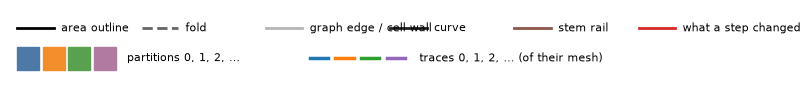

In [2]:
fig, ax = plt.subplots(figsize=(10, 0.9))
ax.axis("off")
items = [("area outline", "black", "-"), ("fold", FOLD, "--"), ("graph edge / cell wall", GRAPH, "-"),
         ("curve", CURVE, "-"), ("stem rail", STEM, "-"), ("what a step changed", CHANGED, "-")]
for i, (label, color, ls) in enumerate(items):
    ax.plot([i * 1.7, i * 1.7 + 0.5], [0, 0], color=color, ls=ls, lw=2)
    ax.text(i * 1.7 + 0.6, 0, label, va="center", fontsize=8)
for k in range(4):
    ax.add_patch(plt.Rectangle((k * 0.35, -0.9), 0.3, 0.5, color=PALETTE[k]))
    ax.plot([k * 0.35 + 4.0, k * 0.35 + 4.25], [-0.65, -0.65], color=TRACE[k], lw=2.5)
ax.text(1.5, -0.65, "partitions 0, 1, 2, …", va="center", fontsize=8)
ax.text(5.5, -0.65, "traces 0, 1, 2, … (of their mesh)", va="center", fontsize=8)
ax.set_xlim(-0.1, 10.5)
ax.set_ylim(-1.1, 0.4)
plt.show()

## 1. The problem

**Inputs** (one layer): the mesh area (`mask`) and its panels (`zones`); the partitions from the first notebook, each with its port and reach; `n` traces per partition and their `pitch` (trace width plus space); and a `seed`.

**Output**: a `Mesh` with `n` traces per partition. Each trace is a polyline that leaves its partition's port, covers the partition, and comes back to the port. Together, a partition's `n` traces are offsets of one closed curve, so they run side by side like a ribbon.

**Constraints**

1. **Clearance.** No two traces come nearer than the pitch, and a trace never comes nearer than half a pitch to the area's edge.
2. **Coverage.** No hole wider than about one ribbon is left bare. An attacker's drill must hit a trace.
3. **One loop per trace**, out of and back into its exit, with its two ends at the pitch in the exit's row.
4. **Folds crossed rarely.** Each crossing of a fold is stressed when the box is folded, so each panel is filled on its own and the panels are joined as seldom as possible.
5. **Matched lengths.** A partition's traces should be of nearly equal length, because the monitor compares them in pairs.

**Why it is hard.** A closed curve that fills an area at an even spacing is a global object: one cycle through every part of the area. A grid-based construction leaves visible structure and long parallel runs. This method instead builds the curve on a random cell graph, turns it into a single cycle by local surgery, and relaxes its geometry. Then come the ribbon's own problems: offsets of a curve loop back on themselves in tight bends, and leave gaps where two runs part.

The approach follows Bedel et al., *Closed space-filling curves with controlled orientation for 3D printing* (Computer Graphics Forum 41(2), 2022), with changes for a ribbon of traces.

Below, one case before (the partitions) and after (the original implementation's traces).

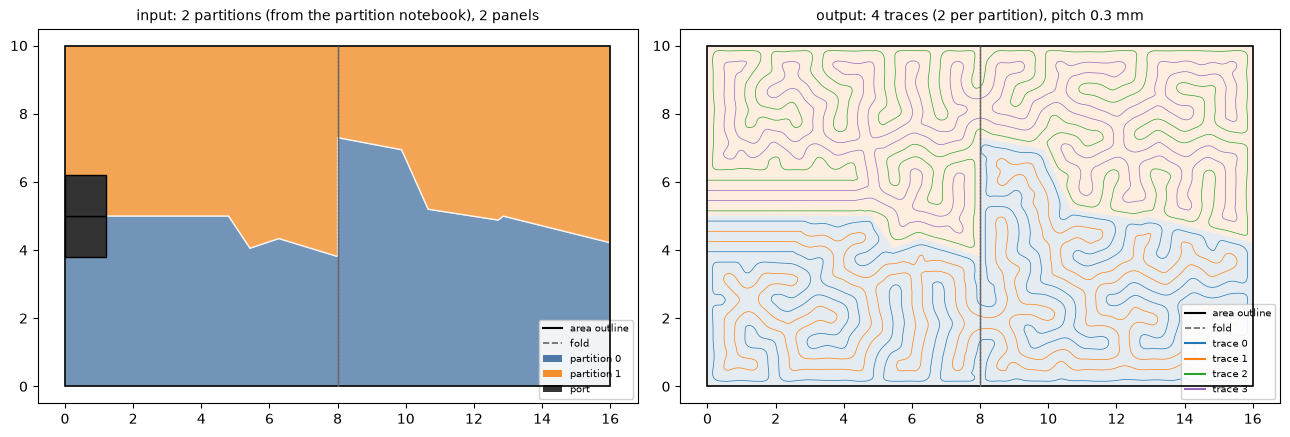

In [3]:
def show_partitions(ax, c, title):
    i = c["input"]
    for k, p in enumerate(c["partitions"]):
        fill(ax, geom(p["area"]), facecolor=PALETTE[k], edgecolor="white", alpha=0.8, zorder=2)
        fill(ax, geom(p["port"]), facecolor="#333333", zorder=3)
    base(ax, geom(i["mask"]), [geom(z) for z in i["zones"]], title)


def show_mesh(ax, c, traces, title, lw=0.5):
    i = c["input"]
    for k, p in enumerate(c["partitions"]):
        fill(ax, geom(p["area"]), facecolor=PALETTE[k], edgecolor="none", alpha=0.15, zorder=1)
    for t, tr in enumerate(traces):
        line(ax, tr, color=TRACE[t % len(TRACE)], lw=lw, zorder=3)
    base(ax, geom(i["mask"]), [geom(z) for z in i["zones"]], title)


c = CASES["partitions"]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6))
show_partitions(a, c, "input: 2 partitions (from the partition notebook), 2 panels")
legend(a, BASE + [("patch", PALETTE[0], "partition 0"), ("patch", PALETTE[1], "partition 1"),
                  ("patch", "#333333", "port")], loc="lower right")
show_mesh(b, c, c["mesh"]["traces"], f"output: {len(c['mesh']['traces'])} traces (2 per partition), pitch 0.3 mm")
legend(b, BASE + [("line", TRACE[k], f"trace {k}") for k in range(4)], loc="lower right")
plt.tight_layout()
plt.show()

## 2. Overview

```
generate(mask, exits, side, n, pitch, seed, zones, arcs, partitions, stems)
│
├─ 3.1  frame, exits, stems     turn the board so the exits open upward; cut out the stems
├─ 3.2  regions                 each partition's piece of each panel (split at necks)
├─ 3.3  segments, borders       each region shrunk by half a spacing; borders between regions
│
├─ the curve's graph (Rust core: graph::curve)
│   3.4  cells                  centroidal Voronoi cells per segment (Lloyd), a pin at each exit
│   3.5  graph, stem            the cells' walls as a planar graph; the exit's edge fixed
│   3.6  initial cycles         the edges a perfect matching leaves out: disjoint cycles
│   3.7  refinement             a vertex at each cell's centre, threaded into a cycle
│   3.8  merging                cycles joined by split-and-reconnect, then doubled edges
│   3.9  zoning                 the segments' cycles joined across borders along a spanning tree
│   3.10 the curve              walked from the stem round; fallbacks for regions left out
│
├─ 3.11 relaxation (curve::relax)   even spacing (CVT), grown into the gaps, runs pushed apart
├─ 3.12 lanes (lanes::lanes)        the n traces as offsets of the curve; loops cut; opened at the exit
├─ 3.13 settling (settle::settle)   each trace moved into the middle of its room   [simplified]
└─ 3.14 drawing (arcs::*)           smooth polylines, or lines and circular arcs
```

The Rust core does steps 3.4–3.14 except the bookkeeping. `sfc.py` drives it and does the geometry that needs shapely. The port runs `sfc.py`'s own functions (copied verbatim) on top of Python ports of the core's steps.

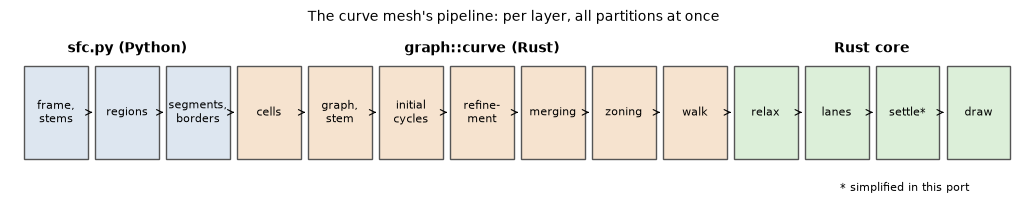

In [4]:
fig, ax = plt.subplots(figsize=(13, 2.4))
ax.axis("off")
groups = [("sfc.py (Python)", ["frame,\nstems", "regions", "segments,\nborders"], "#DDE6F0"),
          ("graph::curve (Rust)", ["cells", "graph,\nstem", "initial\ncycles", "refine-\nment", "merging", "zoning", "walk"], "#F6E3CF"),
          ("Rust core", ["relax", "lanes", "settle*", "draw"], "#DCEFD9")]
x = 0
for name, steps, color in groups:
    x0 = x
    for s in steps:
        ax.add_patch(plt.Rectangle((x, 0), 0.9, 1, facecolor=color, edgecolor="#555"))
        ax.text(x + 0.45, 0.5, s, ha="center", va="center", fontsize=8)
        if x > 0:
            ax.annotate("", xy=(x, 0.5), xytext=(x - 0.1, 0.5), arrowprops=dict(arrowstyle="->", lw=0.8))
        x += 1
    ax.text((x0 + x - 0.1) / 2, 1.15, name, ha="center", fontsize=10, weight="bold")
ax.text(x - 2.5, -0.35, "* simplified in this port", fontsize=8)
ax.set_xlim(-0.2, x)
ax.set_ylim(-0.6, 1.4)
ax.set_title("The curve mesh's pipeline: per layer, all partitions at once", fontsize=10)
plt.show()

## 3. The port, step by step

### 3.0 Constants

`sfc.py`'s constants, verbatim. The core receives them as parameters, so Python stays their single source. The `SETTLE*` and `MATCH*` constants belong to the settling step.

In [5]:
SPACING = 1.0  # the curve's target spacing, in multiples of its least (n pitches)
SEED_SPACING = 1.4  # the CVT seeds' spacing, in target spacings (the cycle comes out sparser)
LLOYD = 6  # Lloyd iterations of the seeds
LLOYD_CURVE = 20  # CVT steps of the curve
SPREAD = 1.3  # the traces spread over at most this many target spacings
SMOOTH = 10  # the pitch of the traces smoothed over this many vertices either way
GAIN = 3.0  # the Laplacian weight per relative excess length
REPAIR = 100  # steps pushing runs apart (at most)
WINDOW = 1.5  # parts of the curve nearer than this many least spacings along it: one run
FINE = 4  # the traces offset from the curve split this many times finer
RAMP = 3  # ... ramped in over this many vertices off the stem
MARGIN = 0.02  # ... at a pitch this much above the least (but at the exit)
SIMPLIFY = 0.002  # the traces simplified within this (mm; well within the margin)
LOOP = 3.0  # loops the traces' offsets leave in tight bends: cut out up to this many spacings long
ARCS = 0.002  # drawn in lines and arcs (``arcs``): within this of the traces (mm)
ARCS_ROOM = 0.03  # ... and where they have room, up to this many pitches
MAX_TURN = math.radians(10)  # drawn, no two segments turn more than this from one another
TURN_GIVE = 0.0  # ... where smoothing costs no more than this share of the pitch in space
INSIDE = 0.9  # traces inside a bend keep within this share of its radius
PUSH_MARGIN = 1.04  # runs closer than this many times their least spacing: pushed apart
BEND_SLACK = 0.85  # bends this much tighter than the tightest: smoothed (U-turns sit at it)
GROW = 150  # steps growing the curve into the room left between its runs (at most)
REACH = 1.06  # ... runs nearer than this many least spacings repel each other
GROW_RATE = 0.5  # ... the share of the room a bend bulges into per step
HARD = 10  # repair steps before bends still too sharp are smoothed the hard way
STALL = 10  # ... until it has grown less than 0.2 % over this many steps
STRAIGHT = 0.1  # bends gentler than this many least spacings' curvature: straight (skew)
SETTLE = 40  # steps settling each trace into the middle of the room either side of it
SETTLE_RATE = 0.5  # ... the share of the way there a step goes
SETTLE_REACH = 3.0  # ... copper looked for this many pitches out (beyond: a hole, moved into)
SETTLE_PIN = 1.5  # ... bends tighter than this many pitches' radius do not move inwards
SETTLE_COOL = 2.0  # ... the moves dying down over the steps as (1 - step / steps) to this
SETTLE_STEP = 0.35  # ... the traces held at this many pitches between vertices
SETTLE_STILL = 0.005  # ... moves shorter than this many pitches: none
SETTLE_BAND = 1.0  # ... traces within this many pitches of length of each other: not steered
SETTLE_LEAP = 0.34  # ... a vertex moved at most this many of the steps between vertices
SETTLE_TUNE = 3.0  # ... a trace this many pitches short (or long): steered at full strength
SETTLE_STEER = 0.6  # ... the share of its bends' depth a step grows (or straightens) them by
SETTLE_SPAN = 25  # ... (where along the curve it gains more, over this many places)
SETTLE_STEER_COOL = 2.0  # ... (the steering dying down as the moves, to this)
SETTLE_TIP = 1.0  # ... U-turns tighter than this many pitches per trace's radius: tips
SETTLE_REACH_OUT = 1.0  # ... leaning out along their axis by this share of the room
SETTLE_FILL = 2.0  # ... down the slope of the traces' density (into holes) by this much
SETTLE_FILL_BLUR = 0.5  # ... (the density blurred over this many pitches per trace)
SETTLE_RIBBON = 0  # ... (the density blurred as for this many traces abreast; 0: a pair)
SETTLE_SHARE = 0  # ... a trace's own copper across, the room its pair's legs': theirs (0: off)
SETTLE_HOLE = 1.0  # then holes this many pitches from copper and more filled, each alone (0: none)
SETTLE_HOLE_STEPS = 160  # ... by this many steps' settling of the pairs round it, room shared
SETTLE_HOLE_MARGIN = 4.0  # ... in a box this many pitches wider than the hole
SETTLE_HOLE_RIBBON = 4  # ... the density blurred there as for this many traces abreast
SETTLE_BEND = 2  # ... the bends it grows (or straightens): this many vertices either way
SETTLE_SMOOTH = 3  # ... jitter smoothed this many times a step
SETTLE_FINISH = 10  # ... then all smoothed this many times (kept clear)
SCALE = 4  # ... (the steps and the tips' lean for this many traces; more: in proportion)
MATCH = 20  # steps matching the settled traces' lengths (taking it out of the longer)
MATCH_BAND = 15.0  # ... no trace more than this many pitches longer than the shortest
MATCH_RATE = 0.5  # ... the share of their bends' depth a step straightens them by, at most
ATTEMPTS = 8  # tries with fresh seeds when a graph comes out degenerate
STEM_MARGIN = 0.25  # the area kept this many pitches further off a longer stem beside it

### 3.1 Frame, exits and stems

`generate` first turns the board into a **frame** in which the exit cells' open side is the top (−y). For exits on the left, as in these cases, that swaps x and y. All later steps work in this frame, and so do the plots below (y axis pointing down, exits at the top). Then, for each partition:

- Its **exit cell** is a square `2 n` pitches wide at its port.
- Its **stem** is two straight rails a run's spacing apart, from the exit up to `top`, the strip's reach. The traces run along the rails at exactly the pitch.
- The leads' corridor beyond the exit, and the stems themselves, are cut out of the area, so no curve runs there.
- Beside a longer stem, a little more is cut away (`STEM_MARGIN`), so that a curve running on along it has room for its traces.
- The stem's two ends are the **opening** where the partition's closed curve starts and ends.

The curve's **spacing** (distance between neighbouring runs) is `n · pitch`: room for one run's `n` traces at the pitch.

`generate` is the driver of everything below. Its code is shown in full in 3.15; here only its frame.

In [6]:
class _Frame:
    """A frame in which the exit cell's open side is its top (-y) side: the given side
    turned or mirrored there."""

    def __init__(self, side: int) -> None:
        self.side = side

    def fwd(self, xy: np.ndarray) -> np.ndarray:
        x, y = xy[:, 0], xy[:, 1]
        if self.side == UP:
            return np.stack([x, y], 1)
        if self.side == DOWN:
            return np.stack([x, -y], 1)
        if self.side == LEFT:
            return np.stack([y, x], 1)
        return np.stack([y, -x], 1)  # RIGHT

    def inv(self, xy: np.ndarray) -> np.ndarray:
        x, y = xy[:, 0], xy[:, 1]
        if self.side == UP:
            return np.stack([x, y], 1)
        if self.side == DOWN:
            return np.stack([x, -y], 1)
        if self.side == LEFT:
            return np.stack([y, x], 1)
        return np.stack([-y, x], 1)

    def geom(self, g: shapely.Geometry) -> shapely.Geometry:
        return shapely.transform(g, self.fwd)


def _polygons(g: shapely.Geometry) -> list[Polygon]:
    return [p for p in shapely.get_parts(g) if isinstance(p, Polygon) and not p.is_empty]


def _rings(g: shapely.Geometry) -> list[shapely.LinearRing]:
    return [r for poly in _polygons(g) for r in (poly.exterior, *poly.interiors)]


def _lines(g: shapely.Geometry) -> list[LineString]:
    return [p for p in shapely.get_parts(g) if isinstance(p, LineString) and p.length > 0]

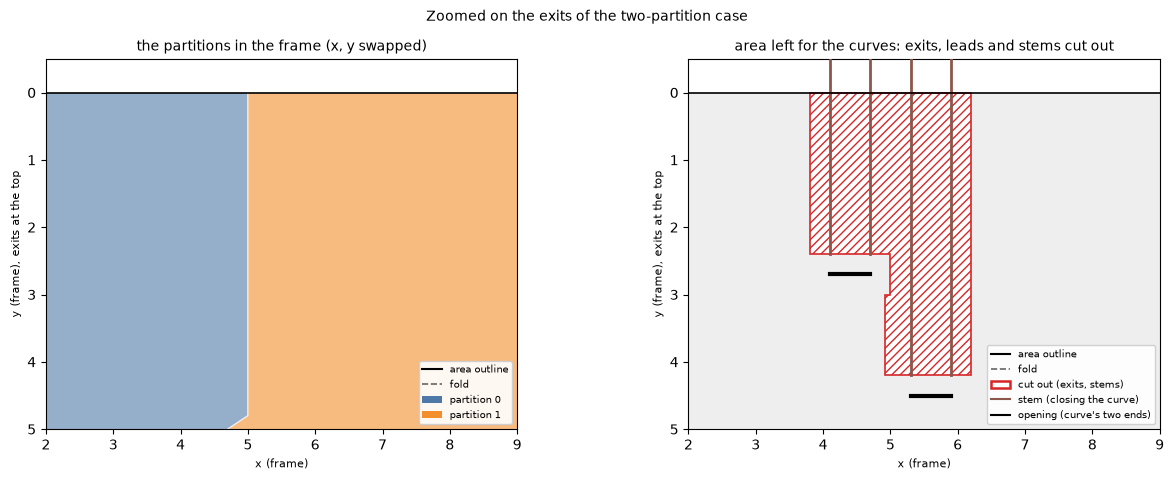

In [7]:
def frame_geoms(c):
    """The case's geometry in generate's frame: the mask, panels and partitions turned."""
    i = c["input"]
    fr = _Frame(i["side"])
    return fr, fr.geom(geom(i["mask"])), [fr.geom(geom(z)) for z in i["zones"]], \
        [fr.geom(geom(p["area"])) for p in c["partitions"]]


def frame_axes(ax):
    ax.invert_yaxis()
    ax.set_xlabel("x (frame)", fontsize=8)
    ax.set_ylabel("y (frame), exits at the top", fontsize=8)


c = CASES["partitions"]
fr, fmask, fzones, fparts = frame_geoms(c)
area = geom(c["settle"]["area"])  # (generate's area, as the stems and leads left it)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.8))
for k, p in enumerate(fparts):
    fill(a, p, facecolor=PALETTE[k], edgecolor="white", alpha=0.6, zorder=2)
base(a, fmask, fzones, "the partitions in the frame (x, y swapped)")
frame_axes(a)
fill(b, area, facecolor="#EEEEEE", edgecolor="none", zorder=1)
removed = fmask.difference(area)
fill(b, removed, facecolor="none", edgecolor=CHANGED, lw=1.2, hatch="////", zorder=4)
for r in c["relax"]:
    line(b, r["stem"], color=STEM, lw=2, zorder=5)
for gr in c["graphs"][:1]:
    for o0, o1 in gr["openings"]:
        line(b, [o0, o1], color="black", lw=3, zorder=6)
base(b, fmask, fzones, "area left for the curves: exits, leads and stems cut out")
frame_axes(b)
for ax in (a, b):
    ax.set_xlim(2, 9)
    ax.set_ylim(5, -0.5)
legend(a, BASE + [("patch", PALETTE[0], "partition 0"), ("patch", PALETTE[1], "partition 1")], loc="lower right")
legend(b, BASE + [("edge", CHANGED, "cut out (exits, stems)"), ("line", STEM, "stem (closing the curve)"),
                  ("line", "black", "opening (curve's two ends)")], loc="lower right")
plt.suptitle("Zoomed on the exits of the two-partition case", fontsize=10)
plt.tight_layout()
plt.show()

### 3.2 Regions

Each partition's area is cut into its pieces in each panel: the **regions**. Each region gets a curve section of its own; the sections are joined across the borders between regions later (3.9). Regions too small to take a curve are dropped.

A region whose **domain** (the region shrunk by half a spacing, where its curve's centre line may run) comes apart is cut there by `_split`. Otherwise the core would lay out each piece of the domain on its own, join neither, and leave all but one bare. In these cases nothing is split, so the plot shows the plain regions. The check below recomputes them from `generate`'s area and compares them with the recording.

In [8]:
def _regions(
    area: shapely.Geometry, zones: list[Polygon], least: float, spacing: float = 0.0
) -> list[Polygon]:
    """The area cut into the zones' pieces (and what no zone covers), pieces too small to
    take a curve left out; with ``spacing``, each also cut where its domain (shrunk by half
    a spacing, where its curve runs) comes apart (``_split``)."""
    out: list[Polygon] = []
    rest = area
    for z in zones:
        out += _polygons(shapely.intersection(area, z))
        rest = shapely.difference(rest, z)
    out += _polygons(rest)
    if spacing > 0:
        out = [q for r in out for q in _split(r, spacing)]
    return [r for r in out if r.area >= least]


def _split(region: Polygon, spacing: float) -> list[Polygon]:
    """The region cut where its domain comes apart (at a neck narrower than a spacing, or a
    crack along a seam): a piece round each piece of the domain, the largest first, what
    lies within half a spacing of it; a region of its own each, so that the curve joins them
    across their border as any two regions' (else the core lays each out apart, joins
    neither to the other, and leaves all but the stem's bare)."""
    domains = sorted(
        (d for d in _polygons(region.buffer(-spacing / 2)) if d.area >= spacing**2),
        key=lambda d: -d.area,
    )
    if len(domains) < 2:
        return [region]
    out = []
    rest = region
    for d in domains:
        piece = shapely.intersection(rest, d.buffer(spacing / 2 + 1e-6))
        rest = shapely.difference(rest, piece)
        out.append(max(_polygons(piece) or [Polygon()], key=lambda q: q.area))
    # (what is left, the necks themselves: to the piece it borders most)
    for q in _polygons(rest):
        k = max(range(len(out)), key=lambda i: out[i].buffer(1e-6).intersection(q).area)
        out[k] = shapely.union_all([out[k], q])
    return [g for o in out for g in _polygons(o)]

4 regions, owners [0, 0, 1, 1]; equal to the recording: True


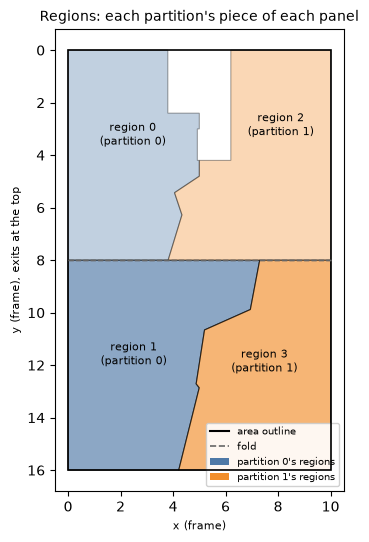

In [9]:
def case_regions(c):
    """generate's regions, from its area and the partitions (as generate computes them)."""
    i = c["input"]
    fr = _Frame(i["side"])
    area = geom(c["settle"]["area"])
    zs = [fr.geom(geom(z)) for z in i["zones"]]
    least = i["traces"] * i["pitch"]
    spacing = SPACING * least
    parts = [shapely.union_all(_polygons(area.intersection(fr.geom(geom(p["area"]))))) for p in c["partitions"]]
    regions, owner = [], []
    for k, part in enumerate(parts):
        got = _regions(part, zs, 2 * spacing**2, spacing)
        regions += got
        owner += [k] * len(got)
    return parts, regions, owner, spacing


c = CASES["partitions"]
parts, regions, owner, spacing = case_regions(c)
rec = c["graphs"][0]
same = len(regions) == len(rec["regions"]) and all(r.equals_exact(geom(w), 1e-12) for r, w in zip(regions, rec["regions"]))
print(f"{len(regions)} regions, owners {owner}; equal to the recording: {same}")
fr, fmask, fzones, _ = frame_geoms(c)
fig, ax = plt.subplots(figsize=(7, 6))
for r, k, j in zip(regions, owner, itertools.count()):
    fill(ax, r, facecolor=PALETTE[k], edgecolor="black", lw=0.8, alpha=0.35 + 0.3 * (j % 2), zorder=2)
    q = r.representative_point()
    ax.text(q.x, q.y, f"region {j}\n(partition {k})", ha="center", fontsize=8, zorder=5)
base(ax, fmask, fzones, "Regions: each partition's piece of each panel")
frame_axes(ax)
legend(ax, BASE + [("patch", PALETTE[0], "partition 0's regions"), ("patch", PALETTE[1], "partition 1's regions")], loc="lower right")
plt.show()

### 3.3 Segments, borders and the call into the core

`_curve` hands the regions to the core as **segments**. A segment is one piece of a region's domain, the region shrunk by half a spacing, so that the curve keeps half a spacing off every border and two neighbouring curves run a full spacing apart. `_shared_borders` gives the borders between regions at least two spacings long, longest first, each with its lines. Only borders within one partition are passed, because no curve may cross between partitions.

The **openings** are the stems' ends. The core also receives a 256-bit key for its random stream, derived from the seed per graph try (`graph/0`, `graph/1`, …).

In [10]:
def _curve(
    regions: list[Polygon],
    owner: list[int],
    spacing: float,
    openings: list[tuple[Point, Point]],
    key: bytes,
) -> tuple[list[tuple[np.ndarray, np.ndarray]], int, int]:
    """The closed curves through the regions, one per opening, by the Rust core
    (``graph::curve``; see ARCHITECTURE.md, 2. to 5.): each its vertices from its stem's end
    at ``opening[0]`` round to its other end (the stem, out through the exit and back,
    closes it) and each vertex's region; the cells and the regions left out. A curve
    crosses only between regions of the same ``owner`` (partition). Here, what needs
    shapely: the segments' domains (each region's pieces shrunk by half a spacing) and the
    borders between regions."""
    segments = [
        (ri, d)
        for ri, r in enumerate(regions)
        for d in _polygons(r.buffer(-spacing / 2))
        if d.area >= spacing**2
    ]
    if not segments:
        raise MeshError("no room for the mesh")
    borders = [b for b in _shared_borders(regions, spacing) if owner[b[0]] == owner[b[1]]]
    try:
        found, cells, lost = _core().curve_graph(
            [(ri, [np.asarray(r.coords, float)[:-1] for r in _rings(d)]) for ri, d in segments],
            borders,
            [(tuple(map(float, a)), tuple(map(float, b))) for a, b in openings],
            spacing,
            key,
            {"seed_spacing": SEED_SPACING, "lloyd": LLOYD, "attempts": ATTEMPTS},
            lambda step, steps: progress.report("graph", step, steps),
        )
    except ValueError as e:
        raise Unbuilt(str(e)) from e
    return [(np.asarray(p), np.asarray(r)) for p, r in found], int(cells), [int(r) for r in lost]


def _shared_borders(
    regions: list[Polygon], spacing: float
) -> list[tuple[int, int, list[np.ndarray]]]:
    """The regions that share a border at least two spacings long, longest first: each
    pair with its border's lines (the longest first)."""
    tree = shapely.STRtree(regions)
    pairs = []
    a_idx, b_idx = tree.query(regions, predicate="intersects")
    for i, j in zip(a_idx, b_idx, strict=True):
        if i < j:
            border = shapely.line_merge(
                shapely.intersection(regions[i].boundary, regions[j].buffer(1e-6))
            )
            if border.length >= 2 * spacing:
                lines = sorted(_lines(border), key=lambda ln: -ln.length)
                pairs.append((border.length, int(i), int(j), lines))
    pairs.sort(key=lambda p: -p[0])
    return [(i, j, [np.asarray(ln.coords, float) for ln in lines]) for _, i, j, lines in pairs]

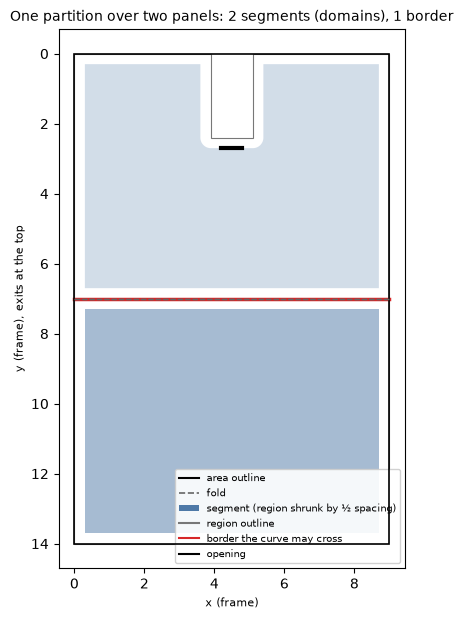

In [11]:
c = CASES["fold"]
gr = c["graphs"][0]
fr, fmask, fzones, _ = frame_geoms(c)
fig, ax = plt.subplots(figsize=(7, 7))
for ri, rs in gr["segments"]:
    rings(ax, rs, facecolor=PALETTE[0], alpha=0.25 + 0.25 * ri, edgecolor="none", zorder=2)
for r in gr["regions"]:
    fill(ax, geom(r), facecolor="none", edgecolor="#777777", lw=0.8, zorder=3)
for i_, j_, lns in gr["borders"]:
    for ln in lns:
        line(ax, ln, color=CHANGED, lw=2.5, zorder=5)
for o0, o1 in gr["openings"]:
    line(ax, [o0, o1], color="black", lw=3, zorder=6)
base(ax, fmask, fzones, "One partition over two panels: 2 segments (domains), 1 border")
frame_axes(ax)
legend(ax, BASE + [("patch", PALETTE[0], "segment (region shrunk by ½ spacing)"),
                   ("line", "#777777", "region outline"), ("line", CHANGED, "border the curve may cross"),
                   ("line", "black", "opening")], loc="lower right")
plt.show()

### 3.4 Cells

On each segment the core lays a **centroidal Voronoi tessellation** (paper, 3.2):

- Seeds are placed on a triangular grid of side `SEED_SPACING · spacing` and jittered a little, from the ChaCha20 stream.
- `LLOYD` times, each seed moves to its cell's centroid.
- A **pin** seed sits half a cell inside each opening and never moves, so that no cell wall meets the edge between the opening's two ends.

Each cell is its seed's bisector half-planes clipped against each other (`clip_half`), then clipped by the domain where an edge of the domain is near. Cells that hold a hole are cut through it (`split_holes`), because the graph needs simply connected faces.

**The one step not reproduced bit for bit.** The core clips with the geo crate's boolean operations (fixed-point i_overlay). The port clips with shapely (GEOS). The cells come out the same shapes to within about 10⁻⁷ mm, but with their vertices in a different order and rounded differently in the last bits. Vertex order decides how the graph's vertices are numbered, and numbering feeds the random matching (3.6), so a graph built on the port's cells would be a different (equally valid) graph. The recording therefore includes the core's cells (computed with the core's own `graph::cells` by `recorder/`). The checks below compare the port's cells with them as shapes, and every later step starts from the recorded cells and is compared exactly.

In [12]:
GRAPH_PARAMS = {"seed_spacing": 1.4, "lloyd": 6, "attempts": 8}


def seeds(domain, d, rng):
    """Seeds on a triangular grid of side d, jittered by up to d / 20 (paper, 3.2)."""
    x0, y0, x1, y1 = poly.bounds(domain)
    h = d * math.sqrt(0.75)
    out = []
    for j in range(as_usize((y1 - y0) / h) + 2):
        for i in range(as_usize((x1 - x0) / d) + 2):
            r, a = d / 20.0 * math.sqrt(rng.random()), 2.0 * math.pi * rng.random()
            q = (x0 + (float(i) + 0.5 * float(j % 2)) * d + r * math.cos(a),
                 y0 + float(j) * h + r * math.sin(a))
            if poly.contains(domain, q):
                out.append(q)
    return out


def clip_half(cell, m, n):
    """The convex polygon cut to where (x - m) . n <= 0."""
    def side(q):
        return (q[0] - m[0]) * n[0] + (q[1] - m[1]) * n[1]
    out = []
    for i in range(len(cell)):
        a, b = cell[i], cell[(i + 1) % len(cell)]
        sa, sb = side(a), side(b)
        if sa <= 0.0:
            out.append(a)
        if (sa < 0.0 and sb > 0.0) or (sa > 0.0 and sb < 0.0):
            out.append(add(a, scale(sub(b, a), sa / (sa - sb))))
    return out


def voronoi(seed_pts, domain, frame, d, edges):
    """Each seed's Voronoi cell within frame (its box cut by the bisectors with the seeds
    near it), clipped by the domain (its pieces)."""
    reach = 4.0 * d
    grid = PointGrid(seed_pts, reach / 2.0)
    out = []
    for i, s in enumerate(seed_pts):
        x0, y0 = max(s[0] - reach, frame[0]), max(s[1] - reach, frame[1])
        x1, y1 = min(s[0] + reach, frame[2]), min(s[1] + reach, frame[3])
        cell = [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]
        for j, _ in grid.within(s, 2.0 * reach):
            if j != i and len(cell) >= 3:
                cell = clip_half(cell, scale(add(s, seed_pts[j]), 0.5), sub(seed_pts[j], s))
        if len(cell) < 3:
            out.append([])
            continue
        lo = (min(q[0] for q in cell), min(q[1] for q in cell))
        hi = (max(q[0] for q in cell), max(q[1] for q in cell))
        if not edges.around(lo, hi):  # (inside the domain, no edge near: as it is)
            out.append([[cell]] if poly.contains(domain, poly.centroid([cell])) else [])
            continue
        out.append(poly.intersection([cell], domain))
    return out


def cells(domain, d, rng, pins, lloyd):
    """A centroidal Voronoi tessellation of the domain (Lloyd iterations), cells clipped by
    it, cells holding a hole split through it. Seeds at the pins stay there."""
    s = seeds(domain, d, rng)
    for pin in pins:
        s = [q for q in s if dist(q, pin) > 0.75 * d]
        s.append(pin)
    if len(s) < 2:
        return split_holes(domain)
    b = poly.bounds(domain)
    frame = (b[0] - 2.0 * d, b[1] - 2.0 * d, b[2] + 2.0 * d, b[3] + 2.0 * d)
    ea = [r[i] for r in domain for i in range(len(r))]
    eb = [r[(i + 1) % len(r)] for r in domain for i in range(len(r))]
    edges = Segs(ea, eb, d)
    pieces = []
    for it in range(lloyd + 1):
        pieces = [p for p in voronoi(s, domain, frame, d, edges) if p]
        if it == lloyd:
            break
        s = []
        for parts in pieces:
            part = max_by(parts, key=poly.area)
            c = poly.centroid(part)
            s.append(c if poly.contains(domain, c) else poly.inner_point(part))
        # (the pins where they were; seeds that came near one since left out)
        for pin in pins:
            k = min_by(range(len(s)), key=lambda a: dist(s[a], pin))
            if k is not None:
                s[k] = pin
        s = [q for q in s if q in pins or all(dist(q, pin) > 0.75 * d for pin in pins)]
    return [q for parts in pieces for p in parts if poly.area(p) > 1e-9 for q in split_holes(p)]


def split_holes(p):
    """The polygon cut so that no piece has a hole (a vertical cut through each)."""
    if len(p) < 2:
        return [p]
    cx = poly.centroid([p[1]])[0]
    x0, y0, x1, y1 = poly.bounds(p)
    out = []
    for half in (poly.rect(x0 - 1.0, y0 - 1.0, cx, y1 + 1.0), poly.rect(cx, y0 - 1.0, x1 + 1.0, y1 + 1.0)):
        for q in poly.intersection(p, half):
            out += split_holes(q)
    return out

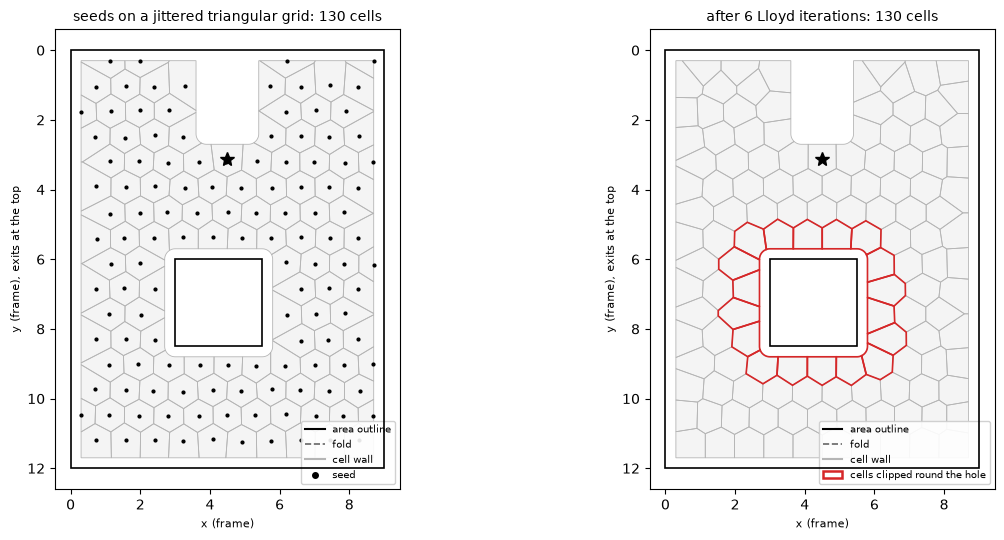

port's cells vs the core's, per segment (count, recorded count, largest Hausdorff distance):
          one: [(89, 89, '2.2e-08')]


         fold: [(73, 73, '1.8e-08'), (86, 86, '2.2e-08')]


   partitions: [(46, 46, '3.8e-08'), (62, 62, '4.4e-08'), (53, 53, '1.7e-08'), (51, 51, '2.0e-08')]


         hole: [(130, 130, '6.9e-08')]


         arcs: [(73, 73, '1.8e-08'), (86, 86, '2.2e-08')]


In [13]:
def graph_inputs(gr):
    segs = [{"region": ri, "domain": [pts(r) for r in rs]} for ri, rs in gr["segments"]]
    borders = [(i, j, [pts(ln) for ln in lns]) for i, j, lns in gr["borders"]]
    openings = [(tuple(a), tuple(b)) for a, b in gr["openings"]]
    return segs, borders, openings


def pins_of(segs, openings, d):
    """The pins, as graph::curve places them."""
    pins = [[] for _ in segs]
    for o0, o1 in openings:
        across = sub(o1, o0)
        inward = scale((-across[1], across[0]), 1.0 / max(norm(across), 1e-12))
        pin = add(scale(add(o0, o1), 0.5), scale(inward, d / 2.0))
        seg = min_by(range(len(segs)), key=lambda i: poly.distance(segs[i]["domain"], o0))
        if poly.contains(segs[seg]["domain"], pin):
            pins[seg].append(pin)
    return pins


def cells_check(gr):
    """The port's cells (first try) against the recorded ones: per segment, the count and
    the largest Hausdorff distance between corresponding cells."""
    segs, _, openings = graph_inputs(gr)
    d = GRAPH_PARAMS["seed_spacing"] * gr["spacing"]
    pins = pins_of(segs, openings, d)
    rng = Rng(bytes.fromhex(gr["key"]))
    out = []
    for si, s in enumerate(segs):
        mine = cells(s["domain"], d, rng, pins[si], GRAPH_PARAMS["lloyd"])
        rec = gr["cells"][si]
        worst = max((shapely.hausdorff_distance(poly.to_shapely(a), poly.to_shapely([pts(r) for r in b]))
                     for a, b in zip(mine, rec)), default=0.0)
        out.append((len(mine), len(rec), worst))
    return out


c = CASES["hole"]
gr = c["graphs"][0]
segs, _, openings = graph_inputs(gr)
d = GRAPH_PARAMS["seed_spacing"] * gr["spacing"]
pins = pins_of(segs, openings, d)
rng = Rng(bytes.fromhex(gr["key"]))
seed0 = seeds(segs[0]["domain"], d, rng)
rng = Rng(bytes.fromhex(gr["key"]))
raw = cells(segs[0]["domain"], d, rng, pins[0], 0)       # (no Lloyd iterations: illustration)
rng = Rng(bytes.fromhex(gr["key"]))
final = cells(segs[0]["domain"], d, rng, pins[0], GRAPH_PARAMS["lloyd"])
fr, fmask, fzones, _ = frame_geoms(c)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, cs, title in [(axes[0], raw, f"seeds on a jittered triangular grid: {len(raw)} cells"),
                      (axes[1], final, f"after {GRAPH_PARAMS['lloyd']} Lloyd iterations: {len(final)} cells")]:
    rings(ax, segs[0]["domain"], facecolor="#F4F4F4", edgecolor="none", zorder=1)
    for cell in cs:
        rings(ax, cell, facecolor="none", edgecolor=GRAPH, lw=0.6, zorder=2)
    base(ax, fmask, fzones, title)
    frame_axes(ax)
axes[0].scatter(*np.array(seed0).T, s=4, color="black", zorder=4)
hole = shapely.box(3, 6, 5.5, 8.5)  # (x 6..8.5, y 3..5.5 on the board; swapped here)
around_hole = [cell for cell in final if poly.to_shapely(cell).distance(hole) < gr["spacing"]]
for cell in around_hole:
    rings(axes[1], cell, facecolor="none", edgecolor=CHANGED, lw=1.2, zorder=3)
for ax in axes:
    for pin in pins[0]:
        ax.plot(*pin, marker="*", color="black", ms=10, zorder=6)
legend(axes[0], BASE + [("line", GRAPH, "cell wall"), ("dot", "black", "seed")], loc="lower right")
legend(axes[1], BASE + [("line", GRAPH, "cell wall"), ("edge", CHANGED, "cells clipped round the hole")],
       loc="lower right")
plt.tight_layout()
plt.show()
print("port's cells vs the core's, per segment (count, recorded count, largest Hausdorff distance):")
for name, cc in CASES.items():
    print(f"  {name:>11}:", [(a, b, f"{w:.1e}") for a, b, w in cells_check(cc["graphs"][0])])

### 3.5 The planar graph and the stem

The cells' corners and walls become a **planar graph**. Corners are merged within a micrometre, and almost every vertex has degree three, as in any Voronoi diagram. Vertices on the domain's rim have degree two.

The **stem** ties the exit into the graph. Its two ends must lie on a single edge of the segment's rim; `stem` splits that edge at them, and the edge between them becomes **fixed**: every cycle must use it. It is the part of the curve that runs up one rail, across, and down the other. If a cell wall meets the rim between the two ends, its foot is moved to the nearer end. If that can't be done, the build is tried afresh.

In [14]:
def key(a, b):
    return (min(a, b), max(a, b))


class Graph:
    """The cells' corners and edges (``adj``, sorted sets: the core's BTreeSet), each
    vertex's segment, the cycle links (``nbr``), the cells (``faces``: corner ids, rings,
    segment) and the edges the cycles must take (``fixed``)."""

    def __init__(self):
        self.pts, self.adj, self.seg, self.nbr = [], [], [], []
        self.faces, self.index, self.fixed = [], {}, set()

    def vertex(self, p, seg):
        """The vertex at p (within a micrometre), added if new."""
        q = 1e-6
        kx, ky = int(rround(p[0] / q)), int(rround(p[1] / q))
        for dx in (0, -1, 1):
            for dy in (0, -1, 1):
                i = self.index.get((kx + dx, ky + dy))
                if i is not None:
                    return i
        i = self.add(p, seg)
        self.index[(kx, ky)] = i
        return i

    def add(self, p, seg):
        self.pts.append(tuple(p))
        self.adj.append(SortedSet())
        self.seg.append(seg)
        self.nbr.append([])
        return len(self.pts) - 1

    def connect(self, a, b):
        self.adj[a].add(b)
        self.adj[b].add(a)

    def link(self, a, b):
        self.nbr[a].append(b)
        self.nbr[b].append(a)

    def unlink(self, a, b):
        if b in self.nbr[a]:
            self.nbr[a].remove(b)
        if a in self.nbr[b]:
            self.nbr[b].remove(a)


def build(g, cell_list, seg):
    """The cells' edges and corners added to the graph."""
    for cell in cell_list:
        ids = []
        for q in cell[0]:
            i = g.vertex(q, seg)
            if not ids or ids[-1] != i:
                ids.append(i)
        while len(ids) > 1 and ids[0] == ids[-1]:
            ids.pop()
        if len(ids) < 3:
            continue
        for k in range(len(ids)):
            g.connect(ids[k], ids[(k + 1) % len(ids)])
        g.faces.append([ids, cell, seg])


class Retry(Exception):
    pass


def stem(g, segments, opening):
    """The exit's stem in the graph: its two ends, on one edge along the rim of the segment
    nearest them (which they split), the edge between them one the cycle must take."""
    seg = min_by(range(len(segments)), key=lambda i: poly.distance(segments[i]["domain"], opening[0]))
    count, order = {}, []
    for ids, _, si in g.faces:
        if si == seg:
            for k in range(len(ids)):
                e = key(ids[k], ids[(k + 1) % len(ids)])
                if count.get(e, 0) == 0:
                    order.append(e)
                count[e] = count.get(e, 0) + 1
    rim = [e for e in order if count[e] == 1]
    if not rim:
        raise Retry
    # (a cell wall's foot on the rim between the opening's ends: moved to the nearer end)
    span = dist(opening[0], opening[1])
    inside = []
    for v in sorted({v for e in rim for v in e}):
        c, t = closest(g.pts[v], opening[0], opening[1])
        t *= span
        if dist(c, g.pts[v]) < 1e-6 and 1e-6 < t < span - 1e-6:
            inside.append(v)
    if len(inside) == 1:
        v = inside[0]
        g.pts[v] = opening[0] if dist(g.pts[v], opening[0]) < dist(g.pts[v], opening[1]) else opening[1]
    elif len(inside) > 1:
        raise Retry

    def gap(e, q):
        return dist(closest(q, g.pts[e[0]], g.pts[e[1]])[0], q)

    def both(e):
        return max(gap(e, opening[0]), gap(e, opening[1]))

    near = min_by(range(len(rim)), key=lambda i: both(rim[i]))
    if both(rim[near]) > 1e-6:
        raise Retry  # (a cell wall between the ends, or the opening off the rim)
    x, y = rim[near]
    px, py = g.pts[x], g.pts[y]
    length = dist(px, py)
    t = [closest(q, px, py)[1] * length for q in opening]
    eps = 1e-6

    def end(ti):
        if ti <= eps:
            return x
        if ti >= length - eps:
            return y
        return g.add(add(px, scale(sub(py, px), ti / max(length, 1e-12))), seg)

    a, b = end(t[0]), end(t[1])
    if a == b:
        raise Retry
    chain = []
    for v in ([x, a, b, y] if t[0] < t[1] else [x, b, a, y]):
        if not chain or chain[-1] != v:
            chain.append(v)
    if len(chain) > 2:
        g.adj[x].discard(y)
        g.adj[y].discard(x)
        for u, w in zip(chain, chain[1:]):
            g.connect(u, w)
        for face in g.faces:  # (the cell along that edge: through the new vertices)
            ids = face[0]
            n = len(ids)
            j = next((j for j in range(n) if key(ids[j], ids[(j + 1) % n]) == key(x, y)), None)
            if j is not None:
                inner = chain[1:-1]
                ids[j + 1 : j + 1] = inner if ids[j] == x else inner[::-1]
                break
    g.fixed.add(key(a, b))
    return a, b

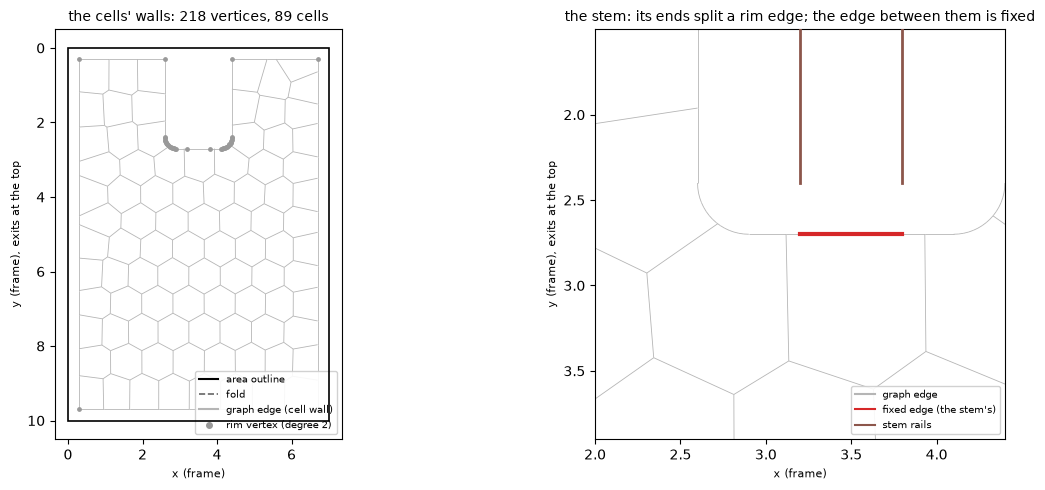

In [15]:
def graph_from_recording(c, upto):
    """The core's first try, step by step on the recorded cells, up to ``upto`` (the next
    sections' plots): the graph, the random stream, the stem ends."""
    gr = c["graphs"][0]
    segs, borders, openings = graph_inputs(gr)
    d = GRAPH_PARAMS["seed_spacing"] * gr["spacing"]
    rng = Rng(bytes.fromhex(gr["key"]))
    g = Graph()
    for si, s in enumerate(segs):
        seeds(s["domain"], d, rng)  # (the same draws as the core's cells)
        build(g, [[pts(r) for r in cell] for cell in gr["cells"][si]], si)
    out = {"segs": segs, "borders": borders, "spacing": gr["spacing"]}
    if upto == "build":
        return g, rng, out
    out["ends"] = [stem(g, segs, o) for o in openings]
    if upto == "stem":
        return g, rng, out
    two_factor(g, rng)
    if upto == "two_factor":
        return g, rng, out
    centres(g)
    if upto == "centres":
        return g, rng, out
    u = Union(len(g.pts))
    for x in range(len(g.pts)):
        for y in g.nbr[x]:
            u.join(x, y)
    out["union"] = u
    return g, rng, out


def draw_graph(ax, g, links=True, edges=True, lw=1.4):
    if edges:
        lines(ax, [(g.pts[a], g.pts[b]) for a in range(len(g.adj)) for b in g.adj[a] if a < b],
              colors=GRAPH, linewidths=0.6, zorder=2)
    if links:
        lines(ax, [(g.pts[a], g.pts[b]) for a in range(len(g.nbr)) for b in g.nbr[a] if a < b],
              colors=CURVE, linewidths=lw, zorder=3)


c = CASES["one"]
g, rng, info = graph_from_recording(c, "stem")
(a_, b_), = info["ends"]
fr, fmask, fzones, _ = frame_geoms(c)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_graph(axes[0], g, links=False)
base(axes[0], fmask, fzones, f"the cells' walls: {len(g.pts)} vertices, {len(g.faces)} cells")
deg = [len(s) for s in g.adj]
axes[0].scatter(*np.array([g.pts[v] for v in range(len(g.pts)) if deg[v] == 2]).T, s=6, color="#999999", zorder=4)
draw_graph(axes[1], g, links=False)
line(axes[1], [g.pts[a_], g.pts[b_]], color=CHANGED, lw=3, zorder=5)
for r in c["relax"]:
    line(axes[1], r["stem"], color=STEM, lw=2, zorder=4)
base(axes[1], fmask, fzones, "the stem: its ends split a rim edge; the edge between them is fixed")
zoom(axes[1], g.pts[a_], 1.2)
for ax in axes:
    frame_axes(ax)
legend(axes[0], BASE + [("line", GRAPH, "graph edge (cell wall)"), ("dot", "#999999", "rim vertex (degree 2)")], loc="lower right")
legend(axes[1], [("line", GRAPH, "graph edge"), ("line", CHANGED, "fixed edge (the stem's)"),
                 ("line", STEM, "stem rails")], loc="lower right")
plt.tight_layout()
plt.show()

### 3.6 Initial cycles

The paper's key observation (3.3.1) is that in a graph where every vertex has degree three, the edges a **perfect matching** leaves out form disjoint cycles covering every vertex: each vertex keeps exactly two of its three edges. Chains of degree-two rim vertices act as single edges between their degree-three ends. A chain holding the fixed stem edge is never matched, so the stem always lies on a cycle.

The matching is Edmonds' blossom algorithm (`max_matching` in `support.graphs`) from a greedy start in a random order. That order is the second use of the random stream, after the seeds. If no perfect matching exists, the build is tried afresh.

In [16]:
def ring(g, v):
    out, prev, here = [v], -1, v
    while True:
        nxt = next((x for x in g.adj[here] if x != prev), None)
        if nxt is not None and nxt != v and len(g.adj[here]) == 2:
            out.append(nxt)
            prev, here = here, nxt
        else:
            return out


def two_factor(g, rng):
    """Cycle links covering every vertex of degree three: the edges a perfect matching
    leaves out (paper, 3.3.1); chains of degree-two vertices act as one edge."""
    deg = [len(a) for a in g.adj]
    if any(k > 3 for k in deg):
        raise Retry
    cubic = [i for i in range(len(deg)) if deg[i] == 3]
    index = {v: j for j, v in enumerate(cubic)}
    chains, seen = [], set()
    for u in cubic:
        for w in g.adj[u]:
            if (u, w) in seen:
                continue
            chain, prev, here = [u, w], u, w
            while deg[here] == 2:
                nxt = next(x for x in g.adj[here] if x != prev)
                prev, here = here, nxt
                chain.append(here)
            seen.add((u, w))
            seen.add((here, prev))
            chains.append(chain)
    held = [any(key(c[i], c[i + 1]) in g.fixed for i in range(len(c) - 1)) for c in chains]
    nbrs = [[] for _ in cubic]
    for c, keep in zip(chains, held):
        if c[0] != c[-1] and not keep:
            a, b = index[c[0]], index[c[-1]]
            nbrs[a].append(b)
            nbrs[b].append(a)
    mate = max_matching(len(cubic), nbrs, rng)
    if any(m is None for m in mate):
        raise Retry
    matched = set()
    for c, keep in zip(chains, held):
        a, b = c[0], c[-1]
        if a != b and not keep and cubic[mate[index[a]]] == b and key(a, b) not in matched:
            matched.add(key(a, b))
            continue
        for i in range(len(c) - 1):
            g.link(c[i], c[i + 1])
    # (rings of degree-two vertices only: a cycle by themselves)
    for v in range(len(deg)):
        if deg[v] == 2 and not g.nbr[v]:
            r = ring(g, v)
            if not any(deg[u] == 3 for u in r):
                for k in range(len(r)):
                    g.link(r[k], r[(k + 1) % len(r)])
    if any(len(g.nbr[u]) != 2 for u in cubic):
        raise Retry

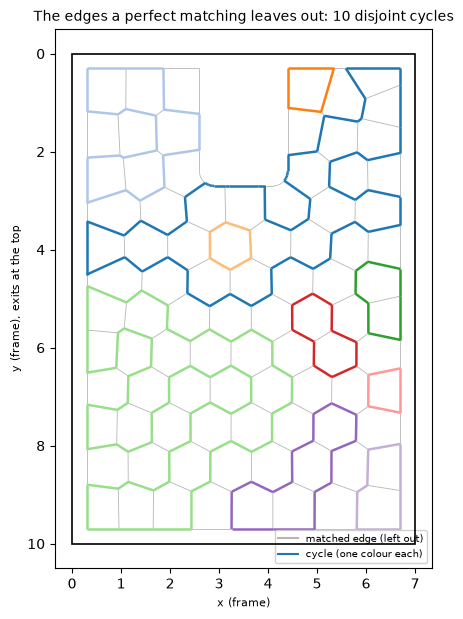

In [17]:
c = CASES["one"]
g, rng, info = graph_from_recording(c, "two_factor")
u = Union(len(g.pts))
for x in range(len(g.pts)):
    for y in g.nbr[x]:
        u.join(x, y)
roots = {}
for v in range(len(g.pts)):
    if g.nbr[v]:
        roots.setdefault(u.find(v), []).append(v)
fig, ax = plt.subplots(figsize=(7, 7))
draw_graph(ax, g, links=False)
cmap = plt.get_cmap("tab20")
for k, vs in enumerate(roots.values()):
    vs = set(vs)
    lines(ax, [(g.pts[a], g.pts[b]) for a in vs for b in g.nbr[a] if a < b], colors=[cmap(k % 20)], linewidths=1.8, zorder=3)
fr, fmask, fzones, _ = frame_geoms(c)
base(ax, fmask, fzones, f"The edges a perfect matching leaves out: {len(roots)} disjoint cycles")
frame_axes(ax)
legend(ax, [("line", GRAPH, "matched edge (left out)"), ("line", cmap(0), "cycle (one colour each)")], loc="lower right")
plt.show()

### 3.7 Refinement: the cells' centres

The cycles so far run only along cell walls and leave every cell's interior empty: their spacing is a whole cell. Paper section 3.3.2 adds a vertex at each cell's centre, connected to the corners it can see (`covers`: the segment stays inside the cell). Each centre is **threaded** into one cycle edge along its cell: the edge a–b becomes a–centre–b.

Which edge each cell takes is a bipartite matching of cells to cycle edges (augmenting paths, breadth first), so that as many cells as possible get one. A threaded edge's detour must not fold back on itself, so the centre has to lie across the edge from inside. The fixed stem edge is never threaded.

In [18]:
def covers(p, c, v):
    """Whether the segment from c to v lies within the polygon (within a hair of it)."""
    e = sub(v, c)
    ts = [0.0, 1.0]
    for r in p:
        for i in range(len(r)):
            a, b = r[i], r[(i + 1) % len(r)]
            f = sub(b, a)
            den = cross(e, f)
            if abs(den) < 1e-18:
                continue
            w = sub(a, c)
            t = cross(w, f) / den
            s = cross(w, e) / den
            if 0.0 <= t <= 1.0 and -1e-9 <= s <= 1.0 + 1e-9:
                ts.append(t)
    ts.sort()
    for t0, t1 in zip(ts, ts[1:]):
        m = add(c, scale(e, (t0 + t1) / 2.0))
        if not (t1 - t0 < 1e-12 or poly.contains(p, m) or poly.boundary_distance(p, m) <= 1e-7):
            return False
    return True


def centres(g):
    """A vertex at each cell's centre, joined to the corners it sees; each threaded into one
    cycle edge along its cell (paper, 3.3.2: a bipartite matching of cells to edges)."""
    cen = [poly.centroid(f[1]) for f in g.faces]
    sees = []
    for fi, (ids, p, _) in enumerate(g.faces):
        if not poly.contains(p, cen[fi]):
            sees.append(SortedSet())
            continue
        sees.append(SortedSet(v for v in ids if covers(p, cen[fi], g.pts[v])))
    cands = []
    for fi, vs in enumerate(sees):
        if sum(1 for v in vs if g.nbr[v]) < 3:
            continue
        ids = g.faces[fi][0]
        es = []
        for k in range(len(ids)):
            a, b = ids[k], ids[(k + 1) % len(ids)]
            if not (a in vs and b in vs and b in g.nbr[a]):
                continue
            t = closest(cen[fi], g.pts[a], g.pts[b])[1]
            if not (0.0 < t < 1.0):  # (the centre across the edge from inside)
                continue
            e = key(a, b)
            if e not in g.fixed:
                es.append(e)
        if es:
            cands.append((fi, es))
    owner, chosen, first = {}, [None] * len(cands), []
    for start in range(len(cands)):
        # (augmenting paths, breadth first, over cells and their edges)
        prev = {start: None}
        queue = deque([start])
        end = None
        while queue and end is None:
            f = queue.popleft()
            for e in cands[f][1]:
                o = owner.get(e)
                if o is None:
                    end = (f, e)
                    break
                if o not in prev:
                    prev[o] = (f, e)
                    queue.append(o)
        if end is None:
            continue
        f, e = end
        while True:
            owner[e] = f
            if chosen[f] is None:
                first.append(f)
            chosen[f] = e
            if prev[f] is None:
                break
            f, e = prev[f]
    for f in first:
        fi = cands[f][0]
        a, b = chosen[f]
        c = g.add(cen[fi], g.faces[fi][2])
        g.unlink(a, b)
        g.link(a, c)
        g.link(c, b)
        for v in sees[fi]:
            g.connect(c, v)

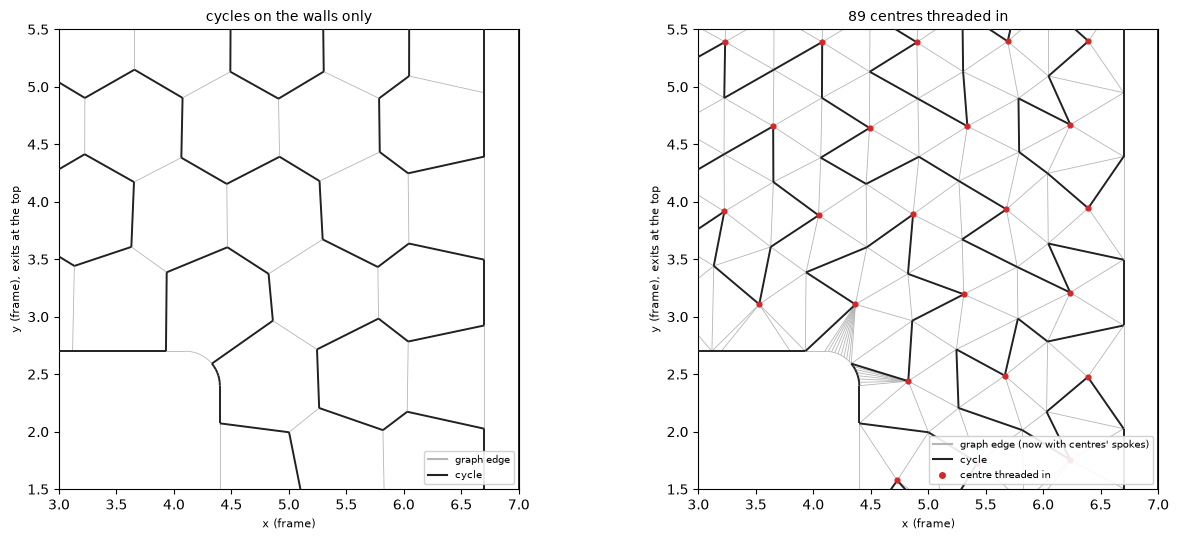

In [19]:
c = CASES["one"]
g0, _, _ = graph_from_recording(c, "two_factor")
g, _, _ = graph_from_recording(c, "centres")
new = range(len(g0.pts), len(g.pts))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, gg, title in [(axes[0], g0, "cycles on the walls only"), (axes[1], g, f"{len(new)} centres threaded in")]:
    draw_graph(ax, gg)
    fr, fmask, fzones, _ = frame_geoms(c)
    base(ax, fmask, fzones, title)
    frame_axes(ax)
    zoom(ax, (5.0, 3.5), 2.0)
axes[1].scatter(*np.array([g.pts[v] for v in new]).T, s=12, color=CHANGED, zorder=5)
legend(axes[0], [("line", GRAPH, "graph edge"), ("line", CURVE, "cycle")], loc="lower right")
legend(axes[1], [("line", GRAPH, "graph edge (now with centres' spokes)"), ("line", CURVE, "cycle"),
                 ("dot", CHANGED, "centre threaded in")], loc="lower right")
plt.tight_layout()
plt.show()

### 3.8 Merging the cycles

The cycles must become one per segment (paper, 3.3.2):

- **Split and reconnect.** Where two different cycles have edges x1–x2 and y1–y2 facing each other across a quad of graph edges (x1–y1 and x2–y2 are graph edges), they swap partners: x1–y1 and x2–y2. One cycle remains.
- **Doubled edges.** Whatever is left is joined by doubling a graph edge between two cycles: two new vertices a quarter of the way along, and a short parallel detour (paper, figure 8).

Cycles are tracked with union–find. Fixed edges are never split.

In [20]:
def merge(g, u):
    """The cycles of each segment joined into one: split-and-reconnect where two cycle edges
    face each other across a quad of graph edges, then doubled edges (paper, 3.3.2)."""
    changed = True
    while changed:
        changed = False
        for x1 in range(len(g.pts)):
            for x2 in list(g.nbr[x1]):
                if key(x1, x2) in g.fixed or x2 not in g.nbr[x1]:
                    continue
                for y1 in list(g.adj[x1]):
                    if not g.nbr[y1] or u.find(y1) == u.find(x1):
                        continue
                    y2 = next((y for y in g.nbr[y1] if y in g.adj[x2]), None)
                    if y2 is None or key(y1, y2) in g.fixed:
                        continue
                    g.unlink(x1, x2)
                    g.unlink(y1, y2)
                    g.link(x1, y1)
                    g.link(x2, y2)
                    u.join(x1, y1)
                    changed = True
                    break
    for x in range(len(g.pts)):  # what is left: double a graph edge between two cycles
        if not g.nbr[x]:
            continue
        for y in list(g.adj[x]):
            if g.nbr[y] and g.seg[y] == g.seg[x] and u.find(x) != u.find(y) and double(g, x, y):
                u.grow(len(g.pts))
                u.join(x, y)
                u.join(x, len(g.pts) - 1)
                u.join(x, len(g.pts) - 2)


def double(g, u, v):
    """Join the cycles through u and v by doubling the edge between them (paper, fig. 8)."""
    pu, pv = g.pts[u], g.pts[v]

    def side(w):
        return cross(sub(pv, pu), sub(w, pu))

    for sign in (1.0, -1.0):
        q = next((w for w in g.nbr[u] if sign * side(g.pts[w]) > 1e-9 and key(u, w) not in g.fixed), None)
        r = next((w for w in g.nbr[v] if sign * side(g.pts[w]) > 1e-9 and key(v, w) not in g.fixed), None)
        if q is None or r is None:
            continue
        a = add(pu, scale(sub(g.pts[q], pu), 0.25))
        b = add(pv, scale(sub(g.pts[r], pv), 0.25))
        around = SortedSet()
        for x in (u, v, q, r):
            around.add(x)
            around.update(g.adj[x])
        if any(x < y and crosses(a, b, g.pts[x], g.pts[y]) for x in around for y in g.nbr[x]):
            continue
        u2, v2 = g.add(a, g.seg[u]), g.add(b, g.seg[v])
        g.unlink(u, q)
        g.unlink(v, r)
        g.link(u, v)
        g.link(u2, v2)
        g.link(u2, q)
        g.link(v2, r)
        return True
    return False

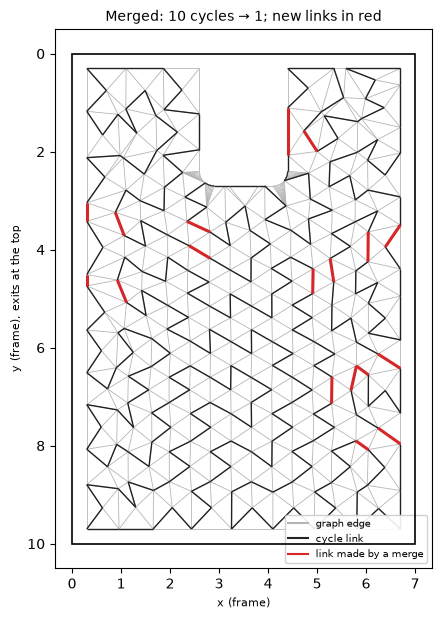

In [21]:
c = CASES["one"]
g, rng, info = graph_from_recording(c, "union")
u = info["union"]
before = {(a, b) for a in range(len(g.nbr)) for b in g.nbr[a] if a < b}
n_before = len({u.find(v) for v in range(len(g.pts)) if g.nbr[v]})
merge(g, u)
after = {(a, b) for a in range(len(g.nbr)) for b in g.nbr[a] if a < b}
n_after = len({u.find(v) for v in range(len(g.pts)) if g.nbr[v]})
fig, ax = plt.subplots(figsize=(7, 7))
draw_graph(ax, g, lw=1.0)
lines(ax, [(g.pts[a], g.pts[b]) for a, b in after - before], colors=CHANGED, linewidths=2.2, zorder=4)
fr, fmask, fzones, _ = frame_geoms(c)
base(ax, fmask, fzones, f"Merged: {n_before} cycles → {n_after}; new links in red")
frame_axes(ax)
legend(ax, [("line", GRAPH, "graph edge"), ("line", CURVE, "cycle link"), ("line", CHANGED, "link made by a merge")], loc="lower right")
plt.show()

### 3.9 Zoning: joining across borders

Each segment now holds one cycle, or a few if merging could not join them all. The segments' cycles are joined across the borders between regions, longest border first. Each join is one split-and-reconnect across the border, which crosses the fold twice. That is the least a closed curve through both panels can do (the paper's zoning objective).

`connect` looks for two cycle edges, one on each side, facing each other across the border. It prefers short joins near the border's middle and keeps away from the border's ends, and the two joining links must not cross any curve edge. It tries three passes, each looser than the last. `split_at` first splits edges that run along the border into its end margins, so that a small region's single cycle can still be joined.

In [22]:
def polyline_length(line):
    s = 0.0
    for a, b in zip(line, line[1:]):
        s += dist(a, b)
    return s


def project(line, q):
    """How far along the polyline its point nearest q is, and how far q is from it."""
    best, at_, run = math.inf, 0.0, 0.0
    for a, b in zip(line, line[1:]):
        c, t = closest(q, a, b)
        d = dist(c, q)
        seg_len = dist(a, b)
        if d < best:
            best, at_ = d, run + t * seg_len
        run += seg_len
    return at_, best


def crosses_at(line, p, q):
    """How far along the polyline the segment p-q first crosses it, if it does."""
    run = 0.0
    for a, b in zip(line, line[1:]):
        d, e = sub(q, p), sub(b, a)
        den = cross(d, e)
        if abs(den) > 1e-12:
            f = sub(a, p)
            t, k = cross(f, e) / den, cross(f, d) / den
            if 0.0 <= t <= 1.0 and 0.0 <= k <= 1.0:
                return run + k * dist(a, b)
        run += dist(a, b)
    return None


def meet(a, b, c, d):
    """Whether segments a-b and c-d meet (touching counts)."""
    def o(p, q, r):
        v = cross(sub(q, p), sub(r, p))
        return 0.0 if abs(v) < 1e-15 else signum(v)

    def on(p, q, r):
        return (min(p[0], q[0]) - 1e-12 <= r[0] <= max(p[0], q[0]) + 1e-12
                and min(p[1], q[1]) - 1e-12 <= r[1] <= max(p[1], q[1]) + 1e-12)

    o1, o2, o3, o4 = o(a, b, c), o(a, b, d), o(c, d, a), o(c, d, b)
    if o1 * o2 < 0.0 and o3 * o4 < 0.0:
        return True
    return ((o1 == 0.0 and on(a, b, c)) or (o2 == 0.0 and on(a, b, d))
            or (o3 == 0.0 and on(c, d, a)) or (o4 == 0.0 and on(c, d, b)))


def join_segments(g, u, segments, borders, spacing):
    """The segments' cycles joined along a spanning tree of the regions that share a border
    (longest first): each join one split-and-reconnect across the border."""
    by_region = {}
    for v in range(len(g.pts)):
        if g.nbr[v]:
            by_region.setdefault(segments[g.seg[v]]["region"], []).append(v)
    for ri, rj, lines in borders:
        va = list(by_region.get(ri, []))
        vb = list(by_region.get(rj, []))
        for line in lines:  # (a cycle edge running into the border's ends: split there)
            length = polyline_length(line)
            if length >= 2.0 * spacing:
                end = min(2.0 * spacing, length / 6.0)
                for vs in (va, vb):
                    split_at(g, u, segments, vs, line, spacing, [end, length - end])
        by_region[ri] = list(va)
        by_region[rj] = list(vb)

        def roots(vs):
            return len({u.find(v) for v in vs})

        for _ in range(roots(va) + roots(vb)):
            if not any(polyline_length(line) >= 2.0 * spacing
                       and connect(g, u, segments, va, vb, line, spacing) for line in lines):
                break


def split_at(g, u, segments, vs, line, near, cuts):
    """Split the cycle edges of vs that run along their domain's boundary within near of
    line across any of the positions cuts along it; the new vertices added to vs."""
    for cut in cuts:
        edges = []
        for a in vs:
            for b in g.nbr[a]:
                if a > b or (a, b) in g.fixed or g.seg[a] != g.seg[b]:
                    continue
                pa, pb = g.pts[a], g.pts[b]
                sa, da = project(line, pa)
                sb, db = project(line, pb)
                if max(da, db) > near or poly.boundary_distance(
                        segments[g.seg[a]]["domain"], scale(add(pa, pb), 0.5)) > 1e-6:
                    continue
                lo, hi = min(sa, sb), max(sa, sb)
                if lo + 0.05 * near < cut < hi - 0.05 * near:
                    edges.append((a, b, (cut - sa) / (sb - sa)))
        for a, b, t in edges:
            v = g.add(add(g.pts[a], scale(sub(g.pts[b], g.pts[a]), t)), g.seg[a])
            u.grow(len(g.pts))
            u.join(a, v)
            g.unlink(a, b)
            g.link(a, v)
            g.link(v, b)
            vs.append(v)


def connect(g, u, segments, va, vb, line, spacing):
    """One split-and-reconnect across the border line between two cycle edges (of cycles
    not yet joined) facing each other across it, away from its ends: the shortest joins,
    nearest its middle; the joins cross no edge of the curve."""
    length = polyline_length(line)
    end = min(2.0 * spacing, length / 6.0)
    cycle = [(a, b) for a in range(len(g.pts)) for b in g.nbr[a] if a < b]
    tree = Segs([g.pts[e[0]] for e in cycle], [g.pts[e[1]] for e in cycle], spacing)
    mid = length / 2.0
    for along, near, reach, crossing_ in ((True, 1.0, 2.0, False), (False, 1.8, 2.6, False),
                                          (False, 1.8, 2.6, True)):
        margin = 0.0 if crossing_ else end
        ea = border_edges(g, segments, va, line, near * spacing, margin, along)
        eb = border_edges(g, segments, vb, line, near * spacing, margin, along)

        def inside(p, q):
            s = crosses_at(line, p, q)
            return s is not None and end <= s <= length - end

        cands = []
        for a1, a2, s1, s2 in ea:
            for b1, b2, t1, t2 in eb:
                if u.find(a1) == u.find(b1):
                    continue
                if crossing_:
                    if not (inside(g.pts[a1], g.pts[b1]) and inside(g.pts[a2], g.pts[b2])):
                        continue
                elif min(s2, t2) - max(s1, t1) < 0.1 * spacing:
                    continue
                l1, l2 = dist(g.pts[a1], g.pts[b1]), dist(g.pts[a2], g.pts[b2])
                if max(l1, l2) <= reach * spacing:
                    cands.append((l1 + l2 + 0.05 * abs((s1 + s2) / 2.0 - mid), a1, a2, b1, b2))
        cands.sort()
        for _, a1, a2, b1, b2 in cands[:100]:
            ends = ((a1, b1), (a2, b2))
            j0, j1 = (g.pts[a1], g.pts[b1]), (g.pts[a2], g.pts[b2])
            if meet(j0[0], j0[1], j1[0], j1[1]):
                continue
            blocked = False
            for e, j in zip(ends, (j0, j1)):
                for i in tree.around(j[0], j[1]):
                    c = cycle[i]
                    if (c[0] != e[0] and c[0] != e[1] and c[1] != e[0] and c[1] != e[1]
                            and meet(j[0], j[1], g.pts[c[0]], g.pts[c[1]])):
                        blocked = True
            if blocked:
                continue
            g.unlink(a1, a2)
            g.unlink(b1, b2)
            g.link(a1, b1)
            g.link(a2, b2)
            u.join(a1, b1)
            return True
    return False


def border_edges(g, segments, vs, line, near, end, along):
    """The cycle edges among vs within near of line and end from its ends (along: only
    those along their segment's edge), each with its ends' places along the line."""
    length = polyline_length(line)
    keep = [v for v in vs if project(line, g.pts[v])[1] <= near]
    kept = set(keep)
    out = []
    for a in keep:
        for b in g.nbr[a]:
            if a > b or b not in kept or (a, b) in g.fixed:
                continue
            pa, pb = g.pts[a], g.pts[b]
            if along and (g.seg[a] != g.seg[b] or poly.boundary_distance(
                    segments[g.seg[a]]["domain"], scale(add(pa, pb), 0.5)) > 1e-6):
                continue
            sa, sb = project(line, pa)[0], project(line, pb)[0]
            slack = 0.1 * near
            if min(sa, sb) < end - slack or max(sa, sb) > length - end + slack:
                continue
            out.append((a, b, sa, sb) if sa <= sb else (b, a, sb, sa))
    return out

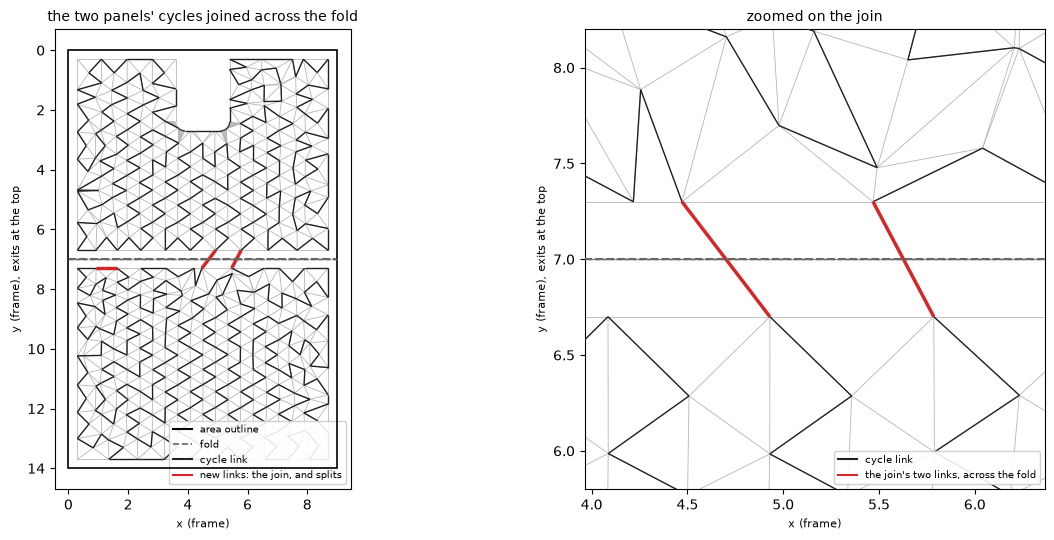

In [23]:
c = CASES["fold"]
gr = c["graphs"][0]
g, rng, info = graph_from_recording(c, "union")
u = info["union"]
merge(g, u)
before = {(a, b) for a in range(len(g.nbr)) for b in g.nbr[a] if a < b}
join_segments(g, u, info["segs"], info["borders"], info["spacing"])
after = {(a, b) for a in range(len(g.nbr)) for b in g.nbr[a] if a < b}
border = info["borders"][0][2][0]
mid = border[len(border) // 2]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, zoomed in ((axes[0], False), (axes[1], True)):
    draw_graph(ax, g, lw=1.0)
    lines(ax, [(g.pts[a], g.pts[b]) for a, b in after - before], colors=CHANGED, linewidths=2.5, zorder=4)
    line(ax, border, color=FOLD, ls="--", lw=1.5, zorder=5)
    fr, fmask, fzones, _ = frame_geoms(c)
    base(ax, fmask, fzones, "the two panels' cycles joined across the fold" if not zoomed else "zoomed on the join")
    frame_axes(ax)
# (the join's links: those crossing the border; the others split edges along it)
joined = [(g.pts[a], g.pts[b]) for a, b in after - before
          if crosses_at(border, g.pts[a], g.pts[b]) is not None]
zoom(axes[1], np.mean([q for s in joined for q in s], axis=0), 1.2)
legend(axes[0], BASE + [("line", CURVE, "cycle link"), ("line", CHANGED, "new links: the join, and splits")], loc="lower right")
legend(axes[1], [("line", CURVE, "cycle link"), ("line", CHANGED, "the join's two links, across the fold")], loc="lower right")
plt.tight_layout()
plt.show()

### 3.10 The curve, and its fallbacks

`curve_graph_core` (the core's `graph::curve`) runs 3.4–3.9 and then **walks** each exit's cycle from one stem end around to the other. Each vertex is tagged with its region, and the result is an open polyline that the stem closes. A try that leaves cycles joined to no exit is retried with fresh random draws (up to `ATTEMPTS` times), and the try that loses the fewest vertices is kept. The regions with a cycle no curve took in are reported as `lost`.

`generate` then has two fallbacks:

- `_reassigned` gives regions no curve reached to the neighbouring partition whose curve does reach the region beside them.
- `_merged` merges a small region that is still unreached into its partition's neighbouring region.

Each fallback builds the graph again. `_lost` counts what is still left out; the layout reports it, and the PCB layout retries the whole layer with a salted seed. None of the cases here needs a fallback.

`snapshot` only records graph states for plots.

In [24]:
def curve_graph_core(segments, borders, openings, spacing, key_bytes, prm=GRAPH_PARAMS,
                     given_cells=None, trace=None):
    """graph::curve: the curves through the segments, one closed through each exit's stem.
    ``given_cells``: each segment's cells for the first try (the recorded ones), instead of
    computing them; ``trace``: a dict the build's stages are kept in (for the plots)."""
    if not segments or not openings:
        raise ValueError("no room for the mesh")
    d = prm["seed_spacing"] * spacing

    def nearest(q):
        return min_by(range(len(segments)), key=lambda i: poly.distance(segments[i]["domain"], q))

    pins = [[] for _ in segments]
    for opening in openings:
        across = sub(opening[1], opening[0])
        inward = scale((-across[1], across[0]), 1.0 / max(norm(across), 1e-12))
        pin = add(scale(add(opening[0], opening[1]), 0.5), scale(inward, d / 2.0))
        seg = nearest(opening[0])
        if poly.contains(segments[seg]["domain"], pin):
            pins[seg].append(pin)
    rng = Rng(key_bytes)
    best = None
    for attempt in range(prm["attempts"]):
        g = Graph()
        for si, s in enumerate(segments):
            if given_cells is not None and attempt == 0:
                seeds(s["domain"], d, rng)  # (the same draws as computing them)
                cs = [[list(map(tuple, r)) for r in c] for c in given_cells[si]]
            else:
                cs = cells(s["domain"], d, rng, pins[si], prm["lloyd"])
            build(g, cs, si)
        if trace is not None and attempt == 0:
            trace["built"] = snapshot(g)
        ends = []
        try:
            for opening in openings:
                ends.append(stem(g, segments, opening))
            two_factor(g, rng)
        except Retry:
            continue
        if trace is not None and attempt == 0:
            trace["two_factor"] = snapshot(g)
        ncells = len(g.faces)
        centres(g)
        if trace is not None and attempt == 0:
            trace["centres"] = snapshot(g)
        u = Union(len(g.pts))
        for x in range(len(g.pts)):
            for y in g.nbr[x]:
                u.join(x, y)
        merge(g, u)
        if trace is not None and attempt == 0:
            trace["merged"] = snapshot(g)
        join_segments(g, u, segments, borders, spacing)
        if trace is not None and attempt == 0:
            trace["joined"] = snapshot(g)
        roots = {u.find(a) for a, _ in ends}
        lost = sum(1 for v in range(len(g.pts)) if g.nbr[v] and u.find(v) not in roots)
        if best is None or lost < best[4]:
            best = (g, u, ends, ncells, lost)
        if trace is not None:
            trace.setdefault("tries", []).append(lost)
        if lost == 0:
            break
    if best is None:
        raise ValueError("could not build the curve's graph")
    g, u, ends, ncells, _ = best

    def region(v):
        return segments[g.seg[v]]["region"]

    curves, roots = [], set()
    for a, b in ends:
        roots.add(u.find(a))
        order = [b, a]  # (walk from a away from b: the stem between them)
        for _ in range(len(g.pts) + 2):
            last, before = order[-1], order[-2]
            nxt = next((x for x in g.nbr[last] if x != before), None)
            if nxt is None:
                raise ValueError("the curve's graph does not close")
            if nxt == b:
                break
            order.append(nxt)
        order.pop(0)
        order.append(b)
        curves.append(([g.pts[v] for v in order], [region(v) for v in order]))
    if len(roots) < len(ends):
        raise ValueError("two exits' curves were joined")
    lost = sorted({region(v) for v in range(len(g.pts)) if g.nbr[v] and u.find(v) not in roots})
    return curves, ncells, lost


def snapshot(g):
    """The graph's edges and cycle links as they are (for the plots)."""
    return {
        "pts": list(g.pts),
        "edges": [(a, b) for a in range(len(g.adj)) for b in g.adj[a] if a < b],
        "links": [(a, b) for a in range(len(g.nbr)) for b in g.nbr[a] if a < b],
    }

In [25]:
def _reassigned(
    regions: list[Polygon],
    owner: list[int],
    found: list[tuple[np.ndarray, np.ndarray]],
    spacing: float,
) -> list[int] | None:
    """The regions' owners with those no curve reached (and that could take one: their
    domains not empty) given to a partition whose curve does reach a region beside them
    (along a border a curve can cross, the longest), and so on from those; None if none
    moves."""
    lost = _lost(regions, found, spacing)
    if not lost:
        return None
    out = list(owner)
    borders = _shared_borders(regions, spacing)  # (longest first)
    changed = True
    while lost and changed:
        changed = False
        for i, j, _ in borders:
            for a, b in ((i, j), (j, i)):
                if a in lost and b not in lost and out[a] != out[b]:
                    out[a] = out[b]
                    lost.discard(a)
                    changed = True
    return out if out != list(owner) else None


def _merged(
    regions: list[Polygon],
    owner: list[int],
    found: list[tuple[np.ndarray, np.ndarray]],
    spacing: float,
) -> tuple[list[Polygon], list[int]] | None:
    """The regions with each one no curve reached (and that could take one) merged into the
    reached region of its partition beside it, across the longest border a curve can cross;
    None if there is none to merge."""
    lost = _lost(regions, found, spacing)
    if not lost:
        return None
    into: dict[int, int] = {}
    for i, j, _ in _shared_borders(regions, spacing):  # (longest first)
        for a, b in ((i, j), (j, i)):
            if a in lost and a not in into and b not in lost and owner[a] == owner[b]:
                into[a] = b
    if not into:
        return None
    out = list(regions)
    for a, b in into.items():
        out[b] = shapely.union_all([out[b], out[a]])
    keep = [i for i in range(len(regions)) if i not in into]
    return [out[i] for i in keep], [owner[i] for i in keep]


def _lost(
    regions: list[Polygon],
    found: list[tuple[np.ndarray, np.ndarray]],
    spacing: float,
    lost: Sequence[int] = (),
) -> set[int]:
    """The regions no curve reached that could take one (their domains not empty), and
    those the core says it reached in part only (``lost``: a cycle of theirs no curve took
    in, as a flap a partition's curve reaches along a strip only)."""
    reached = {int(r) for _, regs in found for r in np.asarray(regs).ravel()}
    return set(lost) | {
        i
        for i, r in enumerate(regions)
        if i not in reached and any(d.area >= spacing**2 for d in _polygons(r.buffer(-spacing / 2)))
    }

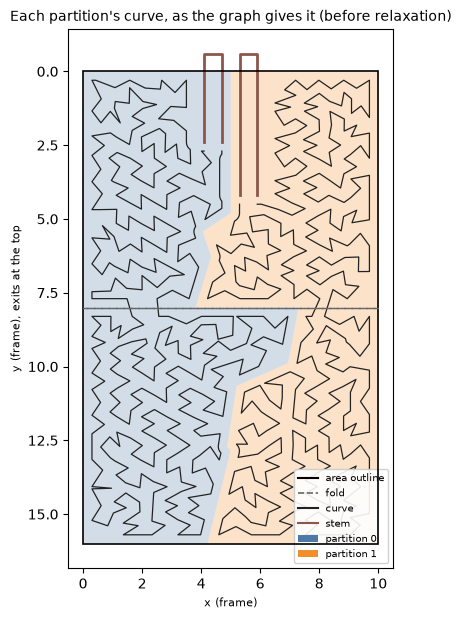

the port's curves equal the core's (on the recorded cells), per case:
          one: [(True, 89, [287])]
         fold: [(True, 159, [509])]
   partitions: [(True, 212, [380, 346])]
         hole: [(True, 130, [473])]
         arcs: [(True, 159, [509])]


In [26]:
def graph_check(c):
    """The port's curve graph on the recorded cells against the core's curves: exact."""
    out = []
    for gr in c["graphs"]:
        segs, borders, openings = graph_inputs(gr)
        found, ncells, lost = curve_graph_core(segs, borders, openings, gr["spacing"], bytes.fromhex(gr["key"]),
                                               given_cells=gr["cells"])
        same = (ncells == gr["ncells"] and lost == gr["lost"] and len(found) == len(gr["curves"]) and all(
            len(p) == len(q) and r == qr and max(max(abs(x[0] - y[0]), abs(x[1] - y[1])) for x, y in zip(p, q)) <= 1e-12
            for (p, r), (q, qr) in zip(found, gr["curves"])))
        out.append((same, ncells, [len(p) for p, _ in found]))
    return out, found


c = CASES["partitions"]
res, found = graph_check(c)
fr, fmask, fzones, fparts = frame_geoms(c)
fig, ax = plt.subplots(figsize=(8, 7))
for k, p in enumerate(fparts):
    fill(ax, p, facecolor=PALETTE[k], edgecolor="none", alpha=0.25, zorder=1)
for k, (p, _) in enumerate(found):
    line(ax, p, color=CURVE, lw=0.9, zorder=3)
for r in c["relax"]:
    line(ax, r["stem"], color=STEM, lw=2, zorder=4)
base(ax, fmask, fzones, "Each partition's curve, as the graph gives it (before relaxation)")
frame_axes(ax)
legend(ax, BASE + [("line", CURVE, "curve"), ("line", STEM, "stem"), ("patch", PALETTE[0], "partition 0"),
                   ("patch", PALETTE[1], "partition 1")], loc="lower right")
plt.show()
print("the port's curves equal the core's (on the recorded cells), per case:")
for name, cc in CASES.items():
    print(f"  {name:>11}:", graph_check(cc)[0])

### 3.11 Relaxation

The graph's curve has the right topology but rough geometry: zigzags along cell walls, uneven spacing, gaps. `relax` (the core's `curve::relax`, paper 3.4 plus a growth phase not in the paper) works in four phases:

1. **CVT steps** (`LLOYD_CURVE`). Every vertex moves to the centroid of the sample points nearest to it within its zone, so the runs space themselves evenly. Then Taubin smoothing, softening of bends too tight for the ribbon, and a Laplacian term that steers the length toward its **target** (the regions' area over the spacing). Moves are capped, stay inside the area, and are taken back where the curve would cross itself (`untangle`).
2. **Finer resampling** along a spline through the curve, at a quarter spacing.
3. **Growth** (`grow`, like differential growth). Nearby runs repel, and bends bulge into the room left between runs. The paper's curve has no width, but here each run carries a ribbon of `n` traces, so the room between runs that part grows up to a ribbon's width before another run fits.
4. **Repair** (`REPAIR`). Runs nearer than `PUSH_MARGIN` spacings, or nearer the edge than half that, are pushed apart. Tight bends are rounded, and vertices outside the area are pulled back.

Throughout, the curve near the openings leaves along the rail's line (`openings_`). Beside a longer stem it is held on it (`straighten`), so its traces keep the pitch from the stem's.

`sfc._relax` passes the area's edge and the zone borders (as points) to the core. Where the curve crosses a border it is allowed to come near it.

In [27]:
CURVE_PARAMS = {"lloyd_curve": 20, "gain": 3.0, "push_margin": 1.04, "window": 1.5,
                "bend_slack": 0.85, "grow": 150, "reach": 1.06, "grow_rate": 0.5, "hard": 10,
                "stall": 10, "repair": 100, "inside": 0.9, "hold": 0}


def relax(curve, stem_pts, regions, target, edge_in, borders_in, spacing, least, pitch, offset,
          prm=CURVE_PARAMS, trace=None):
    """curve::relax: the curve (open, from the stem's left end round to its right end; the
    stem closes it) relaxed towards an even spacing in its zones, grown into the room
    between its runs, its runs pushed apart and its tight bends rounded; never crossing
    itself. Returned closed (the stem last), with the number of vertices before the stem's."""
    zones = Zones(regions, spacing)
    stem_len = polyline_length(stem_pts)
    step = spacing / 2.0
    free = closed.split(curve, step)
    samples, sreg = lloyd_samples(regions, zones, spacing / 3.0, offset)
    inner = list(stem_pts[1:-1])
    n = rround(least / pitch)
    bend = max((n - 1.0) / 2.0 * pitch / prm["inside"], n * pitch / 2.0)
    # 1. CVT steps: each vertex to the centroid of the samples nearest it in its zone
    for it in range(prm["lloyd_curve"]):
        p = free + inner
        k = len(free)
        old = list(p)
        reg = [zones.of(q) for q in p]
        cen = lloyd(p, reg, samples, sreg, spacing)
        p[1 : k - 1] = cen[1 : k - 1]
        p = closed.taubin(p, k, 2)
        # (bends tighter than the traces can follow: smoothed, the length held)
        sharp = sharp_bends(p, k, prm["bend_slack"] * bend)
        sharp[0] = False
        soft = closed.dilate(sharp, 1)
        soft[0] = False
        for i in range(k - 1, len(soft)):
            soft[i] = False
        lp = closed.lap(p)
        for i in range(len(p)):
            if soft[i]:
                p[i] = add(p[i], scale(lp[i], 0.5))
        length = polyline_length(p[:k]) + stem_len
        lam = clamp(prm["gain"] * (length - target) / target, -0.2, 0.5)
        lp = closed.lap(p)
        m = len(p)
        for i in range(1, k - 1):
            s = (0.0, 0.0)
            for dd in range(-2, 3):
                s = add(s, lp[(i + dd) % m])
            p[i] = add(p[i], scale(s, lam / 5.0))
        cap_moves(old, p, step / 2.0)
        keep_in(zones, old, p)
        free = even(untangle(old, p), k, step, False)
        if trace is not None and it in (0, prm["lloyd_curve"] - 1):
            trace[f"lloyd{it}"] = free + inner
    # 2. finer: the stem's rails resampled, the curve along a spline through it
    step = spacing / 4.0
    ends = [free[-1], *stem_pts[1:-1], free[0]]
    r = resample_line(ends, step)
    inner = r[1:-1]
    free = even(free + inner, len(free), step, True)
    want = prm["push_margin"] * least
    window = prm["window"] * least
    # (the edge kept off by half a spacing: the area's, and the zones' borders but where the
    # curve crosses them)
    cl = free + inner
    reg = [zones.of(q) for q in cl]
    xs = [scale(add(cl[i], cl[(i + 1) % len(cl)]), 0.5) for i in range(len(cl))
          if reg[i] != reg[(i + 1) % len(cl)]]
    xgrid = PointGrid(xs, 1.5 * spacing)
    edge = list(edge_in) + [b for b in borders_in if not xgrid.within(b, 1.5 * spacing)]
    edges = PointGrid(edge, want)
    # 3. grown into the room between its runs
    p, k = grow(free + inner, len(free), step, least, target - stem_len, edge, edges, bend, zones, prm)
    if trace is not None:
        trace["grown"] = list(p)
    # 4. repaired: runs pushed apart, tight bends rounded, strays pulled back
    hot = None
    for it in range(prm["repair"]):
        free = closed.respace(p[:k], step)
        p = free + inner
        k = len(free)
        which = list(range(k)) if hot is None else [i for i in range(k) if cell_of(p[i], want) in hot]
        near = neighbours(p, window, want, 0, which)
        de = [nearest_edge(edges, p[w], want) for w in which]
        sharp = sharp_bends(p, k, prm["bend_slack"] * bend)
        sharp[0] = False
        hit = False
        mv = [(0.0, 0.0)] * len(p)
        for j, w in enumerate(which):
            if w == 0 or w + 1 >= k:
                continue  # (the stem's ends stay)

            def push(other, d, w=w):
                away = sub(p[w], other)
                away = scale(away, 1.0 / max(norm(away), 1e-12))
                mv[w] = add(mv[w], scale(away, 0.6 * (want - d) + step / 8.0))

            if near[j] is not None and near[j][0] < want:
                push(p[near[j][1]], near[j][0])
                hit = True
            if de[j] is not None and 2.0 * de[j][0] < want:
                push(edge[de[j][1]], 2.0 * de[j][0])
                hit = True
        back = [(0.0, 0.0)] * len(p)
        out = pull_in(zones, edges, edge, p, k, back)
        if not hit and not out and not any(sharp):
            break
        m = len(p)
        mv = [scale(add(add(mv[(i - 1) % m], scale(mv[i], 2.0)), mv[(i + 1) % m]), 0.25) for i in range(m)]
        soft = soften(p, k, sharp, it >= prm["hard"])
        mv = [add(mv[i], soft[i]) for i in range(m)]
        openings_(p, k, mv)
        for i in range(m):
            if back[i] != (0.0, 0.0):
                mv[i] = back[i]
        moved = [norm(v) > 0.0 for v in mv]
        new = [add(p[i], mv[i]) for i in range(m)]
        cap_moves(p, new, step / 2.0)
        keep_in(zones, p, new)
        p = untangle(p, new)
        hot = hot_cells([p[i] for i in range(k) if moved[i]], want)
    straighten(p, k, 1.5 * spacing, prm["hold"])
    return p, k


def grow(p, k, step, least, target, edge, edges, bend, zones, prm):
    """The closed curve grown into the room between its runs, as by differential growth:
    nearby runs repel, bends bulge where there is room."""
    reach = prm["reach"] * least
    look = reach + step
    window = prm["window"] * least
    want = prm["push_margin"] * least
    width = max(as_usize(rround(least / step / 2.0)), 1)
    hot = None
    lengths = []
    for _ in range(prm["grow"]):
        free = closed.respace(p[:k], step)
        p = free + p[k:]
        k = len(free)
        length = polyline_length(free)
        lengths.append(length)
        stalled = len(lengths) > prm["stall"] and length < lengths[-prm["stall"] - 1] * 1.002
        if length >= target or stalled:
            break
        which = list(range(k)) if hot is None else [i for i in range(k) if cell_of(p[i], look) in hot]
        if not which:
            break
        m = len(p)
        normal = closed.normals(p, 1)
        left = neighbours(p, window, look, 1, which)
        right = neighbours(p, window, look, -1, which)
        lp = closed.lap(p)
        push = [0.0] * m
        for j, w in enumerate(which):
            lft = look if left[j] is None else left[j][0]
            rgt = look if right[j] is None else right[j][0]
            ne = nearest_edge(edges, p[w], want)
            if ne is not None:
                d, e = ne
                if dot(sub(edge[e], p[w]), normal[w]) > 0.0:
                    lft = min(lft, 2.0 * d)
                else:
                    rgt = min(rgt, 2.0 * d)
            f = (max(reach - rgt, 0.0) - max(reach - lft, 0.0)) / 2.0
            if length < target:
                o = (0.0, 0.0)
                for dd in range(-2, 3):
                    o = sub(o, lp[(w + dd) % m])
                way = signum(dot(o, normal[w]))
                room = (lft if way > 0.0 else rgt) - reach
                f += way * prm["grow_rate"] * clamp(room, 0.0, step)
            push[w] = f
        busy = [abs(f) > 0.05 * step for f in push]
        if not any(busy):
            break
        for _ in range(2):
            push = closed.box_mean(push, width)
        smooth = closed.taubin(p, k, 1)
        sharp = sharp_bends(p, k, prm["bend_slack"] * bend)
        sharp[0] = False
        soft = soften(p, k, sharp, False)
        mv = [add(add(scale(normal[i], push[i]), sub(smooth[i], p[i])), soft[i]) for i in range(m)]
        openings_(p, k, mv)
        pull_in(zones, edges, edge, p, k, mv)
        new = [add(p[i], mv[i]) for i in range(m)]
        cap_moves(p, new, step / 2.0)
        keep_in(zones, p, new)
        p = untangle(p, new)
        hot = hot_cells([p[i] for i in range(k) if busy[i]], look)
    return p, k


def neighbours(p, window, reach, side, which):
    """For the vertices ``which``: the nearest vertex more than ``window`` away along the
    curve and within ``reach`` (on its left for side 1, right for -1, either for 0)."""
    n = len(p)
    arc, total = closed.arcs(p)
    grid = PointGrid(p, reach / 2.0)
    out = []
    for i in which:
        t = sub(p[(i + 1) % n], p[(i - 1) % n])
        normal = (-t[1], t[0])
        best = None
        for o, d2 in grid.within(p[i], reach):
            gap = abs(arc[i] - arc[o])
            if min(gap, total - gap) <= window:
                continue
            if side != 0 and float(side) * dot(sub(p[o], p[i]), normal) <= 0.0:
                continue
            if best is None or d2 < best[0] * best[0]:
                best = (math.sqrt(d2), o)
        out.append(best)
    return out


def nearest_edge(edges, q, r):
    best = None
    for e, d2 in edges.within(q, r):
        if best is None or d2 < best[0] * best[0]:
            best = (math.sqrt(d2), e)
    return best


def lloyd(p, reg, samples, sreg, spacing):
    """Each vertex's centroid of the samples nearer to it than to any other vertex in its
    zone (the per-zone CVT): the vertex itself where none are."""
    r = 1.125 * spacing
    grid = PointGrid(p, r / 2.0)
    sums = [(0.0, 0.0)] * len(p)
    count = [0] * len(p)
    for s, q in enumerate(samples):
        best = None
        for i, d2 in grid.within(q, r):
            if reg[i] == sreg[s] and (best is None or d2 < best[0]):
                best = (d2, i)
        if best is not None:
            i = best[1]
            sums[i] = add(sums[i], q)
            count[i] += 1
    return [scale(sums[i], 1.0 / float(count[i])) if count[i] > 0 else p[i] for i in range(len(p))]


def lloyd_samples(regions, zones, step, offset):
    """Points on a square grid (offset by ``offset``) over the regions, with their region."""
    pts, reg = [], []
    for ri, rings in enumerate(regions):
        allq = [q for r in rings for q in r]
        x0, x1 = min(q[0] for q in allq), max(q[0] for q in allq)
        y0, y1 = min(q[1] for q in allq), max(q[1] for q in allq)
        nx = as_usize(math.ceil((x1 + step - (x0 - offset[0])) / step))
        ny = as_usize(math.ceil((y1 + step - (y0 - offset[1])) / step))
        for j in range(ny):
            for i in range(nx):
                q = (x0 - offset[0] + float(i) * step, y0 - offset[1] + float(j) * step)
                if zones.of(q) == ri:
                    pts.append(q)
                    reg.append(ri)
    return pts, reg


def sharp_bends(p, k, under):
    r = closed.radius(p, 1)
    return [i < max(k - 1, 0) and abs(r[i]) < under for i in range(len(p))]


def soften(p, k, sharp, hard):
    """A move rounding the sharp bends: Taubin's smoothing about them; ``hard``: a
    Laplacian step at them too."""
    soft = closed.dilate(sharp, 3)
    t = closed.taubin(p, k, 2)
    out = [sub(t[i], p[i]) if soft[i] else (0.0, 0.0) for i in range(len(p))]
    if hard:
        near = closed.dilate(sharp, 1)
        lp = closed.lap(p)
        for i in range(len(p)):
            if near[i]:
                out[i] = add(out[i], scale(lp[i], 0.5))
    return out


def openings_(p, k, mv):
    """Off the stem's openings: the curve on along their line for a while (mv amended; the
    stem and its ends stay)."""
    n = len(p)
    for end, prev, sign in ((0, n - 1, 1), (k - 1, k, -1)):
        t = sub(p[end], p[prev])
        t = scale(t, 1.0 / max(norm(t), 1e-12))
        for m in range(1, 4):
            i = end + sign * m
            on = add(p[end], scale(t, dist(p[i], p[end])))
            to = sub(on, p[i])
            mv[i] = to if m == 1 else add(mv[i], scale(to, 0.5 / float(m)))
    mv[0] = (0.0, 0.0)
    mv[k - 1] = (0.0, 0.0)
    for i in range(k, len(mv)):
        mv[i] = (0.0, 0.0)


def straighten(p, k, reach, hold):
    """The curve's vertices near the stem's openings on the rails in ``hold`` put on the
    line the rail leaves along (all the way at first, less and less from half way)."""
    n = len(p)
    for bit, end, prev, other, sign in ((1, 0, n - 1, k - 1, 1), (2, k - 1, k, 0, -1)):
        if hold & bit == 0:
            continue
        t = sub(p[end], p[prev])
        t = scale(t, 1.0 / max(norm(t), 1e-12))
        o = sub(p[end], p[other])
        o = sub(o, scale(t, dot(o, t)))
        o = scale(o, 1.0 / max(norm(o), 1e-12))
        m = 1
        while True:
            i = end + sign * m
            if i <= 0 or i >= k - 1:
                break
            far = dist(p[i], p[end])
            if far > reach or dot(sub(p[i], p[end]), t) <= 0.0:
                break
            w = min((reach - far) / (0.5 * reach), 1.0)
            off = dot(sub(p[i], p[end]), o)
            p[i] = sub(p[i], scale(o, w * off))
            m += 1


def cap_moves(old, new, most):
    for i in range(len(old)):
        mv = sub(new[i], old[i])
        s = norm(mv)
        if s > most:
            new[i] = add(old[i], scale(mv, most / s))


def keep_in(zones, old, new):
    """Each vertex that a move takes out of all zones back where it was."""
    for i in range(len(old)):
        if new[i] != old[i] and zones.of(new[i]) is None and zones.of(old[i]) is not None:
            new[i] = old[i]


def pull_in(zones, edges, edge, p, k, mv):
    """Each free vertex out of the zones moved back onto the edge (mv amended): whether
    there were any."""
    found = False
    for i in range(k):
        if i == 0 or i + 1 >= k or zones.of(p[i]) is not None:
            continue
        r = 1e-3
        while True:
            ne = nearest_edge(edges, p[i], r)
            if ne is not None:
                mv[i] = sub(edge[ne[1]], p[i])
                found = True
                break
            r *= 2.0
            if r > 1e3:
                break
    return found


def untangle(old, new):
    """``new`` with the vertices of every segment that would cross another back where they
    were in ``old`` (which crosses nowhere)."""
    n = len(new)
    new = list(new)
    moved = [i for i in range(n) if new[i] != old[i]]
    for _ in range(50):
        if not moved:
            return new
        which = sorted({j for i in moved for j in (i, (i - 1) % n)})
        pairs = crossing(new, which)
        if not pairs:
            return new
        back = sorted({x for i, j in pairs for x in (i, (i + 1) % n, j, (j + 1) % n)})
        for b in back:
            new[b] = old[b]
        moved = back
    return list(old)


def even(p, k, step, smooth):
    """The closed curve's first k vertices resampled at an even step (smooth: along a
    spline), unless that would make it cross itself: then only its long segments split."""
    if smooth:
        fine = closed.spline(p, 4)
        free = resample_line(fine[: 4 * (k - 1) + 1], step)
    else:
        free = resample_line(p[:k], step)
    q = free + p[k:]
    if not crossing(q, list(range(len(q)))):
        return free
    return closed.split(p[:k], 1.5 * step)


def cell_of(q, size):
    return (math.floor(q[0] / size), math.floor(q[1] / size))


def hot_cells(pts, size):
    h = set()
    for q in pts:
        a, b = cell_of(q, size)
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                h.add((a + dx, b + dy))
    return h

In [28]:
def _relax(
    curve: np.ndarray,
    stem: np.ndarray,
    area: shapely.Geometry,
    regions: list[Polygon],
    spacing: float,
    least: float,
    pitch: float,
    rng: Rand,
    hold: int = 0,
) -> tuple[np.ndarray, int]:
    """The curve, relaxed by the Rust core (``curve::relax``; see ARCHITECTURE.md, 6. and 7.):
    ``curve`` an open polyline from the stem's left end round to its right end, the stem
    closing it. Returned closed (the stem last), with the number of vertices before the
    stem's. Here, what needs shapely: the regions' rings and area, the area's edge and the
    borders between regions (points along them)."""
    step = spacing / 8  # (the edge's points: half the finer relaxing step apart)
    edge = np.vstack([resample(np.asarray(r.coords), step) for r in _rings(area)])
    p, k = _core().relax_curve(
        np.ascontiguousarray(curve, float),
        np.ascontiguousarray(stem, float),
        [[np.asarray(r.coords, float) for r in _rings(z)] for z in regions],
        sum(r.area for r in regions) / spacing,
        edge,
        np.ascontiguousarray(_borders(regions, area, step), float),
        spacing,
        least,
        pitch,
        tuple(float(v) for v in rng.random(2) * spacing / 3),
        {
            "lloyd_curve": LLOYD_CURVE,
            "gain": GAIN,
            "push_margin": PUSH_MARGIN,
            "window": WINDOW,
            "bend_slack": BEND_SLACK,
            "grow": GROW,
            "reach": REACH,
            "grow_rate": GROW_RATE,
            "hard": HARD,
            "stall": STALL,
            "repair": REPAIR,
            "inside": INSIDE,
            "hold": hold,
        },
        lambda step, steps: progress.report("relax", step, steps),
    )
    return np.asarray(p), int(k)


def _borders(regions: list[Polygon], area: shapely.Geometry, step: float) -> np.ndarray:
    """Points along the borders between regions (the folds; not the area's edge)."""
    edge = area.boundary.buffer(1e-6)
    lines = shapely.difference(shapely.union_all([r.boundary for r in regions]), edge)
    pts = [resample(shapely.get_coordinates(ln), step) for ln in _lines(shapely.line_merge(lines))]
    return np.vstack(pts) if pts else np.zeros((0, 2))

relaxed in 1.6 s; bit-for-bit equal to the core's: True


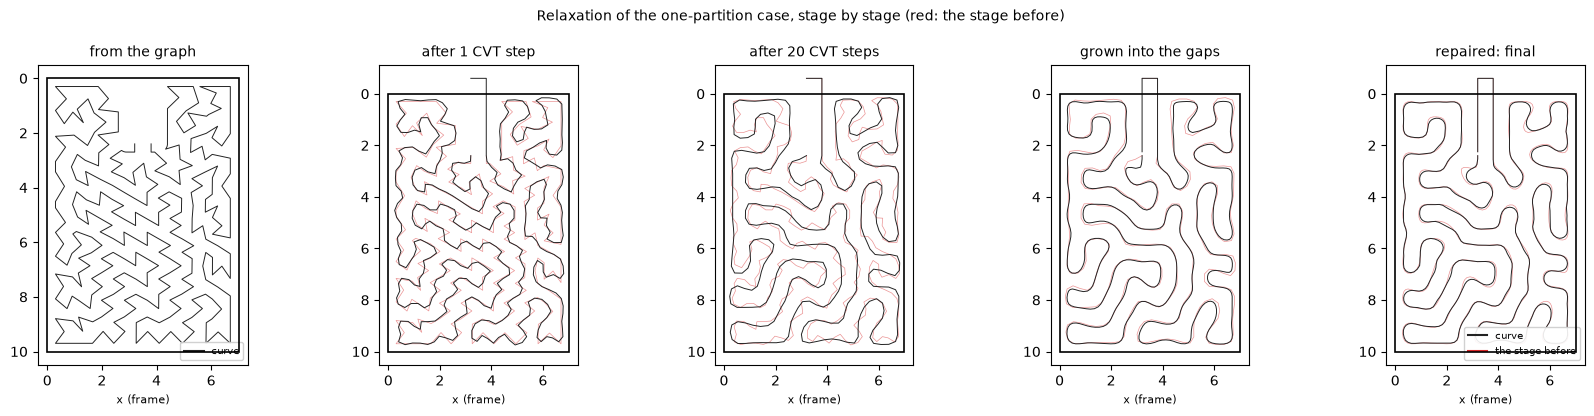

In [29]:
def relax_check(r):
    """The port's relaxation on the recorded input against the core's output: exact."""
    trace = {}
    p, k = relax(pts(r["curve"]), pts(r["stem"]), [[pts(x) for x in z] for z in r["regions"]], r["target"],
                 pts(r["edge"]), pts(r["borders"]), r["spacing"], r["least"], r["pitch"], tuple(r["offset"]),
                 {**CURVE_PARAMS, **r["params"]}, trace)
    same = k == r["k"] and len(p) == len(r["out"]) and all(a == tuple(b) for a, b in zip(p, r["out"]))
    return same, p, k, trace


c = CASES["one"]
t0 = time.perf_counter()
same, p, k, trace = relax_check(c["relax"][0])
print(f"relaxed in {time.perf_counter() - t0:.1f} s; bit-for-bit equal to the core's: {same}")
fr, fmask, fzones, _ = frame_geoms(c)
stages = [(c["relax"][0]["curve"], "from the graph"), (trace["lloyd0"], "after 1 CVT step"),
          (trace[f"lloyd{CURVE_PARAMS['lloyd_curve'] - 1}"], f"after {CURVE_PARAMS['lloyd_curve']} CVT steps"),
          (trace["grown"], "grown into the gaps"), (p, "repaired: final")]
fig, axes = plt.subplots(1, 5, figsize=(17, 4.2))
for ax, (q, title) in zip(axes, stages):
    line(ax, q, color=CURVE, lw=0.7, zorder=3)
    base(ax, fmask, fzones, title)
    frame_axes(ax)
    ax.set_ylabel("")
for ax, q in zip(axes[1:], [s[0] for s in stages[:-1]]):
    line(ax, q, color=CHANGED, lw=0.5, alpha=0.5, zorder=2)
legend(axes[0], [("line", CURVE, "curve")], loc="lower right")
legend(axes[-1], [("line", CURVE, "curve"), ("line", CHANGED, "the stage before")], loc="lower right")
plt.suptitle("Relaxation of the one-partition case, stage by stage (red: the stage before)", fontsize=10)
plt.tight_layout()
plt.show()

### 3.12 Lanes: from curve to traces

The `n` traces are **offsets** of the closed curve. Trace j sits at `(j − (n − 1)/2)` times a local pitch to the left or right. `lanes` (the core's `lanes::lanes`) computes that pitch per vertex and per side:

- **Room.** The distance to the next run on that side (or twice the distance to the edge, which stands for a run's middle), capped at `SPREAD` spacings and smoothed.
- **Floor.** Never below the least (`n` pitches across the ribbon) with a small `MARGIN`. On the stem's rails it is exactly the pitch.
- **Skew** (`balance`). In a bend, the outer traces run longer than the inner ones. Spreading the ribbon wider in a bend makes that worse, so where a bend would add to the skew built up so far, the ribbon stays at the least.

The offsets are taken from a fine spline through the curve. Where a bend is tighter than the offset, the offset would run backwards; those vertices are dropped, and the small loops left behind are cut out (`unloop`, then `sfc._unlooped`). Finally `sfc._opened` opens each closed trace at the exit, giving a polyline from the exit round the partition and back.

In [30]:
LANE_PARAMS = {"spread": 1.3, "smooth": 10, "fine": 4, "ramp": 3.0, "margin": 0.02,
               "inside": 0.9, "window": 1.5, "straight": 0.1}


def lanes(p, k, edge, n, pitch, spacing, exact, prm=LANE_PARAMS, trace=None):
    """lanes::lanes: the n traces round the closed curve p (vertices k on: the stem's) as
    closed polylines: offsets at a pitch that shares the room to the next run on each side
    evenly (the area's edge counts as a run's middle), never below the least (with a margin;
    exactly on the stem's rails), in bends only as far as keeps skew down."""
    m = len(p)
    least = float(n) * pitch
    cap = prm["spread"] * spacing
    normal = closed.normals(p, 2)  # (a smooth normal)
    segs = Segs([e[0] for e in edge], [e[1] for e in edge], cap / 2.0)
    rad = closed.radius(p, 2)
    # the least pitch: with the margin, but on the stem's rails, ramped in off them
    idx = [i for i in range(m) if exact[i]]
    floor = []
    for i in range(m):
        if exact[i] or not idx:
            off = 0.0
        else:
            off = math.inf
            for j in (idx[0], idx[-1]):
                gp = abs(i - j)
                off = min(off, float(min(gp, m - gp)))
        floor.append(least * (1.0 + prm["margin"] * clamp(off / prm["ramp"], 0.0, 1.0)))
    every = list(range(m))
    sides = []
    for side in (1, -1):
        near = neighbours(p, prm["window"] * least, cap, side, every)
        s = float(side)
        d = []
        for i in range(m):
            di = cap if near[i] is None else min(near[i][0], cap)
            hit = segs.cast(p[i], scale(normal[i], s), cap / 2.0)
            if hit is not None:
                di = min(di, 2.0 * hit[0])
            if s * rad[i] > 0.0:  # (inside a bend: the innermost trace within its radius)
                di = min(di, prm["inside"] * abs(rad[i]) * 2.0 * float(n) / float(max(n, 2) - 1))
            if exact[i]:
                di = least
            d.append(di)
        # smoothed: a running minimum, then a running mean (never below the floor)
        w = prm["smooth"]
        mn = [min(d[(i + o) % m] for o in range(-w, w + 1)) for i in range(m)]
        d = []
        for i in range(m):
            s_ = 0.0
            for o in range(-w, w + 1):
                s_ += mn[(i + o) % m]
            d.append(max(s_ / float(2 * w + 1), floor[i]))
        lo = [f / float(n) for f in floor]
        hi = [x / float(n) for x in d]
        sides.append(balance(lo, hi, p, rad, k, least, prm))
        if trace is not None:
            trace[f"room{side:+d}"] = d
    if trace is not None:
        trace["pitch"] = sides
    f = prm["fine"]
    fine = closed.spline(p, f)
    fl = len(fine)
    fnormal = closed.normals(fine, 1)
    tangent = [(q[1], -q[0]) for q in fnormal]
    out = []
    for j in range(n):
        o = float(j) - (float(n) - 1.0) / 2.0
        side = sides[0] if o > 0.0 else sides[1]
        lane = []
        for i in range(fl):
            lo_, t = (i // f) % m, float(i % f) / float(f)
            hi_ = (lo_ + 1) % m
            wgt = (side[lo_] * (1.0 - t) + side[hi_] * t) * o
            lane.append(add(fine[i], scale(fnormal[i], wgt)))
        # (inside a bend tighter than the offset, the offset runs backwards: not those)
        fwd = [dot(sub(lane[(i + 1) % fl], lane[i]), tangent[i]) > 0.0 for i in range(fl)]
        kept = [lane[i] for i in range(fl) if fwd[i] and fwd[(i - 1) % fl]]
        out.append(unloop(kept, 40))
    return out


def balance(lo, hi, p, rad, k, least, prm):
    """The pitch of one side's traces along the curve: up to hi (to share the room), down
    to lo (the least) where that would skew them: in a bend that turns the way the traces
    have run longer so far, they stay at the least."""
    m = len(p)
    out = list(lo)
    skew = u = 0.0
    ease = 2.0 / (float(prm["smooth"]) + 1.0)
    straight = prm["straight"] / least
    for o in range(m):
        i = (k + o) % m
        c = 1.0 / rad[i]
        want = 1.0 if abs(c) < straight or skew * c <= 0.0 else 0.0
        u += ease * (want - u)
        out[i] = lo[i] + u * (hi[i] - lo[i])
        skew += out[i] * c * dist(p[(i + 1) % m], p[i])
    return out


def unloop(q, reach):
    """The closed polyline without the small loops an offset leaves inside tight bends:
    where a segment crosses one up to ``reach`` segments on, those between give way."""
    for _ in range(4):
        n = len(q)
        if n < 4:
            return q
        hits = []
        for i in range(n):
            a, r = q[i], sub(q[(i + 1) % n], q[i])
            for j in range(2, min(reach, n - 1) + 1):
                c = q[(i + j) % n]
                s = sub(q[(i + j + 1) % n], c)
                den = r[0] * s[1] - r[1] * s[0]
                if abs(den) <= 1e-15:
                    continue
                w = sub(c, a)
                t = (w[0] * s[1] - w[1] * s[0]) / den
                u = (w[0] * r[1] - w[1] * r[0]) / den
                if 0.0 < t < 1.0 and 0.0 < u < 1.0:
                    hits.append((i, j, add(a, scale(r, t))))
        if not hits:
            return q
        keep = [True] * n
        hits.sort(key=lambda h: (h[0], -h[1]))
        done = -1
        q = list(q)
        for i, j, x in hits:
            span = [(i + mm) % n for mm in range(1, j + 1)]
            if i <= done or not keep[i] or not all(keep[v] for v in span):
                continue
            q[span[0]] = x
            for v in span[1:]:
                keep[v] = False
            done = i + j
        q = [q[v] for v in range(n) if keep[v]]
    return q

In [31]:
def _lanes(
    p: np.ndarray,
    k: int,
    area: shapely.Geometry,
    n: int,
    pitch: float,
    spacing: float,
    exact: np.ndarray,
) -> list[np.ndarray]:
    """The ``n`` traces round the closed curve ``p`` (vertices ``k`` on: the stem's), as
    closed polylines, by the Rust core (``lanes::lanes``): offsets of the curve at a pitch
    that shares the spacing to the next run on each side evenly (the area's edge counts as a
    run's middle), never below ``pitch`` (with a margin; exactly where ``exact``: the
    stem's rails), in bends only as far as keeps skew down."""
    rings = [resample(np.asarray(r.coords), spacing / 2) for r in _rings(area)]
    out = _core().offset_lanes(
        np.ascontiguousarray(p, float),
        k,
        np.vstack([c[:-1] for c in rings]),
        np.vstack([c[1:] for c in rings]),
        n,
        pitch,
        spacing,
        [bool(x) for x in exact],
        {
            "spread": SPREAD,
            "smooth": SMOOTH,
            "fine": FINE,
            "ramp": float(RAMP),
            "margin": MARGIN,
            "inside": INSIDE,
            "window": WINDOW,
            "straight": STRAIGHT,
        },
    )
    return [np.asarray(t) for t in out]


def _unlooped(ring: np.ndarray, most: float) -> np.ndarray:
    """The closed trace without the small loops an offset can leave in a tight bend (where
    it crosses itself, the shorter way round, if no longer than ``most``, cut out)."""
    for _ in range(50):
        m = len(ring)
        segs = shapely.linestrings(np.stack([ring, np.roll(ring, -1, axis=0)], 1))
        a, b = shapely.STRtree(segs).query(segs, predicate="crosses")
        gap = np.abs(a - b)
        keep = (a < b) & (np.minimum(gap, m - gap) > 1)
        if not keep.any():
            return ring
        seg = np.hypot(*np.diff(np.vstack([ring, ring[:1]]), axis=0).T)
        run = np.concatenate([[0.0], np.cumsum(seg)])
        best = None
        for i, j in zip(a[keep], b[keep], strict=True):
            inner = run[j] - run[i + 1]  # (from i + 1 to j)
            outer = run[m] - inner
            size = min(inner, outer)
            if size <= most and (best is None or size < best[0]):
                best = (size, int(i), int(j), inner <= outer)
        if best is None:
            return ring
        _, i, j, inside = best
        x = shapely.get_coordinates(shapely.intersection(segs[i], segs[j]))[0]
        if inside:  # (vertices i + 1 .. j out)
            ring = np.vstack([ring[: i + 1], [x], ring[j + 1 :]])
        else:  # (vertices j + 1 .. i out, round the end)
            ring = np.vstack([[x], ring[i + 1 : j + 1]])
    return ring


def _opened(ring: np.ndarray, cut: Polygon) -> np.ndarray:
    """The closed trace ``ring`` opened at the exit: the one run of its vertices within
    ``cut`` taken out, its ends where it crosses into ``cut`` (the rest of it as it is)."""
    inside = shapely.contains_xy(cut, ring[:, 0], ring[:, 1])
    m = len(ring)
    starts = [i for i in range(m) if inside[i - 1] and not inside[i]]
    stops = [i for i in range(m) if not inside[i] and inside[(i + 1) % m]]
    if len(starts) != 1 or len(stops) != 1:
        raise MeshError("a trace does not leave through the exit")
    s, e = starts[0], stops[0]
    path = np.roll(ring, -s, axis=0)[: (e - s) % m + 1]
    edge = cut.boundary

    def cross(a: np.ndarray, b: np.ndarray) -> np.ndarray:
        q = shapely.get_coordinates(LineString([a, b]).intersection(edge))
        return q[np.argmin(np.hypot(*(q - b).T))] if len(q) else a

    return np.vstack([[cross(ring[s - 1], ring[s])], path, [cross(ring[(e + 1) % m], ring[e])]])

lanes bit-for-bit equal to the core's: True


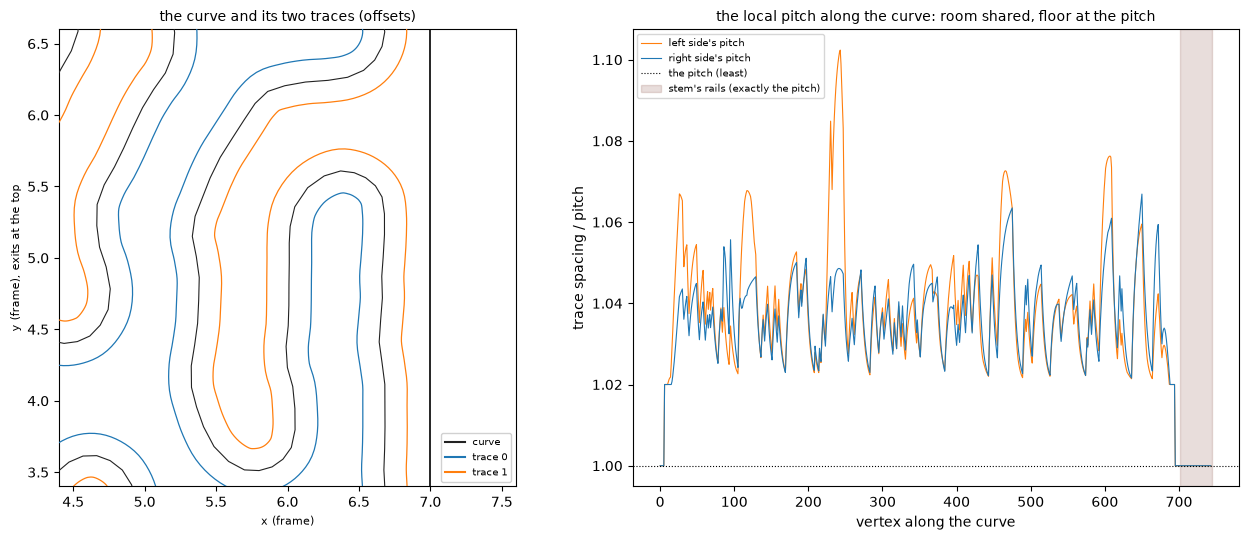

In [32]:
def lanes_check(L):
    edge = list(zip(pts(L["edge_a"]), pts(L["edge_b"])))
    trace = {}
    out = lanes(pts(L["p"]), L["k"], edge, L["n"], L["pitch"], L["spacing"], L["exact"], {**LANE_PARAMS, **L["params"]}, trace)
    same = all(len(a) == len(b) and all(x == tuple(y) for x, y in zip(a, b)) for a, b in zip(out, L["out"]))
    return same, out, trace


c = CASES["one"]
L = c["lanes"][0]
same, out, trace = lanes_check(L)
print("lanes bit-for-bit equal to the core's:", same)
fr, fmask, fzones, _ = frame_geoms(c)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
line(ax, L["p"], color=CURVE, lw=0.8, zorder=3)
for t, tr in enumerate(out):
    line(ax, tr, color=TRACE[t], lw=0.9, zorder=4)
base(ax, fmask, fzones, "the curve and its two traces (offsets)")
frame_axes(ax)
zoom(ax, (6.0, 5.0), 1.6)
legend(ax, [("line", CURVE, "curve"), ("line", TRACE[0], "trace 0"), ("line", TRACE[1], "trace 1")], loc="lower right")
ax = axes[1]
pitch = L["pitch"]
for side, name, color in ((0, "left", TRACE[1]), (1, "right", TRACE[0])):
    ax.plot(np.array(trace["pitch"][side]) / pitch, color=color, lw=0.8, label=f"{name} side's pitch")
ax.axhline(1.0, color="black", lw=0.8, ls=":", label="the pitch (least)")
ax.axvspan(L["k"], len(L["p"]), color=STEM, alpha=0.2, label="stem's rails (exactly the pitch)")
ax.set_xlabel("vertex along the curve")
ax.set_ylabel("trace spacing / pitch")
ax.set_title("the local pitch along the curve: room shared, floor at the pitch", fontsize=10)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 3.13 Settling (simplified)

The offset traces are even on average but not locally: where two runs part, their outer traces leave a gap, and in tight bends the inner traces crowd. The core's settling (`settle::settle`, about 1,600 lines) moves each trace, vertex by vertex over `SETTLE` steps, toward the middle of the room on either side of it, never nearer other copper than a pitch and never across it.

**This port is simplified.** It keeps the main loop:

- `centring`: the middle between the nearest copper on either side, with the edge counting as copper at twice its distance.
- `crowded`: a push out of copper nearer than a pitch.
- Moves capped at `SETTLE_LEAP` of a step and cooled over the steps.
- Taubin smoothing of the jitter.
- `keep_clear`: moves that would come nearer than a pitch, or cross, are taken back.
- The final smoothing (`SETTLE_FINISH`), each step kept clear.
- Fixed vertices, held as in the core: trace ends, the exits, and zone crossings.

**Left out** (they refine coverage and length, not clearance):

- U-turn tips leaning into gaps (`SETTLE_TIP`, `SETTLE_REACH_OUT`)
- moving down the copper density's slope into holes (`SETTLE_FILL`)
- steering lengths while settling (`SETTLE_STEER`)
- filling the remaining holes one by one (phase 2)
- matching lengths at the end (`MATCH*`)

So this step is checked by its properties, not by its exact output: the ends unchanged, clearance as the core's, holes as small, lengths near the core's.

`sfc._settle` builds the core's inputs (the edge points, leaving out zone borders where traces cross them, the zones and what to keep as laid) and runs the core's three phases.

In [33]:
NONE = -1


class Traces:
    """Open polylines held as one list: each vertex's trace, and the vertex before and
    after it along it (NONE at its ends) (rust/core/src/traces.rs, without the places as
    laid that the length steering needs)."""

    def __init__(self, lines):
        self.p, self.net, self.prev, self.next, self.first = [], [], [], [], [0]
        for t, line in enumerate(lines):
            base = len(self.p)
            for k, q in enumerate(line):
                self.p.append(tuple(q))
                self.net.append(t)
                self.prev.append(NONE if k == 0 else base + k - 1)
                self.next.append(NONE if k + 1 == len(line) else base + k + 1)
            self.first.append(len(self.p))

    def __len__(self):
        return len(self.p)

    def lines(self):
        return [self.p[a:b] for a, b in zip(self.first, self.first[1:])]

    def arc(self):
        out = [0.0] * len(self.p)
        for i in range(len(self.p)):
            if self.prev[i] != NONE:
                out[i] = out[self.prev[i]] + dist(self.p[self.prev[i]], self.p[i])
        return out

    def normals(self):
        out = []
        for i in range(len(self.p)):
            a = i if self.prev[i] == NONE else self.prev[i]
            b = i if self.next[i] == NONE else self.next[i]
            t = sub(self.p[b], self.p[a])
            ln = max(norm(t), 1e-12)
            out.append((-t[1] / ln, t[0] / ln))
        return out

    def respaced(self, step):
        """At about ``step`` between vertices: a vertex on the line between its neighbours
        and nearer them than the step dropped, long segments split."""
        lines = []
        for a, b in zip(self.first, self.first[1:]):
            t = self.p[a:b]
            m = len(t)
            short = [False] * m
            for k in range(1, max(m - 1, 0)):
                short[k] = (dist(t[k - 1], t[k]) + dist(t[k], t[k + 1]) < step
                            and dist(closest(t[k], t[k - 1], t[k + 1])[0], t[k]) < 0.02 * step)
            t = [t[k] for k in range(m) if not (short[k] and not (k > 0 and short[k - 1]))]
            line = []
            for k in range(len(t) - 1):
                parts = max(as_usize(math.ceil(dist(t[k], t[k + 1]) / (1.5 * step))), 1)
                for j in range(parts):
                    line.append(add(t[k], scale(sub(t[k + 1], t[k]), float(j) / float(parts))))
            if t:
                line.append(t[-1])
            lines.append(line)
        return Traces(lines)


class Ctx:
    """What settling looks at: the pitch, the step between vertices, how near is near and
    how far it looks, the zones (no vertex moves from one into another), what is kept as
    laid (the exits) and the edge's points (the area's edge and the zones' borders but at
    the curve's joins)."""

    def __init__(self, pitch, prm, edge, zones, keep):
        self.pitch, self.step = pitch, prm["step"] * pitch
        self.near, self.far, self.own = 1.5 * pitch, prm["reach"] * pitch, 0.5 * pitch
        self.pin = as_usize(math.ceil(prm["reach"] / prm["step"]))
        self.zones, self.keep = Zones(zones, 2.0 * pitch), Zones(keep, 2.0 * pitch)
        self.edge = [tuple(q) for q in edge]
        self.edges = PointGrid(self.edge, self.far)


def settle_simple(lines, pitch, edge, zones, keep, prm, phases):
    """settle::settle, simplified (see the notebook): phase 1 settles, phase 4 smooths;
    phase 2 (filling holes) and the length matching are left out."""
    cx = Ctx(pitch, prm, edge, zones, keep)
    tr = Traces([resample_line([tuple(q) for q in t], cx.step) for t in lines] if phases & 1
                else [[tuple(q) for q in t] for t in lines])
    if phases & 1:
        hot = None
        for it in range(prm["steps"]):
            cool = (1.0 - it / prm["steps"]) ** prm["cool"]
            p = list(tr.p)
            arc, normal = tr.arc(), tr.normals()
            fixed, zone = held(tr, cx)
            look = range(len(tr)) if hot is None else [i for i in range(len(tr))
                                                       if cell_of(p[i], cx.near) in hot]
            verts = PointGrid(p, cx.near / 2.0)
            mv = [(0.0, 0.0)] * len(tr)
            for i in look:
                if fixed[i]:
                    continue
                if zone[i] is None:  # (out of the area, as the lanes left it: back in)
                    e = nearest_edge_point(cx, p[i], 4.0 * cx.far)
                    if e is not None:
                        v = sub(e, p[i])
                        mv[i] = scale(v, min(prm["leap"] * cx.step / max(norm(v), 1e-12), 1.0))
                    continue
                push = centring(tr, arc, normal, verts, cx, i) * prm["rate"] * cool
                m = add(scale(normal[i], push), crowded(tr, arc, verts, i, cx))
                size = norm(m)
                if size >= prm["still"] * pitch:
                    mv[i] = scale(m, min(prm["leap"] * cx.step / max(size, 1e-12), 1.0))
            new = [add(p[i], mv[i]) for i in range(len(tr))]
            # jitter smoothed away (Taubin) round what moved, but where fixed
            moving = [v != (0.0, 0.0) for v in mv]
            busy = [tr.prev[i] != NONE and tr.next[i] != NONE and not fixed[i]
                    and (moving[i] or moving[tr.prev[i]] or moving[tr.next[i]]) for i in range(len(tr))]
            for f in [0.3, -0.32] * prm["smooth"]:
                lp = [sub(scale(add(new[tr.prev[i]], new[tr.next[i]]), 0.5), new[i]) if busy[i]
                      else (0.0, 0.0) for i in range(len(tr))]
                new = [add(new[i], scale(lp[i], f)) if busy[i] else new[i] for i in range(len(tr))]
            for i in range(len(tr)):
                if dist(new[i], p[i]) < prm["still"] * pitch / 4.0 or cx.zones.of(new[i]) != zone[i]:
                    new[i] = p[i]
            new = keep_clear(tr, p, new, cx)
            moved = [i for i in range(len(tr)) if dist(new[i], p[i]) > 0.02 * pitch]
            if not moved:
                break
            hot = {(a + dx, b + dy) for i in moved for a, b in [cell_of(new[i], cx.near)]
                   for dx in (-1, 0, 1) for dy in (-1, 0, 1)}
            tr.p = new
            tr = tr.respaced(cx.step)
    if phases & 4:
        for _ in range(prm["finish"]):  # smoothed at the end, each step kept clear
            fixed, zone = held(tr, cx)
            p = list(tr.p)
            new = list(p)
            for f in (0.5, -0.53):
                lp = [(0.0, 0.0) if tr.prev[i] == NONE or tr.next[i] == NONE or fixed[i]
                      else sub(scale(add(new[tr.prev[i]], new[tr.next[i]]), 0.5), new[i]) for i in range(len(tr))]
                new = [add(new[i], scale(lp[i], f)) for i in range(len(tr))]
            new = [new[i] if cx.zones.of(new[i]) == zone[i] else p[i] for i in range(len(tr))]
            tr.p = keep_clear(tr, p, new, cx)
            tr = tr.respaced(cx.step)
    return tr.lines()


def held(tr, cx):
    """The vertices settling leaves where they are (the traces' ends and 4 vertices on, the
    exit, a few pitches either way of where a trace crosses into another zone), and each
    vertex's zone."""
    fixed = [tr.prev[i] == NONE or tr.next[i] == NONE or cx.keep.of(tr.p[i]) is not None
             for i in range(len(tr))]
    fixed = spread(tr, fixed, 4)
    zone = [cx.zones.of(q) for q in tr.p]
    join = [tr.next[i] != NONE and zone[i] is not None and zone[tr.next[i]] is not None
            and zone[i] != zone[tr.next[i]] for i in range(len(tr))]
    join = spread(tr, join, cx.pin)
    return [a or b for a, b in zip(fixed, join)], zone


def spread(tr, mask, k):
    for _ in range(k):
        was = list(mask)
        for i in range(len(tr)):
            if (tr.prev[i] != NONE and was[tr.prev[i]]) or (tr.next[i] != NONE and was[tr.next[i]]):
                mask[i] = True
    return mask


def centring(tr, arc, normal, verts, cx, i):
    """How far (to the left: positive) the middle between the nearest copper either side
    of vertex i is, short of a pitch from it (half one from the edge, which stands for
    copper at twice its distance); nothing within reach: a hole, moved into."""
    q, n, t = tr.p[i], normal[i], tr.net[i]
    side = [cx.far, cx.far]

    def look(r):
        for j, d2 in verts.within(q, r):
            if d2 <= 0.0:
                continue
            v, dd = sub(tr.p[j], q), math.sqrt(d2)
            if tr.net[j] == t and abs(arc[j] - arc[i]) <= cx.own:
                continue
            a = dot(v, n)
            if a >= 0.7 * dd:
                side[0] = min(side[0], dd)
            elif -a >= 0.7 * dd:
                side[1] = min(side[1], dd)

    look(cx.near)
    if side[0] >= cx.far or side[1] >= cx.far:
        look(cx.far)
    de = [cx.far, cx.far]
    for e, d2 in cx.edges.within(q, 2.0 * cx.far):
        v, d = sub(cx.edge[e], q), math.sqrt(d2)
        k = 0 if dot(v, n) > 0.0 else 1
        if dot(v, n) != 0.0 and d < de[k]:
            de[k] = d
    left, right = min(side[0], 2.0 * de[0]), min(side[1], 2.0 * de[1])
    push = (left - right) / 2.0
    if push > 0.0:
        return min(push, min(left - cx.pitch, de[0] - cx.pitch / 2.0))
    return max(push, -min(right - cx.pitch, de[1] - cx.pitch / 2.0))


def crowded(tr, arc, verts, i, cx):
    """The way out of copper nearer than a pitch to vertex i, as far as it is too near."""
    need = 1.01 * cx.pitch
    q = tr.p[i]
    out = (0.0, 0.0)
    for s, _ in verts.within(q, need + cx.step):
        s1 = tr.next[s]
        if s1 == NONE:
            continue
        c, t = closest(q, tr.p[s], tr.p[s1])
        v = sub(q, c)
        d = norm(v)
        if d >= need or d < 1e-12:
            continue
        if tr.net[s] == tr.net[i] and abs(arc[s] + t * (arc[s1] - arc[s]) - arc[i]) <= 2.0 * need:
            continue  # (its own copper, just along it)
        away = scale(v, (need - d) / 2.0 / d)
        if norm(away) > norm(out):
            out = away
    return out


def nearest_edge_point(cx, q, reach):
    best = None
    for e, d2 in cx.edges.within(q, reach):
        if best is None or d2 < best[0]:
            best = (d2, e)
    return None if best is None else cx.edge[best[1]]


def keep_clear(tr, old, new, cx):
    """``new`` with the vertices that would come nearer other copper than a pitch (or its
    own copper where it faces itself), or nearer the edge than half one, or whose segments
    would cross, back where they were (``old``); the whole step back if that does not
    settle within 100 rounds."""
    need = 1.01 * cx.pitch
    n = len(tr)
    tmp = Traces([])
    tmp.p, tmp.prev, tmp.next = new, tr.prev, tr.next
    arc, normal = tmp.arc(), tmp.normals()
    longest = max([max(dist(new[i], new[tr.next[i]]), dist(old[i], old[tr.next[i]]))
                   for i in range(n) if tr.next[i] != NONE] or [0.0])
    grow = max([dist(new[i], old[i]) for i in range(n)] or [0.0])
    reach = need + longest
    segs = PointGrid(new, (reach + grow) / 2.0, lambda i: tr.next[i] != NONE)
    new = list(new)
    for _ in range(100):
        moved = [i for i in range(n) if new[i] != old[i]]
        if not moved:
            return new
        is_moved = [new[i] != old[i] for i in range(n)]
        look = set(moved)
        for q in moved:
            for s, _ in segs.within(new[q], reach + grow):
                look.update((s, tr.next[s]))
        back = set()
        for q in sorted(look):
            tangent = (normal[q][1], -normal[q][0])
            bad = []
            for s, _ in segs.within(new[q], reach + grow):
                s1 = tr.next[s]
                if not (is_moved[q] or is_moved[s] or is_moved[s1]):
                    continue
                c, t = closest(new[q], new[s], new[s1])
                v = sub(c, new[q])
                d = norm(v)
                if d >= need or d >= dist(closest(old[q], old[s], old[s1])[0], old[q]):
                    continue
                if tr.net[s] != tr.net[q]:
                    clash = True
                else:
                    sep = abs(arc[s] + t * (arc[s1] - arc[s]) - arc[q])
                    clash = sep > cx.own and (abs(dot(v, tangent)) < 0.5 * max(d, 1e-12) or sep > 2.0 * d)
                if clash:
                    bad = [x for x in (q, s, s1) if is_moved[x]]
                    break
            if not bad and is_moved[q]:  # (the edge: no nearer than half a pitch)
                half = cx.pitch / 2.0
                now = min([math.sqrt(d2) for _, d2 in cx.edges.within(new[q], half)] or [math.inf])
                was = min([math.sqrt(d2) for _, d2 in cx.edges.within(old[q], half)] or [math.inf])
                if now < half and now < was:
                    bad = [q]
            back.update(bad)
        for s in moved:  # segments that cross
            for a in (s, tr.prev[s]):
                if a == NONE or tr.next[a] == NONE:
                    continue
                a1 = tr.next[a]
                for h, _ in segs.within(new[a], dist(new[a], new[a1]) + longest + grow):
                    if h in (a, tr.prev[a], a1):
                        continue
                    if crosses(new[a], new[a1], new[h], new[tr.next[h]]):
                        back.update((a, a1, h, tr.next[h]))
        back = {b for b in back if is_moved[b]}
        if not back:
            return new
        for b in back:
            new[b] = old[b]
    return list(old)

In [34]:
def _settle(
    lines: list[np.ndarray],
    pitch: float,
    area: shapely.Geometry,
    regions: list[Polygon],
    keep: shapely.Geometry,
    groups: list[int] | None = None,
    ribbon: int | None = None,
) -> list[np.ndarray]:
    """The traces, each settled on its own into the room around it, then matched in length
    (within each of their ``groups``: ``mesh.matching``'s pairs; ``ribbon`` traces abreast),
    by the Rust core (rust/core; see ARCHITECTURE.md, Settling): natively its extension
    (yanartas_mesh, on all cores), in the browser its WebAssembly build. Here, what needs
    shapely: the edge's points (the area's edge, and the zones' borders but where the
    traces cross them at the curve's joins, where they stay as laid), the zones' rings, and
    what is left as laid (``keep``: the exits)."""
    step = SETTLE_STEP * pitch
    far = SETTLE_REACH * pitch
    edge = np.vstack([resample(np.asarray(r.coords), step / 2) for r in _rings(area)])
    borders = _borders(regions, area, step / 2)
    xs = shapely.get_coordinates(
        shapely.intersection(
            shapely.MultiLineString(lines), shapely.union_all([r.boundary for r in regions])
        )
    )
    if len(borders) and len(xs):
        near_x = Grid(xs, far).nearest(borders)
        clear = (near_x < 0) | (np.hypot(*(borders - xs[np.maximum(near_x, 0)]).T) > far)
        edge = np.vstack([edge, borders[clear]])
    elif len(borders):
        edge = np.vstack([edge, borders])
    laid = [np.ascontiguousarray(t, float) for t in lines]
    room = (
        pitch,
        np.ascontiguousarray(edge, float),
        [[np.asarray(r.coords, float) for r in _rings(z)] for z in regions],
        [[np.asarray(r.coords, float) for r in _rings(g)] for g in _polygons(keep)],
    )
    params = _params(len(lines) if ribbon is None else ribbon)
    # (in its phases, each a step of its own: timed, and checkpointed when asked)
    out = _settling(laid, *room, params, groups)
    out = _filling(out, *room, params, groups, laid)
    return _finishing(out, *room, params, groups, laid)


def _settle_phase(
    phases: int,
    lines: list[np.ndarray],
    pitch: float,
    edge: np.ndarray,
    zones: list[list[np.ndarray]],
    keep: list[list[np.ndarray]],
    params: dict[str, float],
    groups: list[int] | None,
    base: list[np.ndarray] | None = None,
) -> list[np.ndarray]:
    """``_settle``'s ``phases`` (1: settling, 2: filling the holes, 4: smoothing and
    matching) by the Rust core, on from ``lines`` (``base``: the traces as first laid)."""

    def report(d: dict) -> None:
        progress.report(d.pop("phase"), d.pop("step"), d.pop("steps"), **d)

    out = _core().settle_traces(
        [np.ascontiguousarray(t, float) for t in lines], pitch, edge, zones, keep,
        {**params, "phases": phases}, report, groups,
        None if base is None else [np.ascontiguousarray(t, float) for t in base],
    )  # fmt: skip
    return [np.asarray(t) for t in out]


def _settling(*a: Any) -> list[np.ndarray]:
    return _settle_phase(1, *a)


def _filling(*a: Any) -> list[np.ndarray]:
    return _settle_phase(2, *a)


def _finishing(*a: Any) -> list[np.ndarray]:
    return _settle_phase(4, *a)


def _params(traces: int = SCALE) -> dict[str, float]:
    """The settling's constants, by the Rust core's names for them, for ``traces`` traces
    (the holes left where a ribbon's bends meet grow with its width: more steps for them,
    and U-turn tips leaning out further into them)."""
    more = max(1.0, traces / SCALE)
    return {
        "steps": round(SETTLE * more),
        "rate": SETTLE_RATE,
        "reach": SETTLE_REACH,
        "pin": SETTLE_PIN,
        "cool": SETTLE_COOL,
        "step": SETTLE_STEP,
        "still": SETTLE_STILL,
        "band": SETTLE_BAND,
        "leap": SETTLE_LEAP,
        "tune": SETTLE_TUNE,
        "steer": SETTLE_STEER,
        "span": SETTLE_SPAN,
        "steer_cool": SETTLE_STEER_COOL,
        "tip": SETTLE_TIP * more,
        "reach_out": SETTLE_REACH_OUT * more,
        "fill": SETTLE_FILL,
        "fill_blur": SETTLE_FILL_BLUR,
        "bend": SETTLE_BEND,
        "smooth": SETTLE_SMOOTH,
        "finish": SETTLE_FINISH,
        "match_steps": MATCH,
        "match_band": MATCH_BAND,
        "match_rate": MATCH_RATE,
        "ribbon": float(SETTLE_RIBBON),
        "share": float(SETTLE_SHARE),
        "holes": SETTLE_HOLE,
        "hole_steps": SETTLE_HOLE_STEPS,
        "hole_margin": SETTLE_HOLE_MARGIN,
        "hole_ribbon": float(SETTLE_HOLE_RIBBON),
    }

In [35]:
def settle_metrics(lines_, s):
    """Clearance (the least distance between two traces), the largest hole (area further
    than a pitch from every trace, within the area less a pitch), and each trace's length."""
    ls = [LineString(x) for x in lines_]
    gap = min(a.distance(b) for i, a in enumerate(ls) for b in ls[i + 1:])
    inner = geom(s["area"]).buffer(-s["pitch"])
    bare = inner.difference(shapely.union_all([x.buffer(s["pitch"]) for x in ls]))
    hole = max([p.area for p in shapely.get_parts(bare)] or [0.0])
    return gap, hole, [x.length for x in ls]


def settle_run(c):
    s = c["settle"]
    t0 = time.perf_counter()
    out = _settle([np.asarray(x) for x in s["lines"]], s["pitch"], geom(s["area"]), [geom(r) for r in s["regions"]],
                  geom(s["keep"]), s["groups"], s["ribbon"])
    return out, time.perf_counter() - t0


_core = lambda: core  # (sfc's _core: the ports; ``core`` is defined in 3.15 with the rest)

(The settling plot comes after 3.15, where `core`, the ports behind the core's calls, is defined.)

### 3.14 Drawing: smooth curves, or lines and arcs

The settled traces are polylines with a vertex every third of a pitch. `_output` draws each one in one of two ways:

- **Smooth** (`arcs::smooth_all`). The smooth curve through the vertices (a cubic Hermite curve with tangents along each vertex's neighbours, refined so that no two segments turn more than `MAX_TURN` apart), simplified again within `SIMPLIFY`.
- **Lines and circular arcs** (`arcs::fit_all`, for exports that take arcs). Each run of vertices that a line or an arc follows within a tolerance becomes one piece, greedily, the longest from each start. The tolerance is larger where the trace has room to the copper beside it (`rooms`). The arc through a run's ends is found by a golden-section search over its sagitta.

Either way, a segment whose smooth curve would come nearer the copper beside it than the pitch stays straight (`refine_all`). Last, `_output` turns the traces back from the frame and orders each partition's nets, outermost first.

In [36]:
SPAN = 64  # the most vertices one piece takes


OWN_REACH = 1.8  # a trace's own copper not counted as beside it this many pitches along


HAIRPIN_REACH = 4.0  # ... the other leg of the same hairpin within this many


HAIRPIN_GIVE = 0.25  # ... which may come this share of a pitch nearer


OWN_SLACK = 1.1  # the polyline's own error taken this much larger: rounding


TRACES, EDGES, ALL = "traces", "edges", "all"


def circle(a, b, c):
    """The circle through three points (centre, radius), if they are not in a line."""
    d = 2.0 * (a[0] * (b[1] - c[1]) + b[0] * (c[1] - a[1]) + c[0] * (a[1] - b[1]))
    if abs(d) < 1e-12:
        return None
    a2, b2, c2 = a[0] * a[0] + a[1] * a[1], b[0] * b[0] + b[1] * b[1], c[0] * c[0] + c[1] * c[1]
    o = ((a2 * (b[1] - c[1]) + b2 * (c[1] - a[1]) + c2 * (a[1] - b[1])) / d,
         (a2 * (c[0] - b[0]) + b2 * (a[0] - c[0]) + c2 * (b[0] - a[0])) / d)
    return o, dist(o, a)


def run(p, tol, i, j):
    """The run p[i..=j] and the middles of its segments, each with its tolerance."""
    out = []
    for k in range(i, j + 1):
        out.append((p[k], tol[k]))
        if k < j:
            out.append((scale(add(p[k], p[k + 1]), 0.5), 0.5 * (tol[k] + tol[k + 1])))
    return out


def line_fits(p, tol, i, j):
    return all(dist(closest(q, p[i], p[j])[0], q) <= t for q, t in run(p, tol, i, j))


def arc_fits(p, tol, i, j):
    """The arc through p[i] and p[j] the run follows within tol (its middle), if any: of
    those through the ends, the one nearest the run at its worst (a golden-section search
    over the sagitta), turning one way, less than a full turn."""
    a, b = p[i], p[j]
    chord = dist(a, b)
    if chord < 1e-12:
        return None
    m = scale(add(a, b), 0.5)
    nv = (-(b[1] - a[1]) / chord, (b[0] - a[0]) / chord)
    pts = run(p, tol, i, j)

    def apex(s):
        return add(m, scale(nv, s))

    def worst(s):
        c = circle(a, apex(s), b)
        if c is None:
            return math.inf
        o, r = c
        w = 0.0
        for q, t in pts:
            w = max(w, abs(dist(q, o) - r) / t)
        return w

    sags = []
    span = j - i
    for kk in range(1, 6):
        v = i + (span * kk) // 6
        if v <= i or v >= j:
            continue
        c = circle(a, p[v], b)
        if c is not None:
            o, r = c
            side = (p[v][0] - m[0]) * nv[0] + (p[v][1] - m[1]) * nv[1]
            h = (o[0] - m[0]) * nv[0] + (o[1] - m[1]) * nv[1]
            s = h + r if side >= 0.0 else h - r
            if math.isfinite(s):
                sags.append(s)
    if not sags:
        return None
    lo, hi = math.inf, -math.inf
    for s in sags:
        lo, hi = min(lo, s), max(hi, s)
    pad = 0.1 * (hi - lo) + max(tol[i], tol[j])
    lo -= pad
    hi += pad
    g = 0.5 * (math.sqrt(5.0) - 1.0)
    x1, x2 = hi - g * (hi - lo), lo + g * (hi - lo)
    f1, f2 = worst(x1), worst(x2)
    for _ in range(40):
        if f1 <= f2:
            hi, x2, f2 = x2, x1, f1
            x1 = hi - g * (hi - lo)
            f1 = worst(x1)
        else:
            lo, x1, f1 = x1, x2, f2
            x2 = lo + g * (hi - lo)
            f2 = worst(x2)
    s = x1 if f1 <= f2 else x2
    if abs(s) < 1e-12 or worst(s) > 1.0:
        return None
    mid = apex(s)
    c = circle(a, mid, b)
    if c is None:
        return None
    o = c[0]

    def angle(q):
        return math.atan2(q[1] - o[1], q[0] - o[0])

    prev, sweep, sense = angle(a), 0.0, 0.0
    for q, _ in pts[1:]:
        an = angle(q)
        stp = an - prev
        if stp > math.pi:
            stp -= 2.0 * math.pi
        elif stp < -math.pi:
            stp += 2.0 * math.pi
        if sense == 0.0:
            sense = signum(stp)
        elif stp * sense < -1e-12:
            return None  # (back the other way round)
        sweep += stp
        prev = an
    if abs(sweep) >= 1.9 * math.pi:
        return None
    return mid


def fit(p, tol):
    own = own_error(p)
    return fit_within(p, [max(e, tol) for e in own])


def own_error(p):
    """How far a polyline's own vertices and chords may be off the smooth curve they stand
    for: a chord's sagitta on the circle through its turn, L θ / 8 (a tenth more)."""
    n = len(p)
    out = []
    for kk in range(n):
        if kk == 0 or kk + 1 == n:
            out.append(0.0)
            continue
        a, b = dist(p[kk - 1], p[kk]), dist(p[kk], p[kk + 1])
        if a < 1e-12 or b < 1e-12:
            out.append(0.0)
            continue
        u = ((p[kk][0] - p[kk - 1][0]) / a, (p[kk][1] - p[kk - 1][1]) / a)
        v = ((p[kk + 1][0] - p[kk][0]) / b, (p[kk + 1][1] - p[kk][1]) / b)
        turn = abs(math.atan2(u[0] * v[1] - u[1] * v[0], u[0] * v[0] + u[1] * v[1]))
        out.append(OWN_SLACK * 0.5 * (a + b) * turn / 8.0)
    return out


def fit_within(p, tol):
    """The polyline as lines and arcs within tol[k] of it at its vertex k: greedily, the
    longest piece from each start (doubling, then halving)."""
    n = len(p)
    out = []
    if n < 2:
        return out

    def piece(i, j):
        if line_fits(p, tol, i, j):
            return ("line", p[i], p[j])
        if j - i >= 2:
            mid = arc_fits(p, tol, i, j)
            if mid is not None:
                return ("arc", p[i], mid, p[j])
        return None

    i = 0
    while i + 1 < n:
        good, bad, stride = i + 1, None, 1
        while bad is None:
            j = min(i + 2 * stride, n - 1, i + SPAN)
            if j == good:
                break
            if piece(i, j) is not None:
                good = j
                stride *= 2
                if j == n - 1:
                    break
            else:
                bad = j
        if bad is not None:
            hi = bad
            while hi - good > 1:
                mid = (good + hi) // 2
                if piece(i, mid) is not None:
                    good = mid
                else:
                    hi = mid
        out.append(piece(i, good) or ("line", p[i], p[good]))
        i = good
    return out


def fit_all(lines, edges, tol, pitch, most, max_turn, give):
    """Each trace as lines and arcs, fitted to the smooth curve through its vertices:
    within tol of it everywhere, further where it has room to the copper beside it, as far
    as that allows, up to the more of ``most`` and its own error."""
    refined = refine_all(lines, edges, pitch, max_turn / 2.0, give)
    if pitch <= 0.0:
        return [fit(ln, tol) for ln in refined]
    room = rooms_to(refined, edges, pitch, pitch + 4.0 * max(most, tol), ALL)
    out = []
    for line, rm in zip(refined, room):
        own = own_error(line)
        tols = [max(min(max(r, 0.0), max(e, most)), tol) for e, r in zip(own, rm)]
        out.append(fit_within(line, tols))
    return out


def rooms_to(lines, edges, pitch, reach, which):
    return [[r for r, _ in ln] for ln in rooms_by(lines, edges, pitch, reach, which)]


def rooms_by(lines, edges, pitch, reach, which):
    """How far each vertex may move and its traces keep the pitch apart (half of how much
    further than the pitch the nearest other trace is, or its own past a U-turn; all of how
    much further than half a pitch the area's edge is), with the trace segment nearest."""
    a, b, owner = [], [], []
    for li, line in enumerate(lines):
        s = 0.0
        for si in range(len(line) - 1):
            seg_len = dist(line[si], line[si + 1])
            a.append(line[si])
            b.append(line[si + 1])
            owner.append(((li, si), s, s + seg_len))
            s += seg_len
    for ring_ in edges:
        for kk in range(len(ring_)):
            a.append(ring_[kk])
            b.append(ring_[(kk + 1) % len(ring_)])
            owner.append((None, 0.0, 0.0))
    segs = Segs(a, b, reach)
    own, hairpin = OWN_REACH * pitch, HAIRPIN_REACH * pitch
    out = []
    for li, line in enumerate(lines):
        s = 0.0
        res = []
        for kk, q in enumerate(line):
            if kk > 0:
                s += dist(line[kk - 1], q)
            room, nearest = reach, None
            for i in segs.around((q[0] - reach, q[1] - reach), (q[0] + reach, q[1] + reach)):
                o, s0, s1 = owner[i]
                d = dist(closest(q, segs.a[i], segs.b[i])[0], q)
                if o is None:
                    if which == TRACES:
                        continue
                    r = d - pitch / 2.0
                else:
                    if which == EDGES:
                        continue
                    if o[0] == li and s0 - own < s < s1 + own:
                        continue  # (the trace itself, here: its own curve)
                    if o[0] == li and s0 - hairpin < s < s1 + hairpin:
                        r = (d - pitch) / 2.0 + HAIRPIN_GIVE * pitch
                    else:
                        r = (d - pitch) / 2.0
                if r < room:
                    room, nearest = r, o
            res.append((room, nearest))
        out.append(res)
    return out


def refine(p, max_turn):
    return refine_where(p, max_turn, [True] * max(len(p) - 1, 0))[0]


def refine_where(p, max_turn, allow):
    """The smooth curve the polyline stands for: a cubic Hermite curve through every vertex
    (tangent along its neighbours' chord), each allowed segment split as finely as its
    tangents turn; with the segment each point lies on."""
    n = len(p)
    if n < 3 or max_turn <= 0.0:
        return list(p), [max(kk - 1, 0) for kk in range(n)]

    def unit(d):
        ln = norm(d)
        return (0.0, 0.0) if ln < 1e-12 else scale(d, 1.0 / ln)

    tangent = []
    for kk in range(n):
        if kk == 0:
            tangent.append(unit(sub(p[1], p[0])))
        elif kk == n - 1:
            tangent.append(unit(sub(p[n - 1], p[n - 2])))
        else:
            tangent.append(unit(sub(p[kk + 1], p[kk - 1])))
    out, seg = [p[0]], [0]
    for kk in range(n - 1):
        a, b = p[kk], p[kk + 1]
        ln = dist(a, b)
        ta, tb = tangent[kk], tangent[kk + 1]
        turn = abs(math.atan2(ta[0] * tb[1] - ta[1] * tb[0], ta[0] * tb[0] + ta[1] * tb[1]))
        m = max(as_usize(math.ceil(turn / max_turn)), 1) if allow[kk] else 1
        for i in range(1, m):
            t = float(i) / float(m)
            t2, t3 = t * t, t * t * t
            h00, h10, h01, h11 = 2.0 * t3 - 3.0 * t2 + 1.0, t3 - 2.0 * t2 + t, -2.0 * t3 + 3.0 * t2, t3 - t2
            out.append((h00 * a[0] + h10 * ln * ta[0] + h01 * b[0] + h11 * ln * tb[0],
                        h00 * a[1] + h10 * ln * ta[1] + h01 * b[1] + h11 * ln * tb[1]))
            seg.append(kk)
        out.append(b)
        seg.append(kk)
    return out, seg


def refine_all(lines, edges, pitch, max_turn, give):
    """Each line refined, but a segment whose curve would come nearer the copper beside it
    than the pitch, and nearer than its chord did (by more than ``give``), kept straight."""
    if max_turn <= 0.0 or pitch <= 0.0:
        return [refine(ln, max_turn) for ln in lines]
    reach = 1.5 * pitch
    kinds = (TRACES, EDGES)
    before = [rooms_to(lines, edges, pitch, reach, c) for c in kinds]
    inherent = [own_error(ln) for ln in lines]
    allow = [[True] * max(len(ln) - 1, 0) for ln in lines]
    out = []
    for _ in range(6):
        out = [refine_where(ln, max_turn, a) for ln, a in zip(lines, allow)]
        pts = [o[0] for o in out]
        changed = False
        for c, kind in enumerate(kinds):
            after = rooms_by(pts, edges, pitch, reach, kind)
            for li, (_, seg) in enumerate(out):
                for q, kk in enumerate(seg):
                    kk = min(kk, max(len(lines[li]) - 2, 0))
                    room, nearest = after[li][q]
                    slack = 0.5 * max(inherent[li][kk], inherent[li][kk + 1]) if (
                        nearest is not None and nearest[0] == li) else 0.0
                    floor = min(before[c][li][kk], before[c][li][kk + 1], 0.0) - give * pitch / 2.0 - slack
                    if room >= floor - 1e-9:
                        continue
                    # (straight: this point's segment, and the one crowding it)
                    if allow[li][kk]:
                        allow[li][kk] = False
                        changed = True
                    if nearest is not None:
                        ol, os_ = nearest
                        ok = min(out[ol][1][os_ + 1], max(len(lines[ol]) - 2, 0))
                        if allow[ol][ok]:
                            allow[ol][ok] = False
                            changed = True
        if not changed:
            break
    return [o[0] for o in out]


def simplify(p, tol, max_turn):
    """As few vertices as keep it within tol and each segment within a quarter of max_turn
    of the polyline's own along it (greedy)."""
    n = len(p)
    if n < 3:
        return list(p)

    def heading(a, b):
        return math.atan2(b[1] - a[1], b[0] - a[0])

    def wrap(x):
        return rem_euclid(x + math.pi, 2.0 * math.pi) - math.pi

    out, i = [p[0]], 0
    while i + 1 < n:
        j = i + 1
        while j + 1 < n:
            kk = j + 1
            fits = all(dist(closest(p[v], p[i], p[kk])[0], p[v]) <= tol for v in range(i + 1, kk))
            chord = heading(p[i], p[kk])
            turns = all(abs(wrap(heading(p[v], p[v + 1]) - chord)) <= max_turn / 4.0 for v in range(i, kk))
            if not (fits and turns) or kk - i > SPAN:
                break
            j = kk
        out.append(p[j])
        i = j
    return out


def smooth_all(lines, edges, pitch, tol, max_turn, give):
    """Each trace as the smooth curve through its vertices, simplified again within tol."""
    return [simplify(ln, tol, max_turn) for ln in refine_all(lines, edges, pitch, max_turn / 2.0, give)]


def piece_row(pc):
    """A piece as the core returns it: kind (0 line, 1 arc), start, middle, end."""
    if pc[0] == "line":
        a, b = pc[1], pc[2]
        return [0.0, a[0], a[1], (a[0] + b[0]) / 2.0, (a[1] + b[1]) / 2.0, b[0], b[1]]
    a, m, b = pc[1:]
    return [1.0, a[0], a[1], m[0], m[1], b[0], b[1]]

In [37]:
def _output(
    flat: list[np.ndarray],
    frame: _Frame,
    arcs: bool,
    pitch: float,
    exits: list[tuple[float, float]],
    c: float,
    groups: list[int],
    pair: list[int],
    partitions: Sequence[shapely.Geometry],
    cells: int,
    left: int,
    corners: list[tuple[float, float]],
    area: shapely.Geometry | None = None,
    regions: Sequence[Polygon] = (),
) -> Mesh:
    """``generate``'s mesh from its settled traces, each drawn as the smooth curve through
    its vertices: in segments within ``SIMPLIFY`` (scaled to the pitch) of it, no two
    turning more than ``MAX_TURN`` from one another; or fitted with arcs, within ``ARCS``
    of it and where a trace has room to the copper beside it and to the ``area``'s edge,
    further, up to ``ARCS_ROOM`` pitches (the ``regions``' borders, e.g. folds, kept as
    the area's edges). Back in the board's frame, its nets in order."""
    out: list[np.ndarray] = []
    shapes: list[tuple[Piece, ...] | None] = []
    edges = [
        np.ascontiguousarray(np.asarray(ring.coords, float)[:-1])
        for poly in [*([] if area is None else _polygons(area)), *regions]
        for ring in (poly.exterior, *poly.interiors)
    ]
    lines = [np.ascontiguousarray(xy, float) for xy in flat]
    if arcs:
        tol = ARCS * pitch / 0.3
        for rows in _core().fit_arcs(
            lines, tol, pitch, ARCS_ROOM * pitch, edges, MAX_TURN, TURN_GIVE
        ):
            ends = frame.inv(np.asarray(rows, float)[:, 1:].reshape(-1, 2)).reshape(-1, 3, 2)
            pieces = tuple(
                (
                    (float(a[0]), float(a[1])),
                    (float(m[0]), float(m[1])) if kind else None,
                    (float(b[0]), float(b[1])),
                )
                for kind, (a, m, b) in zip(np.asarray(rows)[:, 0], ends, strict=True)
            )
            shapes.append(pieces)
            out.append(np.asarray(sample_arcs(pieces, tol)))
    else:
        tol = SIMPLIFY * pitch / 0.3
        for xy in _core().smooth_traces(lines, tol, MAX_TURN, pitch, edges, TURN_GIVE):
            out.append(frame.inv(np.asarray(xy, float)))
            shapes.append(None)
    # each partition's net 1 outermost: its ends farthest from its exit's middle
    order = []
    for k, (x0, y0) in enumerate(exits):
        mid = frame.inv(np.array([[x0 + c / 2, y0]]))[0]
        mine = [i for i in range(len(out)) if groups[i] == k]
        order += sorted(mine, key=lambda i, m=mid: -math.dist(out[i][0], m))
    nets = tuple(tuple((float(x), float(y)) for x, y in out[i]) for i in order)
    shaped = tuple(shapes[i] for i in order) if arcs else None
    sizes = tuple(groups.count(k) for k in range(len(exits)))
    matched = sum((matching(m) for m in sizes), ()) if pair is not groups else ()
    if not partitions:
        return Mesh(nets, c, cells, left, corners[0], "sfc", shaped, matched=matched)
    return Mesh(nets, c, cells, left, corners[0], "sfc", shaped, sizes, tuple(partitions), matched)

arcs fitted in 10.7 s; bit-for-bit equal to the core's: True
966 pieces: 915 arcs, 51 lines (from 3441 vertices)


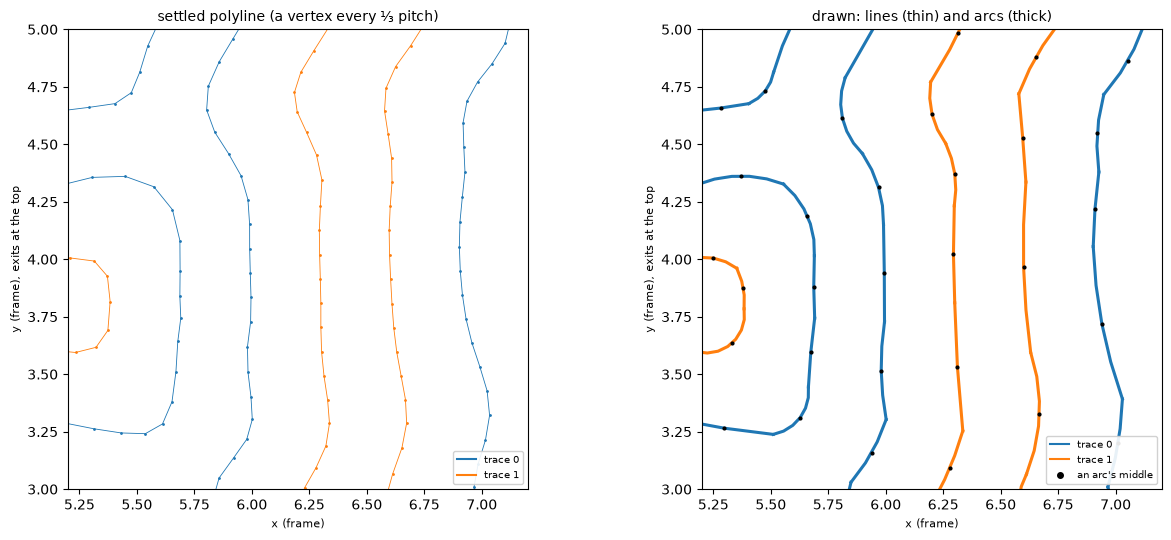

In [38]:
def output_check(c):
    """The port's drawing on the recorded settled traces against the core's: exact."""
    o = c["output"]
    ls = [pts(x) for x in c["settle"]["out"]]
    edges = [pts(x) for x in o["edges"]]
    a = o["args"]
    t0 = time.perf_counter()
    if o["call"] == "smooth_traces":
        out = smooth_all(ls, edges, a["pitch"], a["tol"], a["max_turn"], a["give"])
        same = all(len(x) == len(y) and all(p == tuple(q) for p, q in zip(x, y)) for x, y in zip(out, o["out"]))
    else:
        out = fit_all(ls, edges, a["tol"], a["pitch"], a["most"], a["max_turn"], a["give"])
        same = all(len(x) == len(y) and all(piece_row(pc) == list(r) for pc, r in zip(x, y)) for x, y in zip(out, o["out"]))
    return same, out, time.perf_counter() - t0


c = CASES["arcs"]
same, pieces, dt = output_check(c)
print(f"arcs fitted in {dt:.1f} s; bit-for-bit equal to the core's: {same}")
settled = c["settle"]["out"]
kinds = [pc[0] for t in pieces for pc in t]
print(f"{len(kinds)} pieces: {kinds.count('arc')} arcs, {kinds.count('line')} lines "
      f"(from {sum(len(t) for t in settled)} vertices)")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
centre = (6.2, 4.0)
for ax, title in ((axes[0], "settled polyline (a vertex every ⅓ pitch)"), (axes[1], "drawn: lines (thin) and arcs (thick)")):
    fr, fmask, fzones, _ = frame_geoms(c)
    base(ax, fmask, fzones, title)
    frame_axes(ax)
    zoom(ax, centre, 1.0)
for t, tr in enumerate(settled):
    axes[0].plot(*np.array(tr).T, ".-", color=TRACE[t], ms=2, lw=0.6)
for t, ps in enumerate(pieces):
    for pc in ps:
        if pc[0] == "line":
            line(axes[1], [pc[1], pc[2]], color=TRACE[t], lw=0.8)
        else:
            a, m, b = pc[1:]
            o_, r_ = circle(a, m, b)
            sampled = sample_arcs([(a, m, b)], 0.002)
            line(axes[1], sampled, color=TRACE[t], lw=2.2)
            axes[1].plot(*m, marker="o", ms=2, color="black")
legend(axes[0], [("line", TRACE[0], "trace 0"), ("line", TRACE[1], "trace 1")], loc="lower right")
legend(axes[1], [("line", TRACE[0], "trace 0"), ("line", TRACE[1], "trace 1"), ("dot", "black", "an arc's middle")],
       loc="lower right")
plt.tight_layout()
plt.show()

### 3.15 Putting it together

`Core` stands in for the Rust core: each call `sfc.py` makes (`yanartas_mesh.curve_graph`, `relax_curve`, …) goes to its port. It also records each call's inputs and outputs, for the checks in section 4. With `given_cells` it builds the curve graphs from the recorded cells (see 3.4).

`generate` is `sfc.py`'s driver, verbatim. It runs the steps above in order, for all partitions at once.

In [39]:
class Core:
    """The Rust core's calls as sfc.py makes them (rust/python/src/lib.rs), each on its
    port. ``given_cells``: cells to build the next curve graphs from (a queue, one entry
    per call: each segment's cells), as recorded from the core, for exact checks."""

    def __init__(self):
        self.reset()

    def reset(self, given_cells=()):
        """Before a run: the cells to build its graphs from (none: computed), and the calls
        recorded afresh (``calls``: each entry point's inputs and outputs; ``traces``: what
        the steps kept for the plots)."""
        self.given_cells = list(given_cells)
        self.traces = {}
        self.calls = {"graph": [], "relax": [], "lanes": [], "settle": [], "output": []}

    def curve_graph(self, segments, borders, openings, spacing, key, params, report=None):
        segs = [{"region": int(ri), "domain": [[tuple(map(float, q)) for q in r] for r in rings]}
                for ri, rings in segments]
        bds = [(int(i), int(j), [[tuple(map(float, q)) for q in ln] for ln in lines])
               for i, j, lines in borders]
        ops = [(tuple(map(float, a)), tuple(map(float, b))) for a, b in openings]
        given = self.given_cells.pop(0) if self.given_cells else None
        trace = self.traces.setdefault("graph", [])
        trace.append({})
        found, ncells, lost = curve_graph_core(segs, bds, ops, spacing, key,
                                               {**GRAPH_PARAMS, **params}, given, trace[-1])
        self.calls["graph"].append(dict(segments=segs, borders=bds, openings=ops, key=key,
                                        curves=found, ncells=ncells, lost=lost))
        return [(np.asarray(p), np.asarray(r)) for p, r in found], ncells, lost

    def relax_curve(self, curve, stem, regions, target, edge, borders, spacing, least, pitch,
                    offset, params, report=None):
        T = lambda a: [tuple(map(float, q)) for q in a]
        trace = {}
        self.traces.setdefault("relax", []).append(trace)
        p, k = relax(T(curve), T(stem), [[T(r) for r in z] for z in regions], float(target),
                     T(edge), T(borders), float(spacing), float(least), float(pitch),
                     tuple(map(float, offset)), {**CURVE_PARAMS, **params}, trace)
        self.calls["relax"].append(dict(curve=T(curve), stem=T(stem), target=float(target),
                                        edge=T(edge), borders=T(borders), offset=tuple(offset),
                                        hold=params.get("hold", 0), out=p, k=k))
        return np.asarray(p), k

    def offset_lanes(self, p, k, edge_a, edge_b, n, pitch, spacing, exact, params):
        T = lambda a: [tuple(map(float, q)) for q in a]
        trace = {}
        self.traces.setdefault("lanes", []).append(trace)
        out = lanes(T(p), int(k), list(zip(T(edge_a), T(edge_b))), int(n), float(pitch),
                    float(spacing), [bool(x) for x in exact], {**LANE_PARAMS, **params}, trace)
        self.calls["lanes"].append(dict(p=T(p), k=int(k), exact=[bool(x) for x in exact], out=out))
        return [np.asarray(t) for t in out]

    def settle_traces(self, lines, pitch, edge, zones, keep, params, report=None, groups=None,
                      base=None):
        T = lambda a: [tuple(map(float, q)) for q in a]
        out = settle_simple([T(t) for t in lines], float(pitch), T(edge),
                            [[T(r) for r in z] for z in zones], [[T(r) for r in z] for z in keep],
                            params, int(params["phases"]))
        self.calls["settle"].append(dict(phases=int(params["phases"]), lines=[T(t) for t in lines],
                                         out=out))
        return [np.asarray(t) for t in out]

    def smooth_traces(self, lines, tol, max_turn, pitch=0.0, edges=None, give=0.0):
        T = lambda a: [tuple(map(float, q)) for q in a]
        out = smooth_all([T(t) for t in lines], [T(e) for e in edges or []], pitch, tol, max_turn, give)
        self.calls["output"].append(dict(call="smooth_traces", lines=[T(t) for t in lines], out=out))
        return [np.asarray(t) for t in out]

    def fit_arcs(self, lines, tol, pitch=0.0, most=0.0, edges=None, max_turn=0.0, give=0.0):
        T = lambda a: [tuple(map(float, q)) for q in a]
        out = fit_all([T(t) for t in lines], [T(e) for e in edges or []], tol, pitch, most, max_turn, give)
        self.calls["output"].append(dict(call="fit_arcs", lines=[T(t) for t in lines], out=out))
        return [np.asarray([piece_row(pc) for pc in pieces], float).reshape(-1, 7) for pieces in out]


core = Core()

In [40]:
class Unreached(MeshError):
    """The curves leave a region out (``generate``'s ``strict``)."""


class Unbuilt(Unreached):
    """No graph of the curves found (each try a cycle joined to no exit's curve): all left
    out."""


def generate(
    mask: shapely.Geometry,
    exit_corner: Point | Sequence[Point],
    exit_side: int,
    traces: int,
    pitch: float,
    seed: int | str | None = 0,
    zones: tuple[Polygon, ...] | list[Polygon] = (),
    arcs: bool = False,
    partitions: Sequence[shapely.Geometry] = (),
    stems: Sequence[float] = (),
    strict: bool = False,
) -> Mesh:
    """The mesh over ``mask``: ``traces`` nets at ``pitch`` (trace plus space) round a closed
    space-filling curve, out through the exit cell (as ``kimesh.generate``: its corner with
    the smallest x and y ``exit_corner``, its side ``exit_side`` open). ``zones`` (the
    folding pattern's panels) are filled one by one and joined across their borders as
    seldom as can be; ``seed`` makes the layout repeatable. With ``partitions`` (the mask
    split, ``partition.partition``; ``exit_corner`` then each one's exit cell's corner, in
    turn), a curve and its ``traces`` nets per partition, all laid out at once: the
    partitions' borders kept as the zones' (no curve crosses one), the traces settled
    together, matched in length within their partition (``Mesh.groups``). ``stems``: how
    far in from each exit's open side its curve opens (its stem's rails straight on in
    through the exit cell and on, at the pitch; at least a spacing). ``strict``: a curve's
    graph that leaves a region out raises ``Unreached`` at once (before the costly rest),
    so that the caller can try again afresh."""
    if traces < 1:
        raise MeshError("need at least one trace")
    n = traces
    c = 2 * n * pitch
    least = n * pitch
    spacing = SPACING * least
    frame = _Frame(exit_side)
    corners = [tuple(q) for q in exit_corner] if partitions else [tuple(exit_corner)]
    if len(corners) != max(len(partitions), 1):
        raise MeshError("need an exit per partition")
    exits = [frame.geom(shapely.box(ox, oy, ox + c, oy + c)).bounds[:2] for ox, oy in corners]
    if stems and len(stems) != len(exits):
        raise MeshError("need a stem per exit")
    tops = [y0 + max(spacing, stems[k] if stems else 0.0) for k, (_, y0) in enumerate(exits)]
    area = frame.geom(mask)
    for x0, y0 in exits:  # (the exits' leads run on from the open side: no mesh beyond)
        area = shapely.difference(area, shapely.box(x0 - pitch, y0 - 4 * c, x0 + c + pitch, y0))
    for (x0, y0), ym in zip(exits, tops, strict=True):
        if not area.buffer(1e-6).contains(shapely.box(x0, y0, x0 + c, ym + 0.5 * spacing)):
            raise MeshError("no room for the mesh's exit cell")
    # The stems' rails run straight through the exit cells (and on) to their openings: the
    # curves keep out of there (their traces' pitch there is the least).
    for (x0, y0), ym in zip(exits, tops, strict=True):
        area = shapely.difference(area, shapely.box(x0, y0 - 4 * c, x0 + c, ym))
    # (and a little further beside a longer stem, from a spacing past where the curve beside
    # it opens: else it runs on along it with no room to spare, and a wobble of its brings
    # its outer trace nearer the stem's than the pitch)
    for (xa, _), ya in zip(exits, tops, strict=True):
        for (xb, _), yb in zip(exits, tops, strict=True):
            if abs(abs(xa - xb) - c) < 1e-6 and yb > ya + spacing:
                m = STEM_MARGIN * pitch
                x = xb - m if xb > xa else xb + c
                area = shapely.difference(area, shapely.box(x, ya + spacing, x + m, yb))
    area = shapely.union_all(_polygons(area))  # (no slivers of lines or points left)
    rng = Rand.of(seed, "sfc")
    nrng = rng.child("relax")
    # (each try at the curve's graph, a key of its own for the Rust core's ChaCha20)
    graph_keys = (rng.key_for(f"graph/{k}") for k in itertools.count())
    zs = [frame.geom(z) for z in zones]
    parts = [
        shapely.union_all(_polygons(area.intersection(frame.geom(g)))) for g in partitions
    ] or [area]
    regions: list[Polygon] = []
    owner: list[int] = []
    for k, part in enumerate(parts):
        got = _regions(part, zs, 2 * spacing**2, spacing)
        regions += got
        owner += [k] * len(got)
    # The stems: two rails, a run's spacing apart, straight up through each exit cell.
    openings = [
        ((x0 + c / 4, ym + spacing / 2), (x0 + 3 * c / 4, ym + spacing / 2))
        for (x0, _), ym in zip(exits, tops, strict=True)
    ]
    found, cells, lost = _curve(regions, owner, spacing, openings, next(graph_keys))
    # (regions a partition's curve cannot reach, e.g. past a sliver of it too thin for a run
    # in and back out: to the partition beside them whose curve does reach there, and the
    # curves found again)
    moved = _reassigned(regions, owner, found, spacing)
    if moved is not None:
        for i, k in enumerate(moved):
            if k != owner[i]:
                parts[owner[i]] = shapely.difference(parts[owner[i]], regions[i])
                parts[k] = shapely.union_all([parts[k], regions[i]])
                if partitions:
                    back = shapely.transform(regions[i], frame.inv)
                    partitions = list(partitions)
                    partitions[owner[i]] = shapely.difference(partitions[owner[i]], back)
                    partitions[k] = shapely.union_all([partitions[k], back])
        owner = moved
        found, cells, lost = _curve(regions, owner, spacing, openings, next(graph_keys))
    # (and a small one that still none reaches, e.g. a lid's glue tab whose one cell finds no
    # run of the narrow lid beside it to join across their border: one region with that
    # neighbour, its curve crossing the fold between them inside it)
    merged = _merged(regions, owner, found, spacing)
    if merged is not None:
        regions, owner = merged
        found, cells, lost = _curve(regions, owner, spacing, openings, next(graph_keys))
    # (any not wholly reached: also those the core reached in part only, a cycle of theirs
    # no curve took in; counted, so that the layout says so)
    left = len(_lost(regions, found, spacing, lost))
    if strict and left:
        raise Unreached(f"the mesh's curves leave {left} regions out")
    progress.report("graph", cells=cells)
    lines = []
    for k, ((x0, y0), ym, (pts, _)) in enumerate(zip(exits, tops, found, strict=True)):
        ax, bx, ytop = x0 + c / 4, x0 + 3 * c / 4, y0 - least
        stem = np.array([(bx, ym), (bx, ytop), (ax, ytop), (ax, ym)])
        curve = np.vstack([[(ax, ym)], pts, [(bx, ym)]])
        mine = [r for r, o in zip(regions, owner, strict=True) if o == k]
        # (the rails beside a longer stem: the curve kept from straying out off them)
        hold = sum(
            bit
            for bit, side in ((1, -c), (2, c))
            for (xj, _), yj in zip(exits, tops, strict=True)
            if abs(xj - x0 - side) < 1e-6 and yj > ym + spacing
        )
        p, kk = _relax(curve, stem, parts[k], mine, spacing, least, pitch, nrng, hold)
        progress.report("relax", vertices=len(p))
        exact = np.zeros(len(p), bool)  # (the stem's rails: the traces at the pitch)
        exact[kk:] = True
        # (and the curve where it runs on straight from them, held so by the relaxation:
        # beside a longer stem, room for no more than the pitch)
        exact[:kk] = (p[:kk, 1] < ym + spacing) & (np.abs(p[:kk, 0] - x0 - c / 2) < c / 2)
        cut = shapely.box(x0, ytop - c, x0 + c, y0)  # (within the leads' corridor)
        lines.append([
            _opened(_unlooped(ring, LOOP * spacing), cut)
            for ring in _lanes(p, kk, parts[k], n, pitch, spacing, exact)
        ])  # fmt: skip
    groups = [k for k, ls in enumerate(lines) for _ in ls]
    # (matched in length in pairs, each partition's: see ``mesh.matching``)
    each = matching(n)
    pair = [k * len(each) + g for k, ls in enumerate(lines) for g, size in enumerate(each)
            for _ in range(size)]  # fmt: skip
    if any(len(ls) != n for ls in lines):  # (lanes lost: one group a partition)
        pair = groups
    flat = [line for ls in lines for line in ls]
    if SETTLE:
        # (the stems: their leads beyond the area's edge, their rails through the exit
        # cells, as laid at the pitch; all else settles, the curves' turns round them too,
        # or holes are left either side of them)
        keep = shapely.union_all([
            shapely.box(x0, y0 - least - c, x0 + c, ym)
            for (x0, y0), ym in zip(exits, tops, strict=True)
        ])  # fmt: skip
        progress.report("lanes", traces=len(flat))
        # (the partitions' borders kept as the zones': each trace in its own)
        flat = _settle(flat, pitch, area, regions, keep, pair, n)
    progress.report("match", 1, 1)
    with checkpoint.timed("output"):
        return _output(
            flat, frame, arcs, pitch, exits, c, groups, pair, partitions, cells, left, corners,
            area, regions,
        )  # fmt: skip

Now the settling plot from 3.13, on the case with the hole. On the left are the traces as laid by the lanes; on the right after the port's simplified settling, with the core's settled traces in grey for comparison.

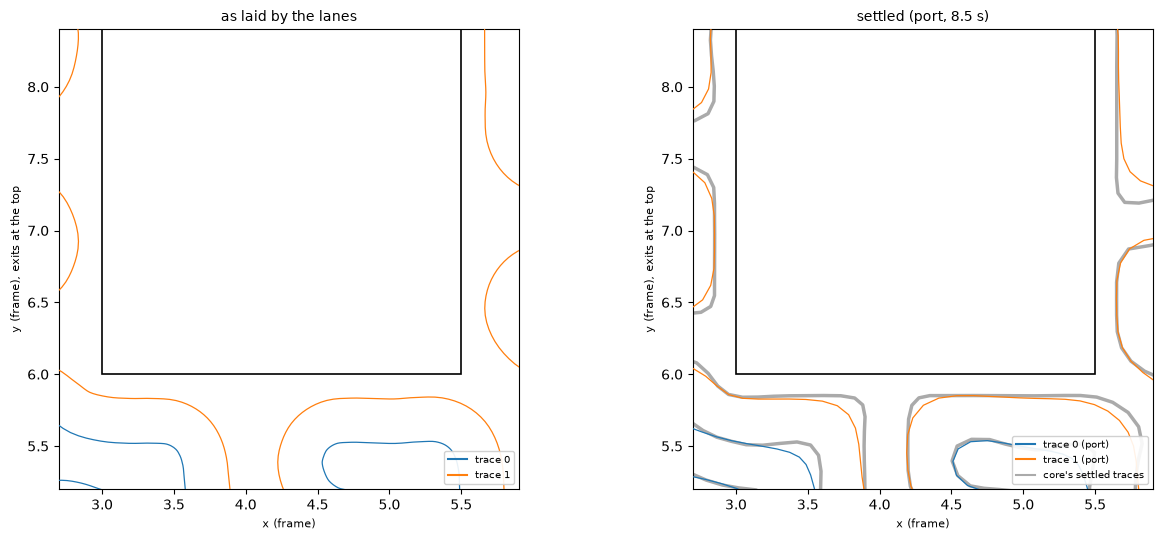

 laid: least gap 0.2993 mm (pitch 0.3), largest hole 0.141 mm², lengths [143.0, 143.6] mm
 port: least gap 0.2974 mm (pitch 0.3), largest hole 0.022 mm², lengths [144.6, 146.8] mm
 core: least gap 0.2974 mm (pitch 0.3), largest hole 0.000 mm², lengths [151.0, 152.8] mm


In [41]:
c = CASES["hole"]
out, dt = settle_run(c)
s = c["settle"]
laid = [np.asarray(x) for x in s["lines"]]
fr, fmask, fzones, _ = frame_geoms(c)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, ls, title in ((axes[0], laid, "as laid by the lanes"), (axes[1], out, f"settled (port, {dt:.1f} s)")):
    for t, tr in enumerate(ls):
        line(ax, tr, color=TRACE[t], lw=0.9, zorder=3)
    base(ax, fmask, fzones, title)
    frame_axes(ax)
    zoom(ax, (4.3, 6.8), 1.6)
for tr in s["out"]:
    line(axes[1], tr, color="#AAAAAA", lw=2.5, zorder=2)
legend(axes[0], [("line", TRACE[0], "trace 0"), ("line", TRACE[1], "trace 1")], loc="lower right")
legend(axes[1], [("line", TRACE[0], "trace 0 (port)"), ("line", TRACE[1], "trace 1 (port)"),
                 ("line", "#AAAAAA", "core's settled traces")], loc="lower right")
plt.tight_layout()
plt.show()
for name, ls in (("laid", laid), ("port", out), ("core", [np.asarray(x) for x in s["out"]])):
    gap, hole, lens = settle_metrics(ls, s)
    print(f"{name:>5}: least gap {gap:.4f} mm (pitch {s['pitch']}), largest hole {hole:.3f} mm², lengths {[round(x, 1) for x in lens]} mm")

## 4. End to end, and verification

Each case runs through `generate` (the verbatim driver) on the ports, with the curve graph built from the recorded cells. Every call into the core is then compared with the original's recording:

| step | compared | tolerance |
|---|---|---|
| cells (3.4) | the port's own cells against the core's, as shapes | 1e-6 mm (Hausdorff) |
| graph (3.3–3.10) | inputs (segments, borders, openings, key) and output (curves, cells, lost) | 1e-12 |
| relaxation (3.11) | inputs (curve, stem, target, edge, borders, offset) and output | exact |
| lanes (3.12) | inputs (curve, stem split, rails) and the traces | exact |
| unloop, open (3.12) | the opened traces handed to settling | exact |
| settling (3.13) | simplified: ends unchanged, least gap within 0.5 % of the core's, largest hole ≤ 0.05 mm², lengths within 8 % | properties |
| drawing (3.14) | the port's drawing of the core's settled traces | exact |

The drawing step cannot be checked within the chained run, because its input there is the simplified settling's output, so it is checked on the recorded input. The final traces of the chained run differ from the original's for the same reason. They are checked by the mesh's own invariants: every trace leaves and returns through its exit, keeps the pitch (at least 98 %) from other traces, and no region is left unreached.

In [42]:
TOL = 1e-12


def close(a, b, tol=TOL):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return a.shape == b.shape and (a.size == 0 or float(np.max(np.abs(a - b))) <= tol)


def verify(name):
    c = CASES[name]
    i = c["input"]
    res = {}
    res["cells"] = all(a == b and w <= 1e-6 for gr in c["graphs"] for a, b, w in cells_check(gr))
    core.reset([gr["cells"] for gr in c["graphs"]])
    t0 = time.perf_counter()
    m = generate(geom(i["mask"]), [tuple(e) for e in i["exits"]], i["side"], i["traces"], i["pitch"], seed=i["seed"],
                 zones=[geom(z) for z in i["zones"]], arcs=i["arcs"],
                 partitions=[geom(p["area"]) for p in c["partitions"]], stems=[p["reach"] for p in c["partitions"]])
    took = time.perf_counter() - t0
    calls = core.calls
    res["graph"] = len(calls["graph"]) == len(c["graphs"]) and all(
        [s["region"] for s in mine["segments"]] == [r for r, _ in gr["segments"]]
        and all(all(close(x, y) for x, y in zip(s["domain"], rs)) for s, (_, rs) in zip(mine["segments"], gr["segments"]))
        and [(a, b) for a, b, _ in mine["borders"]] == [(a, b) for a, b, _ in gr["borders"]]
        and all(close(x, y) for (_, _, l1), (_, _, l2) in zip(mine["borders"], gr["borders"]) for x, y in zip(l1, l2))
        and close(mine["openings"], gr["openings"]) and mine["key"].hex() == gr["key"]
        and mine["ncells"] == gr["ncells"] and mine["lost"] == gr["lost"]
        and all(close(p, q[0]) and list(r) == q[1] for (p, r), q in zip(mine["curves"], gr["curves"]))
        for mine, gr in zip(calls["graph"], c["graphs"]))
    res["relax"] = len(calls["relax"]) == len(c["relax"]) and all(
        close(mine["curve"], r["curve"]) and close(mine["stem"], r["stem"]) and mine["target"] == r["target"]
        and close(mine["edge"], r["edge"]) and close(mine["borders"], r["borders"]) and close(mine["offset"], r["offset"])
        and mine["k"] == r["k"] and close(mine["out"], r["out"], 0.0)
        for mine, r in zip(calls["relax"], c["relax"]))
    res["lanes"] = len(calls["lanes"]) == len(c["lanes"]) and all(
        close(mine["p"], L["p"], 0.0) and mine["k"] == L["k"] and mine["exact"] == L["exact"]
        and all(close(a, b, 0.0) for a, b in zip(mine["out"], L["out"]))
        for mine, L in zip(calls["lanes"], c["lanes"]))
    first = calls["settle"][0]
    res["unloop, open"] = all(close(a, b, 0.0) for a, b in zip(first["lines"], c["settle"]["lines"]))
    s = c["settle"]
    settled = calls["settle"][-1]["out"]
    gap, hole, lens = settle_metrics(settled, s)
    cgap, chole, clens = settle_metrics(s["out"], s)
    res["settling (simplified)"] = (all(close(a[0], b[0]) and close(a[-1], b[-1]) for a, b in zip(settled, s["out"]))
                                    and gap >= 0.995 * cgap and hole <= 0.05
                                    and all(abs(x / y - 1) <= 0.08 for x, y in zip(lens, clens)))
    res["drawing"] = output_check(c)[0]
    tr = [LineString(t) for t in m.traces]
    ends_ok = all(close(t[0], u[0], 1e-6) and close(t[-1], u[-1], 1e-6) for t, u in zip(m.traces, c["mesh"]["traces"]))
    least = min(a.distance(b) for j, a in enumerate(tr) for b in tr[j + 1:])
    res["mesh invariants"] = ends_ok and least >= 0.98 * i["pitch"] and m.unreached == 0
    return res, m, took


results = {}
t_all = time.perf_counter()
for name in CASES:
    results[name] = verify(name)
    print(f"{name:>11}: {results[name][2]:.1f} s", flush=True)
print(f"verified {len(results)} cases in {time.perf_counter() - t_all:.0f} s\n")
keys = list(next(iter(results.values()))[0])
print(f"{'case':>11}  " + "  ".join(f"{k:>14}" for k in keys))
for name, (res, _, _) in results.items():
    print(f"{name:>11}  " + "  ".join(f"{'ok' if res[k] else 'MISMATCH':>14}" for k in keys))
assert all(all(r.values()) for r, _, _ in results.values()), "the port does not match the recording"
print("\nall checks pass")

        one: 9.4 s


       fold: 17.4 s


 partitions: 25.0 s


       hole: 16.1 s


       arcs: 20.7 s


verified 5 cases in 126 s

       case           cells           graph           relax           lanes    unloop, open  settling (simplified)         drawing  mesh invariants
        one              ok              ok              ok              ok              ok              ok              ok              ok
       fold              ok              ok              ok              ok              ok              ok              ok              ok
 partitions              ok              ok              ok              ok              ok              ok              ok              ok
       hole              ok              ok              ok              ok              ok              ok              ok              ok
       arcs              ok              ok              ok              ok              ok              ok              ok              ok

all checks pass


The port's meshes, and the original's for comparison. Since the port starts from the recorded cells, everything up to settling is identical; the visible differences come from the simplified settling. The last row runs the port **entirely on its own**, with its own cells (no recording), on the two-partition case: a different but equally valid mesh, because shapely's vertex order changes the random matching (3.4).

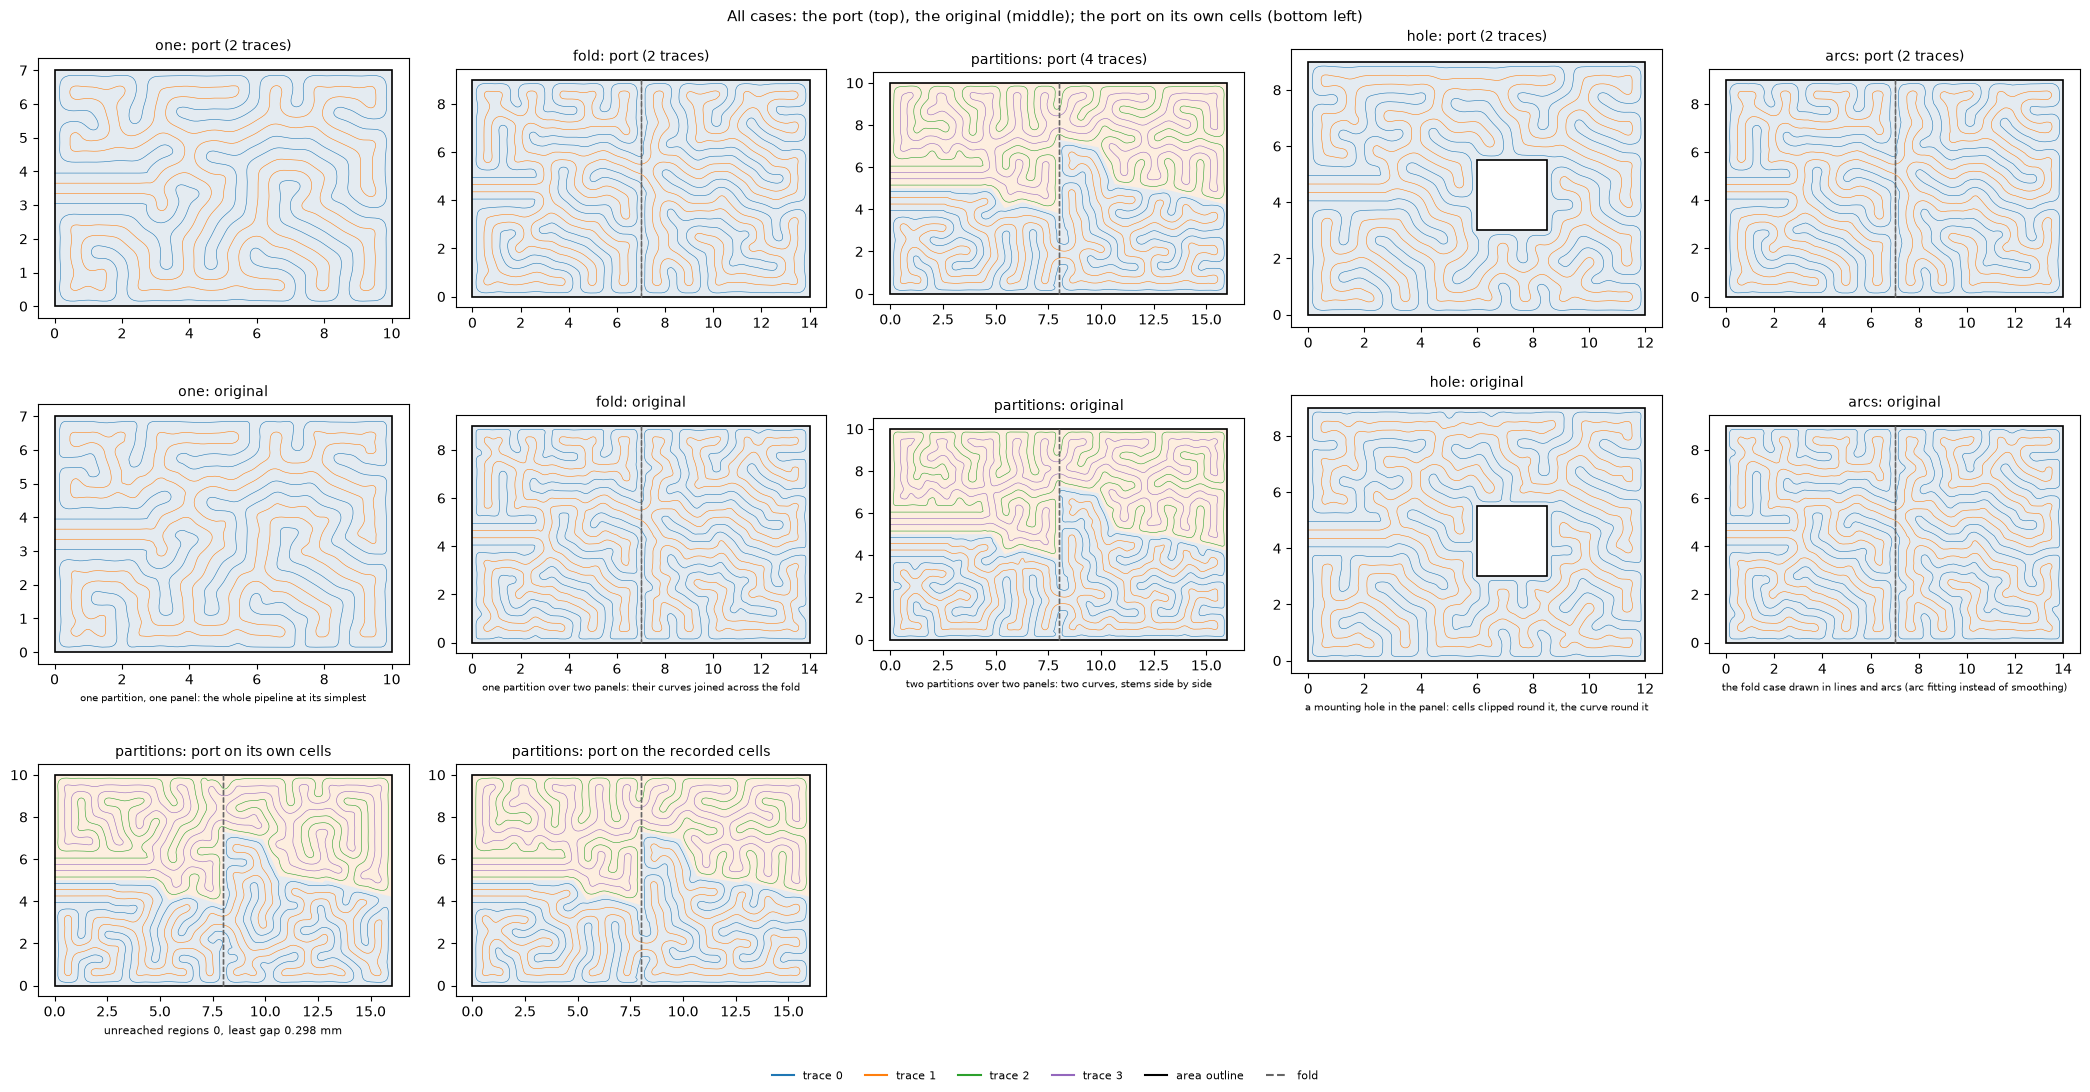

In [43]:
names = list(CASES)
fig, axes = plt.subplots(3, len(names), figsize=(4.2 * len(names), 11))
for j, name in enumerate(names):
    c = CASES[name]
    res, m, _ = results[name]
    show_mesh(axes[0, j], c, m.traces, f"{name}: port ({len(m.traces)} traces)", lw=0.4)
    show_mesh(axes[1, j], c, c["mesh"]["traces"], f"{name}: original", lw=0.4)
    axes[1, j].set_xlabel(c["note"], fontsize=7)
own = "partitions"
c = CASES[own]
i = c["input"]
core.reset()
m_own = generate(geom(i["mask"]), [tuple(e) for e in i["exits"]], i["side"], i["traces"], i["pitch"], seed=i["seed"],
                 zones=[geom(z) for z in i["zones"]], arcs=i["arcs"],
                 partitions=[geom(p["area"]) for p in c["partitions"]], stems=[p["reach"] for p in c["partitions"]])
tr = [LineString(t) for t in m_own.traces]
least = min(a.distance(b) for j, a in enumerate(tr) for b in tr[j + 1:])
show_mesh(axes[2, 0], c, m_own.traces, f"{own}: port on its own cells", lw=0.4)
axes[2, 0].set_xlabel(f"unreached regions {m_own.unreached}, least gap {least:.3f} mm", fontsize=8)
show_mesh(axes[2, 1], c, results[own][1].traces, f"{own}: port on the recorded cells", lw=0.4)
for ax in axes[2, 2:]:
    ax.axis("off")
handles = [plt.Line2D([], [], color=TRACE[k], label=f"trace {k}") for k in range(4)] + [
    plt.Line2D([], [], color="black", label="area outline"), plt.Line2D([], [], color=FOLD, ls="--", label="fold")]
fig.legend(handles=handles, loc="lower center", ncol=6, fontsize=8, frameon=False)
plt.suptitle("All cases: the port (top), the original (middle); the port on its own cells (bottom left)", fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 5. Closing notes

**Complexity** (`V` curve vertices, about the area over a quarter spacing; `C` cells):

| step | cost |
|---|---|
| cells | O(C log C) per Lloyd iteration (bisector clipping against nearby seeds via the point grid) |
| graph, matching | Edmonds' algorithm O(C³) worst case, near linear from the greedy start in practice; refinement and merging O(C) passes |
| zoning | per border, candidate pairs of edges along it: O(b²) for b edges near the border |
| relaxation | O(V) per step (grid look-ups), about 20 + 150 + 100 steps |
| lanes | O(V · fine) |
| settling | O(traces' vertices) per step, 40 steps plus hole filling; the core's heaviest part |
| drawing | O(vertices · `SPAN`) for the greedy fit; the room look-ups via segment buckets |

In Rust the whole layer takes well under a second for these cases. The port takes 10–40 s per case, most of it in relaxation, settling and drawing.

**Known limitations** (of the algorithm, as seen here):

- The graph is built on random cells. A try can leave a cycle unjoined in a narrow spot; the core retries up to 8 times, then `generate` reassigns or merges regions, and the PCB layout retries the layer with a salted seed.
- Offsets in tight bends lose vertices and leave small loops, which are cut out. Where runs part, the ribbon's outer traces leave gaps a little under a ribbon wide; settling fills most of them, and the core's hole filling the rest.
- Matching the traces' lengths only straightens bends (never lengthens), so a partition's traces end up within `MATCH_BAND` pitches of each other, not equal.
- The port: settling is simplified (3.13), and cell clipping differs from the core's in the last bits (3.4). Everything else reproduces the core exactly.

**Where each step lives**:

| step | Python (`src/yanartas_pillowbox/sfc.py`) | Rust core (`rust/core/src`) |
|---|---|---|
| driver | `generate`, `_Frame` | — |
| 3.2 regions | `_regions`, `_split` | — |
| 3.3 segments, borders | `_curve`, `_shared_borders` | `graph::curve` (entry) |
| 3.4 cells | — | `graph.rs`: `seeds`, `voronoi`, `cells`, `split_holes` |
| 3.5 graph, stem | — | `graph.rs`: `Graph`, `build`, `stem` |
| 3.6 initial cycles | — | `graph.rs`: `two_factor`, `matching` |
| 3.7 refinement | — | `graph.rs`: `centres`, `covers` |
| 3.8 merging | — | `graph.rs`: `merge`, `double` |
| 3.9 zoning | — | `graph.rs`: `join_segments`, `connect`, `split_at`, `border_edges` |
| 3.10 fallbacks | `_reassigned`, `_merged`, `_lost` | — |
| 3.11 relaxation | `_relax`, `_borders` | `curve.rs`: `relax`, `grow` and helpers |
| 3.12 lanes | `_lanes`, `_unlooped`, `_opened` | `lanes.rs`: `lanes`, `balance`, `unloop` |
| 3.13 settling | `_settle`, `_params` | `settle.rs`, `traces.rs`, `density.rs` |
| 3.14 drawing | `_output` | `arcs.rs`: `smooth_all`, `fit_all` |
| bindings | `_core` | `rust/python/src/lib.rs` (Python), `rust/wasm/src/lib.rs` (browser) |

The design rationale is also in `ARCHITECTURE.md` (Space-filling curve), and the tests are in `tests/test_sfc.py` and `rust/core/tests/`.